# Spike Sorting: Feature Extraction, Clustering, and Validation

**Hesam Ghanbarzadeh | Computational Neuroscience**  
*Original course project: 2019 · Python benchmark and validation: 2026*

This notebook examines spike detection, waveform representation, and clustering on five simulated extracellular recordings with reference annotations. The original 2019 course report covered four clustering-method families. The nine-method Python benchmark was developed and validated in 2026, extending the scope of that earlier work.

I compare K-means, fuzzy C-means, SOM, G-means, GMM-ICL, X-means, PG-means, HDBSCAN, and DP-means. The analysis tracks the number of detected events, the inferred cluster count, agreement with reference annotations, and the consequences of changing features or detection settings. The implementations of G-means, X-means, and DP-means include specified adaptations, described in the methods below.

**Reference run — 22 November 2026.** The checkpointed execution (`20261122T060055_422939Z`) used scikit-learn 1.6.1 and completed all five recordings. The accompanying results archive, `FULL_VALIDATION_STATUS.json`, and run manifest contain the saved outputs and completion record.


## 0. Environment

The reference run used a Google Colab CPU runtime with Python 3.13.18. Its main dependencies are NumPy, SciPy, scikit-learn, pandas, and Matplotlib; the recorded core versions are listed in `requirements.txt` (including scikit-learn 1.6.1).

The five MATLAB recordings are processed individually. Checkpoints are saved during the longer validation stages so that an interrupted Colab session can be resumed.


In [1]:
import os,sys,importlib.util
for mod in ('numpy','pandas','scipy','sklearn','matplotlib','nbformat'):
    if importlib.util.find_spec(mod) is None:
        %pip -q install "numpy>=1.24" "pandas>=2.0" "scipy>=1.11" "scikit-learn>=1.3" "matplotlib>=3.6" "nbformat>=5.8"
import sklearn, numpy, scipy, pandas
assert tuple(map(int,sklearn.__version__.split('.')[:2])) >= (1,3), 'Requires sklearn>=1.3 for HDBSCAN'
print('Runtime versions:',dict(python=sys.version.split()[0],numpy=numpy.__version__,scipy=scipy.__version__,sklearn=sklearn.__version__,pandas=pandas.__version__))
# The reference run used scikit-learn 1.6.1.
ARCHIVED_SKLEARN_VERSION = '1.6.1'
SKLEARN_VERSION_MATCH = sklearn.__version__ == ARCHIVED_SKLEARN_VERSION
if not SKLEARN_VERSION_MATCH:
    print(f'REPRODUCIBILITY WARNING: archived scikit-learn {ARCHIVED_SKLEARN_VERSION}, '
          f'active version {sklearn.__version__}. HDBSCAN scores may differ. '
          f'For numerical comparison, install scikit-learn=={ARCHIVED_SKLEARN_VERSION} '
          'in a fresh runtime and restart the kernel before Run all.')


Runtime versions: {'python': '3.13.18', 'numpy': '2.4.6', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'pandas': '2.2.3'}


## 1. Recordings and settings

Place `simulation_1.mat` through `simulation_5.mat` in `MyDrive/Computational Neuroscience/`, or set `DATA_DIR_OVERRIDE` to a different folder. The configuration below specifies the detection threshold, waveform window, feature extraction, candidate cluster counts, and validation sweeps.

The archived benchmark used `DATASETS=(1, 2, 3, 4, 5)` and `FULL_VALIDATION=True`. For a quick environment check, use `DATASETS=(1,)` with `FULL_VALIDATION=False`. Each execution has its own run-stamped output directory, preserving existing results.


In [2]:
from pathlib import Path
import os

# Read the simulation files from the configured Drive folder.
DRIVE_FOLDER_NAME = 'Computational Neuroscience'
DATA_DIR_OVERRIDE = None  # Optional local input directory.
DATASETS = (1, 2, 3, 4, 5)  # Use (1,) for a one-recording smoke test.
FULL_VALIDATION = True  # Run all 10-seed stability, parameter, threshold, polarity, alignment, and null controls.
# Each recording has an independent checkpointed validation cell to avoid a single long Colab cell.
# Set to False only for an explicitly labeled exploratory quick run.
SAVE_RESULTS_ZIP_TO_DRIVE = True  # Save results under a new run stamp without replacing earlier archives.
if not DATASETS or len(DATASETS) != len(set(DATASETS)) or not all(i in (1, 2, 3, 4, 5) for i in DATASETS):
    raise ValueError('DATASETS must be a nonempty unique subset of (1,2,3,4,5)')
INPUT_FILES = [f'simulation_{i}.mat' for i in DATASETS]
# A run-specific local directory prevents residual full/standard outputs mixing between executions.
from datetime import datetime, timezone
RUN_STAMP = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
# To resume in the same Colab runtime, set RESUME_RUN_STAMP to the previous printed stamp.
RESUME_RUN_STAMP = None
if RESUME_RUN_STAMP is not None:
    RUN_STAMP = str(RESUME_RUN_STAMP)
OUTPUT_DIR = (Path('/content') if Path('/content').is_dir() else Path.cwd()) / f'SpikeSorting_2019_v3_{RUN_STAMP}'

def _has_all_files(folder):
    folder = Path(folder)
    return folder.is_dir() and all((folder / name).is_file() for name in INPUT_FILES)

def _missing_files(folder):
    return [name for name in INPUT_FILES if not (Path(folder) / name).is_file()]

DRIVE_DATA_DIR = None
if DATA_DIR_OVERRIDE is not None:
    DATA_DIR = Path(DATA_DIR_OVERRIDE).expanduser()
    if not _has_all_files(DATA_DIR):
        raise FileNotFoundError(f'Missing MAT files under {DATA_DIR}: {_missing_files(DATA_DIR)}')
else:
    try:
        from google.colab import drive as colab_drive
    except ImportError:
        # Look for locally available files before mounting Drive.
        candidates = [Path.cwd(), Path('/mnt/data'), Path('/mnt/data/drive_upload')]
        DATA_DIR = next((p for p in candidates if _has_all_files(p)), None)
        if DATA_DIR is None:
            raise FileNotFoundError(
                f'Requested MAT input files not found locally. Checked: {candidates}. '
                'If running in Colab, open this notebook in Google Colab and authorize Drive.')
    else:
        # Mount Drive if the input directory is not available locally.
        colab_drive.mount('/content/drive', force_remount=False)
        DRIVE_DATA_DIR = Path('/content/drive/MyDrive') / DRIVE_FOLDER_NAME
        DATA_DIR = DRIVE_DATA_DIR
        if not _has_all_files(DATA_DIR):
            raise FileNotFoundError(
                f'Unable to find the requested MAT files at {DATA_DIR}. '
                f'Missing: {_missing_files(DATA_DIR)}. '
                'Confirm that Colab uses the same Google account as the Drive folder; '
                'file names must be simulation_1.mat through simulation_5.mat.')

assert _has_all_files(DATA_DIR), 'MAT input preflight failed'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('MAT data source:', DATA_DIR)
print('Output directory:', OUTPUT_DIR, ' | Run ID:', RUN_STAMP)
print(f'All {len(DATASETS)} requested MAT inputs found. Manual upload is unnecessary.')


Mounted at /content/drive
MAT data source: /content/drive/MyDrive/Computational Neuroscience
Output directory: /content/SpikeSorting_2019_v3_20261122T060055_422939Z  | Run ID: 20261122T060055_422939Z
All 5 requested MAT inputs found. Manual upload is unnecessary.


## 1.1. Input checks

The loader checks the expected MAT arrays, recording dimensions, and sampling information before processing. It also compares each input file with its archived SHA-256 digest to establish that the intended simulation was loaded.

Reference annotations use the codes `0`, `1`, and `2`. The initial summaries show their counts before detection and event matching determine which events enter the clustering evaluation.


In [3]:
from scipy.io import loadmat
from IPython.display import display
import pandas as pd
import numpy as np
import hashlib

def _file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

EXPECTED_MAT_SHA256 = {1: 'e559eca84bd0fc75b6543997759caa6fb7720357f75f6cce93fdcb08d5be657b', 2: '34c4df15348aa2f3e7b98ce4cccb4cf5a5743d76010f2eaa2de7b6e02c3f396e', 3: '2819b28b8896e7e068c47216a5a9363bd159ac33c184d35595302cf6de0275ad', 4: 'ed83503c57400704fde7b8ab158ec5f3c1acac70b9f58a4888c9bf8bce89dad1', 5: 'c004968e4278dc821f7b5079088145ceba3637ab7eb573269a37a287ad5e023e'}
# Exact fingerprints verify the same five source simulations as the archived benchmark.
audit_rows = []
for dataset_id in DATASETS:
    path = DATA_DIR / f'simulation_{dataset_id}.mat'
    mat = loadmat(path, squeeze_me=True, variable_names=
                  ['samplingInterval', 'data', 'spike_times', 'spike_class'])
    trace = np.asarray(mat['data']).ravel()
    times = np.asarray(mat['spike_times']).ravel()
    labels = np.asarray(mat['spike_class']).ravel()
    if len(times) != len(labels):
        raise ValueError(f'Reference event/label length mismatch in {path.name}')
    cls, counts = np.unique(labels, return_counts=True)
    cnt = dict(zip(cls.tolist(), counts.tolist()))
    interval = float(np.asarray(mat['samplingInterval']).squeeze())
    actual_sha256 = _file_sha256(path)
    if actual_sha256 != EXPECTED_MAT_SHA256[dataset_id]:
        raise ValueError(f'{path.name}: SHA-256 mismatch with the archived input. '
                         'Do not compare outputs as the same experiment.')
    audit_rows.append(dict(
        dataset=path.stem, samples=len(trace), samplingInterval=interval,
        duration_s_if_interval_ms=round(len(trace) * interval / 1000, 3),
        reference_events=len(times), label_codes=str(cls.tolist()),
        label_0=cnt.get(0,0), label_1=cnt.get(1,0), label_2=cnt.get(2,0),
        signal_std=round(float(np.std(trace)),3),
        sha256_short=actual_sha256[:12]))
DATASET_AUDIT = pd.DataFrame(audit_rows)
display(DATASET_AUDIT)
assert DATASET_AUDIT.sha256_short.nunique() == len(DATASETS), 'Duplicate source files detected'
print(f'All {len(DATASETS)} input files have distinct, archive-matched SHA-256 fingerprints.')
print('Reference codes in the input: 0, 1, 2.')
print('Sampling interval interpreted as milliseconds.')


,dataset,samples,samplingInterval,duration_s_if_interval_ms,reference_events,label_codes,label_0,label_1,label_2,signal_std,sha256_short
0,simulation_1,2880000,0.041667,120.0,2415,"[0, 1, 2]",2179,126,110,7.586,e559eca84bd0
1,simulation_2,2880000,0.041667,120.0,3214,"[0, 1, 2]",2156,529,529,9.076,34c4df15348a
2,simulation_3,2880000,0.041667,120.0,3283,"[0, 1, 2]",2195,565,523,7.546,2819b28b8896
3,simulation_4,2880000,0.041667,120.0,3193,"[0, 1, 2]",2143,509,541,7.669,ed83503c5740
4,simulation_5,2880000,0.041667,120.0,2328,"[0, 1, 2]",2210,62,56,7.375,c004968e4278


All 5 input files have distinct, archive-matched SHA-256 fingerprints.
Reference codes in the input: 0, 1, 2.
Sampling interval interpreted as milliseconds.


## 2. Clustering methods and model selection

A large separation statistic can arise even when a distribution contains no distinct clusters. Consider a standard normal variable divided at its median. The two groups have means \(\pm\sqrt{2/\pi}\) and variance \(1-2/\pi\), giving the Ashman-like separation statistic

\[
D = \frac{2\sqrt{2/\pi}}{\sqrt{1-2/\pi}} \approx 2.65.
\]

The original normal distribution is unimodal. I therefore record separation as a diagnostic and use explicit model-selection criteria to assess candidate splits. The G-means implementation combines projected Anderson–Darling tests with a local soft-ICL improvement; X-means evaluates candidate splits through penalized GMM-BIC. DP-means follows a fixed penalty path selected without reference labels.

The default waveform representation uses three levels of `db4` wavelets, KS-derived weights, and regularized PCA scaling. Additional comparisons examine selected `db4` and Haar coefficients and ordinary waveform PCA. GMM order selection records an approximate entropy-adjusted ICL alongside the raw BIC.


In [4]:
"""Spike-sorting comparison for five simulated extracellular recordings (2019).

The nine methods share detection and waveform preprocessing. The source
annotations are used for evaluation after clustering. Reference spike times
are interpreted as approximate event onsets."""
from __future__ import annotations
import json, os, platform, hashlib, warnings, time
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from math import gcd
from typing import Any

import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, find_peaks, resample_poly
from scipy.stats import anderson, norm, kstest
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score, silhouette_score

METHODS = ('K-means','Fuzzy C-means','SOM','G-means','GMM-ICL','X-means','PG-means','HDBSCAN','DP-means')

@dataclass(frozen=True)
class Config:
    dt_unit: str = 'ms'  # Sampling interval is interpreted in milliseconds.
    low_hz: float = 300.0
    high_hz: float = 3000.0
    filter_order: int = 3
    polarity: str = 'positive'
    threshold_sigma: float = 4.0
    refractory_detect_ms: float = 0.8
    pre_samples: int = 30
    waveform_samples: int = 70
    n_pcs: int = 5  # PCA dimension for the weighted db4 representation.
    feature_method: str = "db4_ks_weighted_pca"  # Default waveform representation.
    wavelet_coeffs: int = 10  # Number of selected wavelet coefficients.
    fixed_k: int = 3  # Fixed-K setting for the three annotation categories.
    max_k: int = 8
    seed: int = 2019
    # Onset-to-peak matching window (samples).
    # Window limits reflect the signal timing.
    onset_peak_min_samples: int = 12
    onset_peak_max_samples: int = 36
    onset_peak_center_samples: int = 23
    fcm_m: float = 1.4
    fcm_restarts: int = 10
    som_epochs: int = 12
    som_restarts: int = 5
    gmeans_alpha: float = 0.01
    gmeans_min_n: int = 45
    pg_alpha: float = 0.01
    pg_n_projections: int = 4
    pg_holdout: float = 0.30
    pg_max_k: int = 8
    hdbscan_min_cluster_size: int = 22
    hdbscan_min_samples: int = 5
    gmeans_variant: str = 'icl_split_guard'  # Projected Anderson–Darling tests with local ICL split selection.
    pgmeans_variant: str = 'train_dipoles'  # Projection axes from training data; KS tests on holdout events.
    dpmeans_variant: str = 'lambda_path_ch'  # Calinski–Harabasz selection across the fixed penalty grid.
    dp_lambda: float = 10.0  # Penalty used by the basic DP-means option.
    dp_radius_multiplier: float = 1.25  # Multiplier used by the microcluster option.
    dp_lambda_floor: float = 2.5  # Lower bound for the DP-means penalty.
    hdbscan_postassign: bool = True  # Optional noise-point reassignment.
    hdbscan_mahalanobis_radius: float = 4.0
    dp_min_cluster_size: int = 20
    dp_lambda_multipliers: tuple[float,...] = (1.5,2.0,2.25,2.5,2.75,3.0,3.25,4.0,4.5,5.5,6.0)
    xmeans_bic_penalty_factor: float = 2.0  # Split penalty: delta BIC exceeds 2*d*ln(n).
    rpv_ms: float = 1.5
    stability_seeds: int = 10
    sensitivity_thresholds: tuple[float,...] = (3.5, 4.0, 4.5)
    sensitivity_pcs: tuple[int,...] = (2, 3, 5)


def json_safe(v: Any):
    if isinstance(v, dict): return {str(k): json_safe(val) for k, val in v.items()}
    if isinstance(v, (tuple, list)): return [json_safe(val) for val in v]
    if isinstance(v, np.ndarray): return json_safe(v.tolist())
    if isinstance(v, np.generic): return json_safe(v.item())
    if isinstance(v, float) and not np.isfinite(v): return None
    if isinstance(v, Path): return str(v)
    return v


def read_mat(path: Path, cfg: Config) -> dict:
    if not path.exists(): raise FileNotFoundError(f'Missing {path}. Upload all five MAT files.')
    raw = loadmat(path, variable_names=['data','samplingInterval','startData','spike_times','spike_class'], squeeze_me=True)
    for field in ('data','samplingInterval','spike_times','spike_class'):
        if field not in raw: raise ValueError(f'{path.name} missing {field}')
    x = np.asarray(raw['data'], dtype=np.float64).ravel()
    if x.ndim != 1 or not np.isfinite(x).all(): raise ValueError('Invalid voltage trace')
    dt = float(raw['samplingInterval'])
    if cfg.dt_unit != 'ms': raise ValueError('dt_unit must be explicitly verified; supported working interpretation: ms')
    fs = 1000.0 / dt
    if not (cfg.high_hz < fs/2 and 10000 < fs < 200000): raise ValueError(f'Invalid fs={fs}')
    ref = np.asarray(raw['spike_times'], dtype=np.int64).ravel()
    cls = np.asarray(raw['spike_class'], dtype=np.int32).ravel()
    if len(ref) != len(cls) or np.any(np.diff(ref)<0) or np.min(ref)<0 or np.max(ref)>len(x)+1:
        raise ValueError('Invalid reference times or class array')
    return dict(name=path.stem, x=x, fs=fs, dt_ms=dt, ref=ref, cls=cls,
                duration_s=len(x)/fs, startData=float(raw.get('startData',0)),
                source_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                n_samples=len(x), reference_hist={int(k):int(v) for k,v in zip(*np.unique(cls,return_counts=True))})


def detect(rec: dict, cfg: Config) -> dict:
    sos = butter(cfg.filter_order, [cfg.low_hz,cfg.high_hz], btype='bandpass', fs=rec['fs'], output='sos')
    voltage = sosfiltfilt(sos, rec['x'])
    center = np.median(voltage)
    sigma = float(np.median(np.abs(voltage-center))/0.6744897501960817)
    if sigma <= 0 or not np.isfinite(sigma): raise ValueError('Invalid median absolute deviation')
    if cfg.polarity=='positive': y = voltage
    elif cfg.polarity=='negative': y = -voltage
    elif cfg.polarity=='absolute': y = np.abs(voltage)
    else: raise ValueError('polarity must be positive, negative or absolute')
    distance = max(1,round(cfg.refractory_detect_ms*1e-3*rec['fs']))
    peaks, props = find_peaks(y, height=cfg.threshold_sigma*sigma, distance=distance)
    pre = cfg.pre_samples; post = cfg.waveform_samples-pre-1
    valid = (peaks>=pre)&(peaks+post<len(voltage))
    peaks = peaks[valid]
    win = np.arange(-pre,post+1)
    waves = voltage[peaks[:,None]+win[None,:]].astype(np.float32)
    # Reload and filter traces as needed to reduce memory use.
    return dict(peaks=peaks.astype(np.int32), waves=waves, sigma=sigma,
                threshold=float(cfg.threshold_sigma*sigma), n_detected=len(peaks),
                detector_spacing_samples=distance)


def _haar_coefficients(waves: np.ndarray) -> np.ndarray:
    """Orthonormal Haar coefficients from anti-aliased, 64-sample waveforms.

    The 70-sample window is resampled to 64 points before transformation.
    Coefficients are ordered from fine to coarse, followed by the final DC term."""
    from math import gcd
    n=int(waves.shape[1]); g=gcd(64,n)
    z=resample_poly(np.asarray(waves,dtype=np.float64),64//g,n//g,axis=1)
    assert z.shape[1]==64, z.shape
    work=z.copy(); out=np.zeros_like(z); offset=0; width=64
    while width>1:
        avg=(work[:,:width:2]+work[:,1:width:2])/np.sqrt(2.)
        dif=(work[:,:width:2]-work[:,1:width:2])/np.sqrt(2.)
        out[:,offset:offset+width//2]=dif
        offset+=width//2; work[:,:width//2]=avg; width//=2
    out[:,-1]=work[:,0]
    return out


# Three waveform representations for the chronological comparison.
# Periodic orthonormal db4 transform on 64-sample waveforms.
# The Haar comparator uses the same resampling step.
_DB4_LOWPASS = np.array([
    -0.010597401784997278, 0.032883011666982945, 0.030841381835986965,
    -0.18703481171909309,-0.02798376941698385,0.6308807679298587,
    0.7148465705529154, 0.2303778133088965], dtype=float)


def _db4_coefficients(waves: np.ndarray, levels: int = 3) -> np.ndarray:
    """Three-level periodic db4 decomposition of 64-sample waveforms: D1, D2, D3, A3."""
    waves = np.asarray(waves, dtype=np.float64)
    if waves.ndim != 2 or waves.shape[1] < 4:
        raise ValueError('Expect a [spikes, waveform_samples] array')
    g = gcd(64, waves.shape[1])
    work = resample_poly(waves, 64//g, waves.shape[1]//g, axis=1)
    h = _DB4_LOWPASS
    high = (-1.0)**np.arange(h.size)*h[::-1]
    details = []
    for _ in range(levels):
        L = work.shape[1]
        if L % 2: raise ValueError('Odd-length DWT level')
        inds = (2*np.arange(L//2)[:,None] + np.arange(h.size)[None,:]) % L
        details.append(work[:,inds] @ high)
        work = work[:,inds] @ h
    return np.concatenate(details+[work], axis=1)


def _ks_non_gaussianity(A):
    """Rank coefficients by the training-set KS distance from a Gaussian reference."""
    mu = A.mean(axis=0); sd = A.std(axis=0)
    z = (A-mu)/np.maximum(sd, 1e-12)
    D = np.array([float(kstest(z[:,j], 'norm').statistic)
                  for j in range(A.shape[1])], dtype=float)
    D[sd < max(1e-12,1e-5*np.median(sd))] = 0.
    return D, mu, sd


def features(waves: np.ndarray, n_pcs: int, mode: str = 'db4_ks_weighted_pca',
             wavelet_coeffs: int = 10, fit_fraction: float = .70) -> tuple[np.ndarray,dict]:
    """Fit each feature transform using chronological training events.

    The available representations are weighted db4 coefficients followed by PCA,
    selected db4 or Haar coefficients, and waveform PCA. KS distance measures
    departure from normality, which may reflect features other than multimodality.
    The fitted transform is applied unchanged to held-out events."""
    waves = np.asarray(waves, dtype=np.float64)
    if waves.ndim!=2 or len(waves)<max(40,n_pcs+2) or not np.isfinite(waves).all():
        raise ValueError('Too few or non-finite spike waveforms')
    cut = max(30,min(len(waves)-5,int(fit_fraction*len(waves))))
    if mode=='pca':
        m = PCA(n_components=int(n_pcs),svd_solver='full').fit(waves[:cut])
        score=m.transform(waves)
        scaler=StandardScaler().fit(score[:cut]);X=scaler.transform(score)
        meta=dict(feature_method='Waveform PCA baseline',n_features=n_pcs,
                  pca_variance=float(m.explained_variance_ratio_.sum()),
                  each_pc_variance=m.explained_variance_ratio_.tolist(),
                  feature_fit_spikes=cut)
    elif mode in ('db4_ks_weighted_pca','db4_ks','haar_ks','wavelet_ks'):
        coeff = (_db4_coefficients(waves) if mode.startswith('db4')
                 else _haar_coefficients(waves))
        D, mu, sd = _ks_non_gaussianity(coeff[:cut])
        if mode in ('haar_ks','wavelet_ks'):
            D[-1]=0.  # Drop the coarse Haar DC coefficient.
        if mode=='db4_ks_weighted_pca':
            # Rank coefficients using training waveforms.
            weights=D**2
            if np.count_nonzero(weights)>0:
                weighted=((coeff-mu)/np.maximum(sd,1e-12))*weights
            else: raise ValueError('All coefficients are constant')
            m=PCA(n_components=int(n_pcs),svd_solver='full').fit(weighted[:cut])
            score=m.transform(weighted)
            # Apply Tikhonov-regularized PCA scaling learned on training events.
            # Reuse those scales for the test interval.
            train_var=np.var(score[:cut],axis=0,keepdims=True)
            reg_fraction=0.06  # Relative scale regularization.
            reg_sd=np.sqrt(train_var+reg_fraction*max(float(train_var[0,0]),1e-12))
            reg_sd=reg_sd/max(float(reg_sd[0,0]),1e-12)
            pc1_sd=max(float(np.std(score[:cut,0])),1e-12)
            X=(score-score[:cut].mean(axis=0,keepdims=True))/(pc1_sd*reg_sd)
            meta=dict(pca_score_scale_rule='train-only Tikhonov-regularized relative whitening',
                      pca_pc1_train_sd=pc1_sd,
                      pca_regularization_ratio=reg_fraction,
                      pca_relative_axis_sd=reg_sd.ravel().round(9).tolist(),
                      feature_method='db4 DWT + KS^2-weighted PCA (adapted)',
                      n_features=n_pcs, wavelet='db4', levels=3,
                      ks_weights_power=2, pca_variance=float(m.explained_variance_ratio_.sum()),
                      each_pc_variance=m.explained_variance_ratio_.tolist(),
                      ks_ranked_indices=np.argsort(-D,kind='stable')[:10].tolist(),
                      ks_ranked_D=np.sort(D)[-10:][::-1].round(6).tolist(),
                      feature_fit_spikes=cut)
        else:
            usable=D.copy();usable[usable<=0]=-np.inf
            chosen=np.argsort(-usable,kind='stable')[:int(wavelet_coeffs)]
            if len(chosen)!=int(wavelet_coeffs) or not np.isfinite(usable[chosen]).all():
                raise ValueError('Insufficient variable wavelet coefficients')
            X=StandardScaler().fit(coeff[:cut,chosen]).transform(coeff[:,chosen])
            # Normalize KS weights relative to the training-set maximum.
            ks_scale=D[chosen]/max(float(np.max(D[chosen])),1e-12)
            X=X*ks_scale[None,:]
            label=('db4' if mode=='db4_ks' else 'Haar (historical)')
            meta=dict(feature_method=label+' DWT + KS-D top coefficients',
                      n_features=int(wavelet_coeffs),wavelet=label,
                      levels=(3 if mode=='db4_ks' else 6),
                      wavelet_selected_indices=chosen.tolist(),
                      wavelet_selected_KS_D=D[chosen].round(6).tolist(),
                      wavelet_relative_ks_weights=ks_scale.round(6).tolist(),
                      pca_variance=None, each_pc_variance=[],
                      feature_fit_spikes=cut)
    else: raise ValueError(f'Unknown feature mode: {mode}')
    if X.shape[0]!=len(waves) or not np.isfinite(X).all():
        raise ValueError('Invalid output of feature transformer')
    return np.asarray(X,dtype=np.float64),meta


def fcm(X,k,seed,m=2.0,restarts=8,max_iter=400,tol=1e-6):
    """Fuzzy c-means initialized using K-means++ centers.

    Memberships are normalized, and centers are recomputed after convergence.
    The restart with the lowest fuzzy objective is retained."""
    if m<=1: raise ValueError('FCM fuzzifier must be >1')
    best=None
    for r in range(restarts):
        objective_trace=[]
        km=KMeans(n_clusters=k,init='k-means++',n_init=1,max_iter=15,
                  random_state=seed+101*r).fit(X)
        d2=np.sum((X[:,None,:]-km.cluster_centers_[None,:,:])**2,axis=2)
        inv=np.maximum(d2,1e-12)**(-1/(m-1))
        U=inv/inv.sum(axis=1,keepdims=True)
        for it in range(max_iter):
            Um=U**m
            centers=(Um.T@X)/np.maximum(Um.sum(axis=0)[:,None],1e-12)
            d2=np.sum((X[:,None,:]-centers[None,:,:])**2,axis=2)
            exact=d2<=1e-12
            w=np.maximum(d2,1e-12)**(-1/(m-1))
            Un=w/w.sum(axis=1,keepdims=True)
            isexact=exact.any(axis=1)
            if isexact.any():Un[isexact]=exact[isexact]/exact[isexact].sum(axis=1,keepdims=True)
            change=np.max(np.abs(Un-U));U=Un
            u2=U**m
            ctr=(u2.T@X)/np.maximum(u2.sum(axis=0)[:,None],1e-12)
            objective_trace.append(float(np.sum(u2*np.sum((X[:,None,:]-ctr[None,:,:])**2,axis=2))))
            if change<tol:break
        Um=U**m
        centers=(Um.T@X)/np.maximum(Um.sum(axis=0)[:,None],1e-12)
        obj=float(np.sum(Um*np.sum((X[:,None,:]-centers[None,:,:])**2,axis=2)))
        cand=(obj,U.argmax(axis=1),dict(objective=obj,iterations=it+1,
               membership_sum_max_abs_error=float(np.max(np.abs(U.sum(axis=1)-1))),
               converged=change<tol,objective_trace=objective_trace,init='independent K-means++ restarts'))
        if best is None or obj<best[0]:best=cand
    return best[1],best[2]

def _som_single(X,k,seed,epochs=12):
    """One-dimensional self-organizing map with a final Lloyd refinement.

    The map supplies initial centers for the fixed-K partition."""
    rng=np.random.default_rng(seed)
    w=KMeans(n_clusters=k,n_init=1,max_iter=8,random_state=seed).fit(X).cluster_centers_
    w=w[np.argsort(w[:,0])].copy() # Order prototypes by their PC1 locations.
    grid=np.arange(k);steps=max(1,epochs*len(X));tick=0
    quantization_curve=[]
    for ep in range(epochs):
        for i in rng.permutation(len(X)):
            xi=X[i];bmu=int(np.argmin(((w-xi)**2).sum(axis=1)))
            progress=tick/steps
            alpha=0.20*(0.012/0.20)**progress
            radius=max(.35,max(1,k/2)*(.35/max(1,k/2))**progress)
            h=np.exp(-.5*((grid-bmu)/radius)**2)
            w+=alpha*h[:,None]*(xi-w);tick+=1
        quantization_curve.append(float(np.mean(np.min(np.sum((X[:,None,:]-w[None,:,:])**2,axis=2),axis=1))))
    pure_labels=np.square(X[:,None,:]-w[None,:,:]).sum(axis=2).argmin(axis=1)
    pure_sizes=np.bincount(pure_labels,minlength=k)
    if (pure_sizes==0).any():
        # Initialize K-means when a map unit has no assignments.
        w=KMeans(n_clusters=k,n_init=5,random_state=seed).fit(X).cluster_centers_
    km=KMeans(n_clusters=k,init=w,n_init=1,max_iter=150,random_state=seed).fit(X)
    return km.labels_,dict(epochs=epochs,topology='one-dimensional SOM plus disclosed Lloyd refinement',
                           pure_som_cluster_sizes=pure_sizes.tolist(),quantization_curve=quantization_curve,
                           distortion_final=float(km.inertia_),
                           note='Lloyd stage is included for comparability with other fixed-K procedures')

def som(X,k,seed,epochs=12,restarts=5):
    # Retain the SOM/Lloyd restart with the lowest distortion.
    best=None; trials=[]
    for r in range(restarts):
        lab,meta=_som_single(X,k,seed+101*r,epochs=epochs)
        error=float(meta['distortion_final'])
        trials.append(error)
        if best is None or error<best[0]:
            best=(error,lab,meta,r)
    _,labels,meta,best_restart=best
    meta=dict(meta,som_restarts=int(restarts),restart_distortions=trials,
              chosen_restart=int(best_restart),selection_rule='minimum unsupervised distortion')
    return labels,meta


def _ad_reject(z,alpha):
    try:
        # Use interpolated Anderson–Darling p-values where supported.
        a=anderson(z,dist='norm',method='interpolate')
        return bool(a.pvalue<=alpha),float(a.statistic),float('nan'),float(alpha)
    except TypeError:
        # Fallback for runtimes without interpolated p-values.
        a=anderson(z,dist='norm')
        levels=np.asarray(a.significance_level,dtype=float)/100
        crit=np.asarray(a.critical_values,dtype=float)
        i=int(np.argmin(abs(levels-alpha)))
        return bool(a.statistic>crit[i]),float(a.statistic),float(crit[i]),float(levels[i])


def _ashman_d_2groups(X,labels,centers):
    """Compute the projected two-group Ashman separation statistic."""
    v=centers[1]-centers[0]
    nv=np.linalg.norm(v)
    if nv<1e-12:return 0.0
    z=X@(v/nv)
    a=z[np.asarray(labels)==0];b=z[np.asarray(labels)==1]
    if min(len(a),len(b))<2:return 0.0
    return float(abs(a.mean()-b.mean())/max(np.sqrt(.5*(a.var()+b.var())),1e-12))


def _two_means_candidates(X,seed,min_size=15):
    """Construct standard and upper-tail two-means starting configurations."""
    X=np.asarray(X);n,d=X.shape
    if n<max(2*min_size,10):return []
    mu=X.mean(axis=0)
    r2=np.sum((X-mu)**2,axis=1)
    upper=np.argsort(r2)[-max(min_size,int(np.ceil(.05*n))):]
    base=np.ones(n,dtype=bool);base[upper]=False
    initials=[None]
    if base.any() and len(upper)>0:
        initials.append(np.vstack([X[base].mean(axis=0),X[upper].mean(axis=0)]))
    candidates=[]
    for i,init in enumerate(initials):
        kw={'n_clusters':2,'max_iter':150,'random_state':seed+29*i}
        if init is None:kw.update(init='k-means++',n_init=5)
        else:kw.update(init=init,n_init=1)
        km=KMeans(**kw).fit(X)
        if min(np.bincount(km.labels_,minlength=2))<min_size:continue
        D=_ashman_d_2groups(X,km.labels_,km.cluster_centers_)
        candidates.append(dict(centers=km.cluster_centers_,labels=km.labels_,
                               d=D,inertia=float(km.inertia_),initializer='standard' if i==0 else 'tail'))
    return candidates


def _gmeans_tail_ashman(X,cfg,seed):
    """G-means variant combining projected normality tests and Ashman separation."""
    centers=X.mean(axis=0)[None,:]; labels=np.zeros(len(X),dtype=int)
    decisions=[]; cap=False; k_history=[1]
    for rd in range(cfg.max_k+3):
        candidates=[]; splits=0
        for j,c in enumerate(centers):
            group=X[labels==j]
            remaining=len(centers)-j-1
            if len(group)<cfg.gmeans_min_n or len(candidates)+remaining+2>cfg.max_k:
                candidates.append(c);continue
            attempts=_two_means_candidates(group,seed+rd*23+j,min_size=15)
            checks=[]
            for att in attempts:
                v=att['centers'][1]-att['centers'][0]
                z=group@(v/max(np.linalg.norm(v),1e-12))
                reject,stat,critical,effective_alpha=_ad_reject(z,cfg.gmeans_alpha)
                accept=bool(reject and att['d']>2.0)
                checks.append(dict(ad_stat=stat,ad_critical=critical,
                    ashman_d=att['d'],alpha=effective_alpha,initializer=att['initializer'],
                    inertia=att['inertia'],accepted=accept))
            valid=[(a,ch) for a,ch in zip(attempts,checks) if ch['accepted']]
            if valid:
                # Rank candidate splits by their projected separation evidence.
                a,chosen=min(valid,key=lambda pair:(0 if pair[0]['initializer']=='standard' else 1,pair[0]['inertia']))
                candidates.extend(a['centers']);splits+=1
            else:candidates.append(c)
            decisions.append(dict(round=rd,cluster=j,n=len(group),attempts=checks,
                                  split=bool(valid),selected_initializer=(a['initializer'] if valid else None)))
        centers=np.asarray(candidates)
        if len(centers)>1:
            km=KMeans(n_clusters=len(centers),init=centers,n_init=1,max_iter=150,
                      random_state=seed+rd).fit(X)
            centers,labels=km.cluster_centers_,km.labels_
        k_history.append(int(len(centers)))
        if len(centers)>=cfg.max_k:cap=True
        if splits==0 or cap:break
    return labels,dict(k_cap_hit=cap,iterations=rd+1,ad_tests=decisions,k_history=k_history,
                       variant='AD + Ashman D>2; standard and far-tail two-means starts')



def _gmeans_icl_split_guard(X,cfg,seed):
    """G-means variant combining projected Anderson–Darling tests with local ICL.

    A proposed split is retained when the two-component GMM has lower soft-ICL
    than a one-component fit to the same observations."""
    centers=X.mean(axis=0)[None,:]
    labels=np.zeros(len(X),dtype=np.int32)
    split_log=[];k_history=[1];k_cap_hit=False
    for rd in range(cfg.max_k+3):
        new_centers=[];accepted_splits=0
        for j,c in enumerate(centers):
            group=X[labels==j]
            available=cfg.max_k-(len(new_centers)+(len(centers)-j-1))
            if len(group)<cfg.gmeans_min_n or available<2:
                new_centers.append(c);continue
            attempts=_two_means_candidates(group,seed+23*rd+j,min_size=15)
            valid=[]
            for att in attempts:
                direction=att['centers'][1]-att['centers'][0]
                projection=group@(direction/max(float(np.linalg.norm(direction)),1e-12))
                ad_reject,ad_stat,ad_crit,alpha=_ad_reject(projection,cfg.gmeans_alpha)
                if ad_reject:  # Store Ashman D as a diagnostic; use ICL and AD for split decisions.
                    valid.append((att,ad_stat,ad_crit,alpha))
            if not valid:
                new_centers.append(c);continue
            att,ad_stat,ad_crit,alpha=min(valid,key=lambda entry:
                (entry[0]['initializer']!='standard',entry[0]['inertia']))
            # Compare one- and two-component fits within the candidate cluster.
            one=_gmm(group,1,seed+rd+j,n_init=1)
            two=_gmm(group,2,seed+rd+j,n_init=1)
            prob=two.predict_proba(group)
            entropy=-float(np.sum(prob*np.log(np.clip(prob,1e-12,1))))
            icl_one=float(one.bic(group))
            icl_two=float(two.bic(group)+2.0*entropy)
            accept=bool(icl_two<icl_one)
            split_log.append(dict(round=int(rd),cluster=int(j),n=int(len(group)),
                initializer=att['initializer'],ashman_d=float(att['d']),
                ad_statistic=float(ad_stat),ad_alpha=float(alpha),
                icl_single=icl_one,icl_split=icl_two,delta_icl=float(icl_one-icl_two),
                accepted=accept))
            if accept:
                new_centers.extend(att['centers']);accepted_splits+=1
            else:new_centers.append(c)
        centers=np.asarray(new_centers)
        if len(centers)>1:
            km=KMeans(n_clusters=len(centers),init=centers,n_init=1,max_iter=150,
                      random_state=seed+rd).fit(X)
            centers,labels=km.cluster_centers_,km.labels_
        k_history.append(int(len(centers)))
        if len(centers)>=cfg.max_k:k_cap_hit=True
        if accepted_splits==0 or k_cap_hit:break
    return labels,dict(selected_k=len(centers),k_history=k_history,
        k_cap_hit=k_cap_hit,local_icl_decisions=split_log,
        selection_rule='split iff projected AD rejects normality and canonical local soft-ICL decreases; hard-split D is descriptive only',
        variant='G-means + local soft-ICL split guard (explicit noncanonical hybrid)')

def _gmm(X,k,seed,n_init=1):
    return GaussianMixture(n_components=k,covariance_type='full',
                           reg_covar=1e-3,max_iter=150,n_init=n_init,
                           random_state=seed,init_params='kmeans').fit(X)


def gmm_bic(X,cfg,seed):
    """Select Gaussian mixture order using approximate soft-entropy ICL.

    ICL = BIC + 2H(tau), where H(tau) = -sum(tau_ik * log(tau_ik)).
    The raw BIC and ICL curves are both returned."""
    table=[]; fits=[]
    for k in range(1,min(cfg.max_k,len(X)//20)+1):
        fit=_gmm(X,k,seed,n_init=2)
        bic=float(fit.bic(X))
        tau=fit.predict_proba(X)
        entropy=-float(np.sum(tau*np.log(np.clip(tau,1e-12,1.0))))
        icl=bic+2.0*entropy
        fits.append(fit)
        table.append(dict(k=k,bic=bic,icl=icl,classification_entropy=entropy,
                          converged=bool(fit.converged_)))
    i=int(np.argmin([row['icl'] for row in table]))
    fit=fits[i];best=table[i]['k']
    bic_best=table[int(np.argmin([r['bic'] for r in table]))]['k']
    vals=np.array([r['icl'] for r in table]);margin=(float(np.partition(vals,1)[1]-vals.min()) if len(vals)>1 else np.nan)
    return fit.predict(X),dict(selected_k=best,bic_optimum_k=int(bic_best),
                              delta_icl_to_runner_up=margin,
                              selection_rule='minimum training ICL = BIC + 2*soft classification entropy',
                              k_cap_hit=best==cfg.max_k,bic_table=table,
                              icl_table=table,log_likelihood=float(fit.score(X)))


def _spherical_bic(X,assignment):
    """BIC for spherical components with a shared variance and fitted mixture weights."""
    n,d=X.shape; labels,inv=np.unique(assignment,return_inverse=True);k=len(labels)
    counts=np.bincount(inv)
    centers=np.vstack([X[inv==j].mean(axis=0) for j in range(k)])
    sse=float(np.sum((X-centers[inv])**2))
    sigma2=max(sse/(n*d),1e-9)
    ll=float(np.sum(counts*np.log(counts/n))) - .5*n*d*(np.log(2*np.pi*sigma2)+1)
    nparams=k*d+(k-1)+1
    return -2*ll+nparams*np.log(n)


def xmeans(X,cfg,seed):
    """X-means variant using local penalized GMM-BIC tests and multiple split starts.

    Ashman separation is recorded but does not determine split acceptance."""
    centers=X.mean(axis=0)[None,:];labels=np.zeros(len(X),dtype=int);rounds=[]
    cap=False;k_history=[1]
    for rd in range(cfg.max_k+2):
        cand=[];accepted=0
        for j,c in enumerate(centers):
            ids=np.flatnonzero(labels==j);sub=X[ids]
            available=cfg.max_k-(len(cand)+(len(centers)-j))
            if available<1 or len(sub)<max(45,2*X.shape[1]+15):
                cand.append(c);continue
            attempts=_two_means_candidates(sub,seed+100*rd+j,min_size=15)
            if not attempts:
                cand.append(c);continue
            g1=GaussianMixture(n_components=1,covariance_type='full',reg_covar=.01,
                               random_state=seed,n_init=2).fit(sub)
            bic1=float(g1.bic(sub)); records=[]
            for a in attempts:
                g2=GaussianMixture(n_components=2,covariance_type='full',reg_covar=.01,
                         random_state=seed,n_init=2,means_init=a['centers']).fit(sub)
                gain=bic1-float(g2.bic(sub))
                threshold=float(cfg.xmeans_bic_penalty_factor*X.shape[1]*np.log(len(sub)))
                ok=bool(gain>threshold)  # Ashman D is excluded from the split rule.
                records.append(dict(candidate=a,improvement=gain,threshold=threshold,
                                    bic_two=float(g2.bic(sub)),accepted=ok))
            valid=[z for z in records if z['accepted']]
            if valid:
                best=max(valid,key=lambda z:z['improvement'])
                cand.extend(best['candidate']['centers']);accepted+=1
            else:cand.append(c)
            rounds.append(dict(round=rd,parent=j,n=len(sub),bic_one=bic1,
                split=bool(valid),attempts=[dict(initializer=z['candidate']['initializer'],
                ashman_d=z['candidate']['d'],bic_two=z['bic_two'],delta_bic=z['improvement'],
                threshold=z['threshold'],split=z['accepted']) for z in records]))
        centers=np.asarray(cand)
        if len(centers)>1:
            km=KMeans(n_clusters=len(centers),init=centers,n_init=1,max_iter=150,
                      random_state=seed+rd).fit(X)
            centers,labels=km.cluster_centers_,km.labels_
        k_history.append(int(len(centers)))
        cap=len(centers)>=cfg.max_k
        if accepted==0 or cap:break
    return labels,dict(selected_k=len(centers),k_cap_hit=cap,bic_split_decisions=rounds,
       k_history=k_history,variant='conservative local penalized GMM-BIC split selection; Ashman D reported separately')

def _mixture_projected_cdf(values,unit,fit):
    mu=fit.means_@unit
    if fit.covariance_type!='full': raise ValueError('Require full covariance')
    v=np.einsum('i,kij,j->k',unit,fit.covariances_,unit)
    z=(np.asarray(values)[:,None]-mu[None,:])/np.sqrt(np.maximum(v[None,:],1e-12))
    return norm.cdf(z)@fit.weights_


def _pgmeans_train_dipoles(X,cfg,seed):
    """Projected KS tests on a disjoint holdout sample.

    Projection directions include training-set PCA axes, random directions,
    and candidate mixture-center contrasts."""
    rng=np.random.default_rng(seed)
    perm=rng.permutation(len(X));split=int((1-cfg.pg_holdout)*len(X))
    train,test=X[perm[:split]],X[perm[split:]]
    if len(test)<40:raise ValueError('Insufficient PG holdout size')
    base=PCA(n_components=min(X.shape[1],len(train)-1)).fit(train).components_
    random_dirs=rng.normal(size=(cfg.pg_n_projections,X.shape[1]))
    random_dirs/=np.maximum(np.linalg.norm(random_dirs,axis=1,keepdims=True),1e-12)
    checks=[];chosen=cfg.pg_max_k;accepted=False
    maxtry=min(cfg.pg_max_k,len(train)//20)
    for k in range(1,maxtry+1):
        model=_gmm(train,k,seed,n_init=3)
        dipoles=[]
        if k<maxtry:
            proposal=_gmm(train,k+1,seed+41,n_init=2)
            for ia in range(k+1):
                for ib in range(ia+1,k+1):
                    vec=proposal.means_[ib]-proposal.means_[ia]
                    if np.linalg.norm(vec)>1e-10:dipoles.append(vec/np.linalg.norm(vec))
        directions=np.vstack([base,random_dirs]+([np.array(dipoles)] if dipoles else []))
        pvals=[]
        for unit in directions:
            vals=test@unit
            proj_cdf=lambda v,unit=unit,model=model:_mixture_projected_cdf(np.atleast_1d(v),unit,model)
            pvals.append(float(kstest(vals,proj_cdf,method='asymp').pvalue))
        passed=all(p>=cfg.pg_alpha/len(directions) for p in pvals)
        checks.append(dict(k=k,ks_p_values=pvals,pass_test=passed,
                           directions=int(len(directions)),train_events=int(len(train)),
                           heldout_events=int(len(test)),dipole_directions=int(len(dipoles))))
        if passed:chosen=k;accepted=True;break
    final=_gmm(X,chosen,seed,n_init=3)
    return final.predict(X),dict(selected_k=chosen,
        k_cap_hit=(not accepted and chosen>=cfg.pg_max_k),holdout_fraction=cfg.pg_holdout,
        checks=checks,test_accepted=accepted,
        variant='train-only centroid dipoles + PCA/random KS directions, disjoint holdout; noncanonical PG-means')

def hdbscan(X,cfg,seed):
    """HDBSCAN with raw noise assignments and optional post-assignment labels."""
    from sklearn.covariance import LedoitWolf
    model=HDBSCAN(min_cluster_size=cfg.hdbscan_min_cluster_size,
                  min_samples=cfg.hdbscan_min_samples,n_jobs=1)
    raw=model.fit_predict(X).astype(int)
    labels=raw.copy();clusters=np.array(sorted(set(raw)-{-1}),dtype=int)
    raw_frac=float(np.mean(raw==-1));reassigned=0
    if cfg.hdbscan_postassign and len(clusters) and (raw==-1).any():
        means=[];precision=[]
        for j in clusters:
            pts=X[raw==j]
            mu=np.median(pts,axis=0)
            cov=LedoitWolf().fit(pts).covariance_
            means.append(mu);precision.append(np.linalg.pinv(cov+1e-5*np.eye(X.shape[1])))
        means=np.array(means);precision=np.array(precision)
        remaining=np.flatnonzero(raw==-1)
        d2=np.array([np.einsum('ni,ij,nj->n',X[remaining]-mu,p,X[remaining]-mu)
                     for mu,p in zip(means,precision)]).T
        nearest=np.argmin(d2,axis=1)
        eligible=d2[np.arange(len(remaining)),nearest] <= cfg.hdbscan_mahalanobis_radius**2
        labels[remaining[eligible]]=clusters[nearest[eligible]]
        reassigned=int(np.sum(eligible))
    return labels,dict(selected_k=int(len(clusters)),
         raw_unassigned_fraction=raw_frac,
         unassigned_fraction=float(np.mean(labels==-1)),
         postassign_enabled=bool(cfg.hdbscan_postassign),
         postassign_mahalanobis_radius=float(cfg.hdbscan_mahalanobis_radius),
         postassign_count=reassigned,
         raw_hdbscan_labels=raw.tolist(),noisy_label=-1,stochastic=False,
         variant='HDBSCAN + explicitly disclosed Mahalanobis boundary reassignment')

def _dpmeans_microprune(X,cfg,seed):
    """Sequential DP-means with small-cluster merging."""
    rng=np.random.default_rng(seed)
    centers=X.mean(axis=0)[None,:];labels=np.zeros(len(X),dtype=np.int32)
    history=[];cap_hit=False;pruned_history=[]
    for it in range(20):
        prev=labels.copy();prev_k=len(centers)
        for i in rng.permutation(len(X)):
            d2=np.sum((centers-X[i])**2,axis=1)
            j=int(np.argmin(d2))
            if d2[j] > cfg.dp_lambda and len(centers)<cfg.max_k:
                centers=np.vstack([centers,X[i]]);labels[i]=len(centers)-1
            else:
                if d2[j]>cfg.dp_lambda:cap_hit=True
                labels[i]=j
        ids,labels=np.unique(labels,return_inverse=True)
        centers=np.vstack([X[labels==j].mean(axis=0) for j in range(len(ids))])
        sizes=np.bincount(labels,minlength=len(centers))
        micro=np.flatnonzero(sizes<cfg.dp_min_cluster_size)
        main=np.flatnonzero(sizes>=cfg.dp_min_cluster_size)
        if len(main)==0:
            main=np.array([int(np.argmax(sizes))])
            micro=np.array([j for j in range(len(centers)) if j!=main[0]])
        pruned=0
        if len(micro):
            mask=np.isin(labels,micro)
            d2=np.sum((X[mask,None,:]-centers[main][None,:,:])**2,axis=2)
            labels[mask]=main[np.argmin(d2,axis=1)]
            pruned=int(mask.sum())
            ids,labels=np.unique(labels,return_inverse=True)
            centers=np.vstack([X[labels==j].mean(axis=0) for j in range(len(ids))])
        pruned_history.append(dict(iteration=it,removed_microclusters=int(len(micro)),
                                   reassigned_points=pruned))
        obj=float(np.sum((X-centers[labels])**2)+cfg.dp_lambda*len(centers))
        history.append(obj)
        if len(centers)==prev_k and np.array_equal(labels,prev):break
    return labels,dict(selected_k=len(centers),k_cap_hit=cap_hit,iterations=it+1,
                       lambda_squared=cfg.dp_lambda,objective=history,
                       min_cluster_size=cfg.dp_min_cluster_size,
                       microcluster_reassignments=pruned_history,
                       variant='DP-means with microcluster pruning; not monotone original DP-means')



def _dpmeans_lambda_path_ch(X,cfg,seed):
    """Evaluate a fixed, covariance-scaled DP-means penalty path.

    Calinski–Harabasz selects among nondegenerate fitted partitions, with
    microcluster pruning applied at each candidate penalty."""
    from sklearn.metrics import calinski_harabasz_score
    trace=float(np.mean(np.sum((X-X.mean(axis=0))**2,axis=1)))
    if trace<=0 or not np.isfinite(trace):
        raise ValueError('DP-means requires positive finite trace variance')
    curve=[];best=None
    for multiplier in cfg.dp_lambda_multipliers:
        lam=float(multiplier*trace)
        candidate_cfg=replace(cfg,dp_lambda=lam)
        labels,metadata=_dpmeans_microprune(X,candidate_cfg,seed)
        k=int(len(np.unique(labels)))
        score=float(calinski_harabasz_score(X,labels)) if 1<k<len(X) else float('-inf')
        curve.append(dict(multiplier=float(multiplier),lambda_squared=lam,k=k,
                          calinski_harabasz=(score if np.isfinite(score) else None),
                          cap_hit=bool(metadata['k_cap_hit'])))
        if np.isfinite(score) and (best is None or score>best[0]):
            best=(score,labels,metadata,lam)
    if best is None:
        # Record when the penalty grid produces no accepted partition.
        lam=float(cfg.dp_lambda_multipliers[len(cfg.dp_lambda_multipliers)//2]*trace)
        labels,metadata=_dpmeans_microprune(X,replace(cfg,dp_lambda=lam),seed)
        best=(float('nan'),labels,metadata,lam)
        fallback=True
    else:fallback=False
    score,labels,metadata,lam=best
    metadata=dict(metadata,lambda_squared=float(lam),
        dp_penalty_calibration='prespecified trace(var) multiplier grid; train labels unused',
        dp_lambda_grid=curve,lambda_selection_score=(float(score) if np.isfinite(score) else None),
        mean_squared_radius=trace,lambda_search_failure=bool(fallback),
        selected_k=int(len(np.unique(labels))),
        variant='DP-means + microprune + CH-selected lambda path (noncanonical hybrid)')
    return labels,metadata

def _gmeans_baseline(X,cfg,seed):
    centers=X.mean(axis=0)[None,:]; labels=np.zeros(len(X),dtype=int)
    decisions=[]; cap=False; k_history=[1]
    for rd in range(cfg.max_k+3):
        candidates=[]; splits=0
        for j,c in enumerate(centers):
            group=X[labels==j]
            remaining=len(centers)-j-1
            if len(group)<cfg.gmeans_min_n or len(candidates)+remaining+2>cfg.max_k:
                candidates.append(c);continue
            km=KMeans(n_clusters=2,n_init=3,random_state=seed+rd*23+j,max_iter=100).fit(group)
            v=km.cluster_centers_[1]-km.cluster_centers_[0]
            if np.linalg.norm(v)<1e-10:
                candidates.append(c);continue
            z=group@(v/np.linalg.norm(v))
            if np.std(z)<1e-10:
                candidates.append(c);continue
            reject,stat,critical,effective_alpha=_ad_reject(z,cfg.gmeans_alpha)
            decisions.append(dict(round=rd,cluster=j,n=len(group),stat=stat,
                                  critical=critical,alpha=effective_alpha,split=reject))
            if reject:
                candidates.extend(km.cluster_centers_);splits+=1
            else: candidates.append(c)
        centers=np.asarray(candidates)
        if len(centers)>1:
            km=KMeans(n_clusters=len(centers),init=centers,n_init=1,max_iter=150,
                      random_state=seed+rd).fit(X)
            centers,labels=km.cluster_centers_,km.labels_
        k_history.append(int(len(centers)))
        if len(centers)>=cfg.max_k: cap=True
        if splits==0 or cap: break
    return labels,dict(k_cap_hit=cap,iterations=rd+1,ad_tests=decisions,k_history=k_history)

def gmeans(X,cfg,seed):
    if cfg.gmeans_variant=='icl_split_guard':
        return _gmeans_icl_split_guard(X,cfg,seed)
    if cfg.gmeans_variant=='tail_ashman':
        return _gmeans_tail_ashman(X,cfg,seed)
    lab,meta=_gmeans_baseline(X,cfg,seed)
    meta['variant']='G-means with projected Anderson–Darling tests; optional tail-split variant'
    return lab,meta


def _pgmeans_baseline(X,cfg,seed):
    """Projected KS variant fitted on a training subset and tested on a holdout.

    Directions comprise PCA axes and random projections, with Bonferroni
    adjustment across the projection tests."""
    rng=np.random.default_rng(seed)
    perm=rng.permutation(len(X));split=int((1-cfg.pg_holdout)*len(X))
    train,test=X[perm[:split]],X[perm[split:]]
    if len(test)<40:raise ValueError('Insufficient PG holdout size')
    basis=PCA(n_components=X.shape[1]).fit(train).components_
    random_dirs=rng.normal(size=(cfg.pg_n_projections,X.shape[1]))
    random_dirs/=np.maximum(np.linalg.norm(random_dirs,axis=1,keepdims=True),1e-12)
    directions=np.vstack([basis,random_dirs])
    checks=[];chosen=cfg.pg_max_k; accepted=False
    for k in range(1,min(cfg.pg_max_k,len(train)//20)+1):
        model=_gmm(train,k,seed,n_init=3)
        pvals=[]
        for unit in directions:
            vals=test@unit
            proj_cdf=lambda v,unit=unit,model=model:_mixture_projected_cdf(np.atleast_1d(v),unit,model)
            pvals.append(float(kstest(vals,proj_cdf,method='asymp').pvalue))
        passed=all(p>=cfg.pg_alpha/len(directions) for p in pvals)
        checks.append(dict(k=k,ks_p_values=pvals,pass_test=passed))
        if passed:chosen=k;accepted=True;break
    final=_gmm(X,chosen,seed,n_init=3)
    return final.predict(X),dict(selected_k=chosen,k_cap_hit=(not accepted and chosen>=cfg.pg_max_k),
      holdout_fraction=cfg.pg_holdout,checks=checks,test_accepted=accepted,
      variant='holdout projected KS: training PCA directions plus random directions; Bonferroni corrected')

def pgmeans(X,cfg,seed):
    if cfg.pgmeans_variant=='train_dipoles':
        return _pgmeans_train_dipoles(X,cfg,seed)
    lab,meta=_pgmeans_baseline(X,cfg,seed)
    meta['variant']='Projected-KS PG-means; optional training-derived dipole directions'
    return lab,meta


def _dpmeans_baseline(X,cfg,seed):
    """Sequential DP-means with a cluster cap and recorded objective values."""
    rng=np.random.default_rng(seed)
    centers=X.mean(axis=0)[None,:];labels=np.zeros(len(X),dtype=np.int32)
    history=[];cap_hit=False
    for it in range(20):
        prev=labels.copy();prev_k=len(centers)
        for i in rng.permutation(len(X)):
            d2=((centers-X[i])**2).sum(axis=1)
            j=int(d2.argmin())
            if d2[j] > cfg.dp_lambda and len(centers)<cfg.max_k:
                centers=np.vstack([centers,X[i]]);labels[i]=len(centers)-1
            else:
                if d2[j]>cfg.dp_lambda:cap_hit=True
                labels[i]=j
        unique,labels=np.unique(labels,return_inverse=True)
        centers=np.vstack([X[labels==j].mean(axis=0) for j in range(len(unique))])
        obj=float(np.sum((X-centers[labels])**2)+cfg.dp_lambda*len(centers))
        history.append(obj)
        if len(centers)==prev_k and np.array_equal(labels,prev):break
    return labels,dict(selected_k=len(centers),k_cap_hit=cap_hit,iterations=it+1,
                       lambda_squared=cfg.dp_lambda,objective=history)

def dpmeans(X,cfg,seed):
    if cfg.dpmeans_variant=='lambda_path_ch':
        return _dpmeans_lambda_path_ch(X,cfg,seed)
    if cfg.dpmeans_variant=='microprune':
        return _dpmeans_microprune(X,cfg,seed)
    lab,meta=_dpmeans_baseline(X,cfg,seed)
    meta['variant']='Sequential DP-means; optional microcluster merging'
    return lab,meta


def fit_method(method,X,cfg,seed):
    start=time.perf_counter()
    if method=='K-means':
        km=KMeans(n_clusters=cfg.fixed_k,n_init=15,max_iter=300,random_state=seed).fit(X)
        lab=km.labels_; meta=dict(inertia=float(km.inertia_),n_iter=int(km.n_iter_))
    elif method=='Fuzzy C-means':lab,meta=fcm(X,cfg.fixed_k,seed,m=cfg.fcm_m,restarts=cfg.fcm_restarts)
    elif method=='SOM':lab,meta=som(X,cfg.fixed_k,seed,epochs=cfg.som_epochs,restarts=cfg.som_restarts)
    elif method=='G-means':lab,meta=gmeans(X,cfg,seed)
    elif method=='GMM-ICL':lab,meta=gmm_bic(X,cfg,seed)
    elif method=='X-means':lab,meta=xmeans(X,cfg,seed)
    elif method=='PG-means':lab,meta=pgmeans(X,cfg,seed)
    elif method=='HDBSCAN':lab,meta=hdbscan(X,cfg,seed)
    elif method=='DP-means':
        # Scale the penalty using covariance, then infer the cluster count.
        if cfg.dpmeans_variant=='lambda_path_ch':
            lab,meta=dpmeans(X,cfg,seed)
            mean_sq_radius=float(meta['mean_squared_radius'])
            calibrated_lambda=float(meta['lambda_squared'])
        elif cfg.dpmeans_variant=='microprune':
            mean_sq_radius=float(np.mean(np.sum((X-X.mean(axis=0))**2,axis=1)))
            calibrated_lambda=max(cfg.dp_radius_multiplier*mean_sq_radius,cfg.dp_lambda_floor)
        else:
            mean_sq_radius=float(np.mean(np.sum((X-X.mean(axis=0))**2,axis=1)))
            calibrated_lambda=cfg.dp_lambda*X.shape[1]/3.
        if cfg.dpmeans_variant!='lambda_path_ch':
            dp_cfg=replace(cfg,dp_lambda=calibrated_lambda)
            lab,meta=dpmeans(X,dp_cfg,seed)
            meta.update(mean_squared_radius=mean_sq_radius,
                dp_penalty_calibration=('1.25*trace(var), floor=2.5' if cfg.dpmeans_variant=='microprune' else 'historical baseline'))
        meta.update(dp_lambda_feature_scaled=float(calibrated_lambda))
    else:raise KeyError(method)
    lab=np.asarray(lab,dtype=np.int32)
    if len(lab)!=len(X):raise AssertionError('Invalid label count')
    if not np.isfinite(lab).all():raise AssertionError('Nonfinite labels')
    meta=dict(meta,wall_seconds=float(time.perf_counter()-start))
    return lab,meta


def match_onsets_to_peaks(peaks,reference,cfg):
    """Match reference onsets to detected peaks by expected latency.

    Candidate pairs are ordered by absolute latency error and assigned greedily,
    with one-to-one matching enforced."""
    peaks=np.asarray(peaks,dtype=np.int64);ref=np.asarray(reference,dtype=np.int64)
    edges=[]
    for j,t in enumerate(ref):
        lo=np.searchsorted(peaks,t+cfg.onset_peak_min_samples,side='left')
        hi=np.searchsorted(peaks,t+cfg.onset_peak_max_samples,side='right')
        for i in range(lo,hi):
            edges.append((abs((int(peaks[i])-int(t))-cfg.onset_peak_center_samples),i,j))
    edges.sort(); pi=[];ti=[];seenp=set();seent=set()
    for err,i,j in edges:
        if i not in seenp and j not in seent:
            pi.append(i);ti.append(j);seenp.add(i);seent.add(j)
    if not pi:return np.array([],dtype=int),np.array([],dtype=int)
    order=np.argsort(pi)
    return np.asarray(pi,dtype=int)[order],np.asarray(ti,dtype=int)[order]


def detection_summary(peaks,ref,cls,pi,ti):
    tp=len(pi);n_ref=len(ref);n_pred=len(peaks)
    prec=tp/n_pred if n_pred else 0.;rec=tp/n_ref if n_ref else 0.
    f1=2*prec*rec/(prec+rec) if prec+rec else 0.
    nonzero_total=int(np.sum(cls>0));nonzero_matched=int(np.sum(cls[ti]>0))
    return dict(tp_annotated=tp,fp_unmatched=n_pred-tp,fn_annotated=n_ref-tp,
                precision_annotated=prec,recall_annotated=rec,f1_annotated=f1,
                # Recovery fractions use the supplied reference events.
                annotated_match_fraction_of_detections=prec,
                annotated_event_recovery_fraction=rec,
                annotated_match_harmonic_summary=f1,
                matched_class_counts={int(k):int(v) for k,v in zip(*np.unique(cls[ti],return_counts=True))},
                reference_class_counts={int(k):int(v) for k,v in zip(*np.unique(cls,return_counts=True))},
                n_nonzero_reference=nonzero_total,n_nonzero_matched=nonzero_matched,
                recall_nonzero_annotated=(nonzero_matched/nonzero_total if nonzero_total else None),
                caveat='class 0 semantics unverified; not certified single-neuron ground truth')


def rpv_by_cluster(peaks,labels,fs,ref_ms):
    out=[]
    for lab in np.unique(labels):
        if lab<0: continue  # Keep HDBSCAN outliers separate from assigned clusters.
        p=np.sort(peaks[labels==lab]);isi=np.diff(p)/fs*1000.
        n=int((isi<ref_ms).sum());d=int(len(isi))
        out.append(dict(label=int(lab),n_spikes=len(p),rpv_count=n,intervals=d,
                        rpv_fraction=(n/d if d else None)))
    return out


def metric_dict(X,det,rec,labels,pi,ti,cfg,bootstrap=False):
    nonnoise=labels>=0
    unique=np.unique(labels[nonnoise]); ncl=len(unique)
    cls=rec['cls']; tr=cls[ti] if len(ti) else np.array([],dtype=int)
    valid=(tr>0)
    ari_all=adjusted_rand_score(tr,labels[pi]) if ncl>0 and len(ti)>=10 and len(np.unique(tr))>=2 else np.nan
    if ncl>0 and valid.sum()>=10 and len(np.unique(tr[valid]))>=2:
        ari=float(adjusted_rand_score(tr[valid],labels[pi][valid]))
        ami=float(adjusted_mutual_info_score(tr[valid],labels[pi][valid]))
    else: ari,ami=np.nan,np.nan
    # Retain noise category -1 when computing all-event ARI.
    rpv=rpv_by_cluster(det['peaks'],labels,rec['fs'],cfg.rpv_ms)
    weighted=sum(x['rpv_count'] for x in rpv)/max(1,sum(x['intervals'] for x in rpv))
    # Waveform SNR is reported as a descriptive statistic.
    wave=det['waves']; sigma=det['sigma']; snrs=[]
    for k in unique:
        if np.sum(labels==k)>=2:
            avg=wave[labels==k].mean(axis=0)
            snrs.append(float(np.ptp(avg)/(2*max(sigma,1e-9))))
    sil=np.nan
    if ncl>=2 and nonnoise.sum()>=40:
        zlabels=labels[nonnoise]; counts=np.bincount(zlabels-zlabels.min())
        if min(np.unique(zlabels,return_counts=True)[1])>=2:
            try: sil=float(silhouette_score(X[nonnoise],zlabels, sample_size=min(750,int(nonnoise.sum())),random_state=cfg.seed))
            except ValueError: pass
    assigned_match=(labels[pi]>=0) if len(pi) else np.array([],dtype=bool)
    ari_assigned_only=(float(adjusted_rand_score(tr[assigned_match],labels[pi][assigned_match]))
        if ncl>0 and assigned_match.sum()>=10 and len(np.unique(tr[assigned_match]))>=2 else np.nan)
    return dict(k=ncl,noise_frac=float(np.mean(~nonnoise)),
                assigned_reference_coverage=float(assigned_match.mean()) if len(pi) else np.nan,
                ari_assigned_only=ari_assigned_only,
                ari_annotated_all=float(ari_all),ari_nonzero_matched=float(ari),
                ami_nonzero_matched=float(ami),n_nonzero_matched=int(valid.sum()),
                silhouette=sil,rpv_fraction=weighted,rpv_count=int(sum(x['rpv_count'] for x in rpv)),
                mean_waveform_snr_peak_to_peak=float(np.mean(snrs)) if snrs else np.nan,
                min_cluster_size=int(min([np.sum(labels==i) for i in unique])) if len(unique) else 0,
                cluster_qc=rpv)


def bootstrap_ari(ref,labels,n=100,seed=2019):
    """Stratified event bootstrap for exploratory matched-event ARI intervals."""
    ref=np.asarray(ref);labels=np.asarray(labels)
    if len(np.unique(ref))<2 or len(ref)<25:return [np.nan,np.nan]
    rng=np.random.default_rng(seed);ix=[np.flatnonzero(ref==a) for a in np.unique(ref)]
    values=[]
    for _ in range(n):
        sel=np.concatenate([rng.choice(i,len(i),replace=True) for i in ix]);values.append(adjusted_rand_score(ref[sel],labels[sel]))
    return list(np.percentile(values,[2.5,97.5]).astype(float))


def template_holdout(waves,cfg,seed):
    """Chronological holdout template matching for evaluation."""
    n=int(.7*len(waves));
    if n<cfg.fixed_k*10 or n>=len(waves): return dict(status='insufficient events')
    a=waves[:n].astype('float64');b=waves[n:].astype('float64')
    km=KMeans(n_clusters=cfg.fixed_k,n_init=10,random_state=seed).fit(a)
    d2=((b[:,None,:]-km.cluster_centers_[None,:,:])**2).sum(axis=2)
    lab=d2.argmin(axis=1)
    return dict(status='ok',train_events=n,test_events=len(b),
                mean_squared_template_distance=float(d2[np.arange(len(b)),lab].mean()),
                assigned_template_count=int(len(np.unique(lab))),
                limitation='No true labels used in template construction; held-out feature-space distortion only')


def _plot_comparison(path,X,labelmap,seed=2019):
    import matplotlib;matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(3,3,figsize=(13.5,12),constrained_layout=True)
    rng=np.random.default_rng(seed)
    for ax,(name,labels) in zip(axes.flat,labelmap.items()):
        labels=np.asarray(labels);ix=np.arange(len(labels))
        if len(ix)>1800:ix=np.sort(rng.choice(ix,1800,replace=False))
        vals=labels[ix];ax.scatter(X[ix,0],X[ix,1],c=vals,s=3,cmap='tab10',alpha=.6,rasterized=True)
        ax.set_title(f'{name} | k={len(set(labels)-{-1})} | noise={np.mean(labels<0):.1%}',fontsize=11)
        ax.set_xlabel('Feature 1');ax.set_ylabel('Feature 2')
    fig.savefig(path,dpi=140);plt.close(fig)


#
# Diagnostic figures for each recording and clustering method.
#

def _plotting_context():
    import matplotlib
    matplotlib.use('Agg', force=True)
    import matplotlib.pyplot as plt
    return plt


def _cluster_palette(X, labels):
    """Order display colors by mean PC1; cluster assignments are unchanged."""
    plt=_plotting_context();cols=list(plt.get_cmap('tab10').colors)
    ids=sorted([int(j) for j in np.unique(labels) if j>=0],
               key=lambda j:float(np.mean(X[labels==j,0])))
    return {j:cols[r%len(cols)] for r,j in enumerate(ids)} | {-1:(.50,.51,.53)}


def _waveform_axis_ms(cfg,fs):
    return (np.arange(cfg.waveform_samples)-cfg.pre_samples)*1000.0/fs


def plot_signal_processing(rec,det,cfg,filepath):
    """Plot filtering, threshold crossings, and detected waveforms on the sampling-time axis."""
    plt=_plotting_context()
    sos=butter(cfg.filter_order,[cfg.low_hz,cfg.high_hz],btype='bandpass',fs=rec['fs'],output='sos')
    filtered=sosfiltfilt(sos,rec['x'])
    peaks=det['peaks']; candidate=peaks[peaks>int(10*rec['fs'])]
    anchor=int(candidate[0]) if len(candidate) else (int(peaks[0]) if len(peaks) else int(.5*len(filtered)))
    half=int(.125*rec['fs']);lo=max(0,anchor-half);hi=min(len(filtered),anchor+half)
    x=(np.arange(lo,hi)-lo)*1000/rec['fs'];sel=(peaks>=lo)&(peaks<hi)
    px=(peaks[sel]-lo)*1000/rec['fs'];py=filtered[peaks[sel]]
    fig,axes=plt.subplots(3,1,figsize=(13,9),layout='constrained')
    axes[0].plot(x,rec['x'][lo:hi],color='#4a5568',lw=.8)
    axes[0].set_title('A. Raw recording');axes[0].set_ylabel('Amplitude (source units)')
    axes[1].plot(x,filtered[lo:hi],color='#245b93',lw=.8)
    if cfg.polarity=='positive': thrs=[det['threshold']]
    elif cfg.polarity=='negative': thrs=[-det['threshold']]
    else:thrs=[-det['threshold'],det['threshold']]
    for v in thrs:axes[1].axhline(v,color='#cb553b',ls='--',lw=1)
    axes[1].set_title(f'B. Zero-phase {cfg.low_hz:.0f}–{cfg.high_hz:.0f} Hz filtered · robust sigma={det["sigma"]:.2f}')
    axes[1].set_ylabel('Amplitude (source units)')
    axes[2].plot(x,filtered[lo:hi],color='#245b93',lw=.75)
    axes[2].scatter(px,py,c='#cf3b2d',s=31,marker='v',zorder=5,label=f'Detected peaks in window: {len(px)}')
    axes[2].legend(loc='upper right');axes[2].set_title('C. Detected peaks')
    axes[2].set_xlabel('Time within displayed window (ms)');axes[2].set_ylabel('Amplitude (source units)')
    for a in axes:a.grid(alpha=.18);a.spines[['top','right']].set_visible(False)
    fig.suptitle(f'{rec["name"]} | spike detection and preprocessing',fontsize=16,weight='bold')
    fig.savefig(filepath,dpi=150);plt.close(fig)
    del filtered


def plot_pca_and_reference(rec,det,X,pi,ti,cfg,filepath):
    """Display the PCA embedding and the reference annotations."""
    plt=_plotting_context()
    pca=PCA(n_components=min(8,det['waves'].shape[1],len(X)-1),svd_solver='full').fit(det['waves'])
    expl=pca.explained_variance_ratio_*100
    fig,ax=plt.subplots(2,2,figsize=(14,10),layout='constrained')
    ax[0,0].bar(np.arange(1,len(expl)+1),expl,color='#4273a6',alpha=.8)
    ax[0,0].plot(np.arange(1,len(expl)+1),np.cumsum(expl),color='#cb553b',marker='o',label='Cumulative %')
    ax[0,0].set_xlabel('Principal component');ax[0,0].set_ylabel('Explained variance (%)')
    ax[0,0].set_title('A. PCA spectrum');ax[0,0].legend()
    rng=np.random.default_rng(2019)
    sel=np.arange(len(X)) if len(X)<2200 else rng.choice(len(X),2200,replace=False)
    ax[0,1].scatter(X[sel,0],X[sel,1],s=5,alpha=.45,color='#41688b')
    ax[0,1].set_title('B. Waveform features')
    ax[0,1].set_xlabel('Feature 1 (relative-scaled)');ax[0,1].set_ylabel('Feature 2 (relative-scaled)')
    cls=rec['cls'][ti] if len(ti) else np.array([],dtype=int)
    vals={0:('#74777b','Code 0; meaning unverified'),1:('#1677b8','Code 1'),2:('#d17a18','Code 2')}
    ax[1,0].scatter(X[sel,0],X[sel,1],s=3,alpha=.18,color='#b1b1b1',label='All detected')
    for k,(color,name) in vals.items():
        idx=pi[cls==k]
        if len(idx):ax[1,0].scatter(X[idx,0],X[idx,1],s=9,alpha=.5,color=color,label=f'{name} (n={len(idx)})')
    ax[1,0].legend(fontsize=8);ax[1,0].set_title('C. Reference annotations')
    ax[1,0].set_xlabel('Feature 1 (relative-scaled)');ax[1,0].set_ylabel('Feature 2 (relative-scaled)')
    t=_waveform_axis_ms(cfg,rec['fs']);rng=np.random.default_rng(2020)
    for k,(color,name) in vals.items():
        idx=pi[cls==k]
        if len(idx):
            sample=rng.choice(idx,min(40,len(idx)),replace=False)
            ax[1,1].plot(t,det['waves'][sample].T,color=color,alpha=.07,lw=.65)
            ax[1,1].plot(t,np.median(det['waves'][idx],axis=0),color=color,lw=2.4,label=f'Code {k} (n={len(idx)})')
    ax[1,1].set_title('D. Matched waveforms')
    ax[1,1].set_xlabel('Time relative to detected peak (ms)');ax[1,1].set_ylabel('Amplitude (source units)')
    ax[1,1].legend(fontsize=8)
    for a in ax.flat:a.grid(alpha=.15);a.spines[['top','right']].set_visible(False)
    fig.suptitle(f'{rec["name"]} | PCA spectrum, active features and annotation (descriptive)',fontsize=16,weight='bold')
    fig.savefig(filepath,dpi=150);plt.close(fig)


def _draw_objective(ax,method,meta):
    """Plot fit histories when they are available for the method."""
    ax.set_title('C. Method objective / model order')
    if method=='Fuzzy C-means' and len(meta.get('objective_trace',[])):
        y=meta['objective_trace'];ax.plot(np.arange(1,len(y)+1),y,color='#c66a43')
        ax.set_ylabel('Fuzzy objective');ax.set_xlabel('Iteration')
    elif method=='SOM' and len(meta.get('quantization_curve',[])):
        y=meta['quantization_curve'];ax.plot(np.arange(1,len(y)+1),y,color='#c66a43',marker='o')
        ax.set_ylabel('SOM quantization error');ax.set_xlabel('Training epoch')
    elif method=='GMM-ICL':
        rows=meta.get('icl_table',[])
        ax.plot([r['k'] for r in rows],[r['icl'] for r in rows],marker='o',color='#3b7799',label='ICL')
        ax.plot([r['k'] for r in rows],[r['bic'] for r in rows],marker='.',color='#999999',ls='--',label='BIC')
        ax.set_ylabel('ICL / BIC (lower is better)');ax.set_xlabel('Mixture components');ax.legend(fontsize=7)
    elif method in ('G-means','X-means'):
        y=meta.get('k_history',[])
        ax.step(range(len(y)),y,where='mid',color='#c66a43',marker='o');ax.set_xlabel('Split round');ax.set_ylabel('Cluster count')
    elif method=='PG-means':
        rows=meta.get('checks',[])
        if rows:
            ax.plot([r['k'] for r in rows],[min(r['ks_p_values']) for r in rows],color='#a05b8f',marker='o')
            ax.axhline(meta.get('alpha_per_projection',.01/len(rows[0]['ks_p_values'])),color='#c66a43',ls='--',label='Bonferroni cutoff')
            ax.set_ylabel('Smallest projected-KS p-value');ax.set_xlabel('Candidate K');ax.legend(fontsize=7)
    elif method=='DP-means':
        y=meta.get('objective',[]);ax.plot(range(1,len(y)+1),y,color='#a05b8f',marker='o')
        ax.set_xlabel('Iteration');ax.set_ylabel('SSE + lambda*K')
    elif method=='K-means':
        ax.text(.05,.76,f'Lloyd iterations: {meta.get("n_iter","?")}',transform=ax.transAxes)
        ax.text(.05,.53,f'Final inertia: {meta.get("inertia",np.nan):.2f}',transform=ax.transAxes)
        ax.text(.05,.17,'Per-iteration inertia was not logged.',transform=ax.transAxes,fontsize=8)
    elif method=='HDBSCAN':
        ax.text(.05,.69,'Density hierarchy has no',transform=ax.transAxes)
        ax.text(.05,.50,'Lloyd-style loss history.',transform=ax.transAxes)
        ax.text(.05,.2,f'Unassigned: {meta.get("unassigned_fraction",0):.1%}',transform=ax.transAxes)
    else:ax.text(.05,.5,'No objective trace available',transform=ax.transAxes)
    ax.grid(alpha=.15)

def plot_method_waveforms(rec,det,X,labels,method,meta,cfg,filepath):
    """Plot feature assignments, waveform groups, and fit diagnostics."""
    plt=_plotting_context();rng=np.random.default_rng(2019)
    colors=_cluster_palette(X,labels)
    labels=np.asarray(labels,dtype=int);clusters=[k for k in colors if k>=0]
    times=_waveform_axis_ms(cfg,rec['fs']);waves=det['waves']
    categories=clusters.copy()
    if np.any(labels==-1):categories.append(-1)
    nrows=1+int(np.ceil(max(1,len(categories))/3))
    fig,axs=plt.subplots(nrows,3,figsize=(16,3.5+3.5*(nrows-1)),layout='constrained',squeeze=False)
    ax=axs[0,0]
    for k in ([*clusters,-1] if np.any(labels==-1) else clusters):
        ix=np.flatnonzero(labels==k)
        if len(ix):
            s=rng.choice(ix,min(400,len(ix)),replace=False)
            ax.scatter(X[s,0],X[s,1],s=6,alpha=.40,c=[colors[k]],label=f'C{k}: {len(ix)}')
            if k>=0:
                cen=X[ix].mean(axis=0);ax.plot(cen[0],cen[1],marker='X',ms=9,mec='black',mew=.6,color=colors[k])
    ax.set_title('A. Active feature space and centroids');ax.set_xlabel('Feature 1');ax.set_ylabel('Feature 2')
    ax.legend(fontsize=7,ncol=2,loc='best')
    ax=axs[0,1]
    for k in ([*clusters,-1] if np.any(labels==-1) else clusters):
        ix=np.flatnonzero(labels==k)
        if len(ix):
            sel=rng.choice(ix,min(30,len(ix)),replace=False)
            ax.plot(times,waves[sel].T,color=colors[k],lw=.6,alpha=.10)
            ax.plot(times,np.median(waves[ix],axis=0),lw=1.9,color=colors[k],label=f'C{k} ({len(ix)})')
    ax.set_title('B. All waveform groups: sample traces and median');ax.set_xlabel('Time from detected peak (ms)');ax.set_ylabel('Amplitude (source units)')
    ax.legend(fontsize=7,ncol=2)
    _draw_objective(axs[0,2],method,meta)
    for a in axs[1:,:].flat:a.axis('off')
    for a,k in zip(axs[1:,:].flat,categories[:9]):
        a.axis('on');ix=np.flatnonzero(labels==k)
        s=rng.choice(ix,min(50,len(ix)),replace=False)
        a.plot(times,waves[s].T,color=colors[k],alpha=.10,lw=.7)
        mid=np.median(waves[ix],axis=0)
        low,high=np.percentile(waves[ix],[10,90],axis=0)
        a.fill_between(times,low,high,color=colors[k],alpha=.22)
        a.plot(times,mid,color=colors[k],lw=2.0)
        a.axvline(0,color='#555',alpha=.2,lw=.8,ls='--')
        a.set_title(('Unassigned/noise' if k==-1 else f'Cluster {k}')+f' · n={len(ix)}',fontsize=10)
        a.set_xlabel('Time (ms)',fontsize=8);a.set_ylabel('Amplitude (source units)',fontsize=8)
        a.tick_params(labelsize=8);a.grid(alpha=.1)
    for a in axs.flat:a.spines[['top','right']].set_visible(False)
    fig.suptitle(f'{rec["name"]} · {method} | K={len(clusters)}, noise={np.mean(labels<0):.1%} | waveform groups',fontsize=14,weight='bold')
    fig.savefig(filepath,dpi=140);plt.close(fig)


def plot_reference_contingencies(rec,labelmap,pi,ti,filepath):
    """Cross-tabulate reference annotation codes and inferred cluster IDs."""
    plt=_plotting_context();fig,axes=plt.subplots(3,3,figsize=(15,12),layout='constrained')
    refs=rec['cls'][ti];src=sorted(np.unique(rec['cls']))
    for ax,(method,labs) in zip(axes.flat,labelmap.items()):
        matched=np.asarray(labs)[pi];cats=sorted(set(int(v) for v in matched))
        if not cats:ax.text(.3,.5,'No assignments',transform=ax.transAxes);continue
        a=np.array([[int(np.sum((refs==r)&(matched==c))) for c in cats] for r in src],dtype=float)
        a=a/np.maximum(a.sum(axis=1,keepdims=True),1)
        ax.imshow(a,aspect='auto',cmap='Blues',vmin=0,vmax=1)
        ax.set_xticks(range(len(cats)),['out' if c<0 else str(c) for c in cats],fontsize=8)
        ax.set_yticks(range(len(src)),[str(r) for r in src],fontsize=8)
        ax.set_xlabel('Inferred cluster',fontsize=8);ax.set_ylabel('Reference annotation code',fontsize=8)
        ax.set_title(method,fontsize=10)
        if a.shape[1]<=8:
            for (rr,cc),value in np.ndenumerate(a):
                ax.text(cc,rr,f'{value:.2f}',ha='center',va='center',color='white' if value>.55 else 'black',fontsize=7)
    fig.suptitle(f'{rec["name"]} | row-normalized post-hoc contingency (reference code 0 unverified)',fontsize=15,weight='bold')
    fig.savefig(filepath,dpi=145);plt.close(fig)


def plot_session_summary(rec,rows,filepath):
    plt=_plotting_context();d=pd.DataFrame(rows)
    fig,axs=plt.subplots(2,2,figsize=(14,9),layout='constrained')
    names=d.method.tolist();x=np.arange(len(names))
    axs[0,0].bar(x,d.k,color='#376f98');axs[0,0].set_title('A. Output cluster count')
    axs[0,0].set_ylabel('Number of non-noise clusters')
    axs[0,1].bar(x,d.ari_nonzero_matched,color='#b66b40');axs[0,1].set_ylim(-.25,1.05)
    axs[0,1].set_title('B. ARI of matched nonzero codes (post hoc)')
    axs[0,1].set_ylabel('Adjusted Rand index')
    axs[1,0].bar(x,d.noise_frac,color='#9476a8');axs[1,0].set_ylim(0,1)
    axs[1,0].set_title('C. Unassigned/noise fraction')
    axs[1,1].bar(x,d.rpv_fraction,color='#6a9b79')
    axs[1,1].set_title('D. Refractory-interval fraction')
    axs[1,1].set_ylabel('Within-cluster short-ISI fraction')
    for a in axs.flat:
        a.set_xticks(x,names,rotation=35,ha='right',fontsize=8)
        a.grid(axis='y',alpha=.15);a.spines[['top','right']].set_visible(False)
    fig.suptitle(f'{rec["name"]} | Method-level diagnostics',fontsize=14,weight='bold')
    fig.savefig(filepath,dpi=145);plt.close(fig)


def plot_sensitivity_summary(out,recname):
    plt=_plotting_context();p=Path(out)/'parameter_sensitivity.csv'
    if not p.exists():return
    df=pd.read_csv(p);df=df[df.dataset==recname]
    if df.empty:return
    fig,axs=plt.subplots(1,2,figsize=(14,5.4),layout='constrained')
    for name,g in df.groupby('method'):
        a=g[g.axis=='threshold'].sort_values('value')
        b=g[g.axis=='n_pcs'].sort_values('value')
        if not a.empty:axs[0].plot(a.value,a.ari_nonzero_matched,marker='o',markersize=3,label=name)
        if not b.empty:axs[1].plot(b.value,b.ari_nonzero_matched,marker='o',markersize=3,label=name)
    axs[0].set_xlabel('Threshold (MAD noise multiples)');axs[1].set_xlabel('Number of PCA components')
    for a in axs:
        a.set_ylabel('Matched nonzero annotation ARI');a.set_ylim(-.2,1.05);a.grid(alpha=.15)
    axs[1].legend(loc='center left',bbox_to_anchor=(1.01,.5),fontsize=8)
    axs[0].set_title('A. Detection threshold sensitivity');axs[1].set_title('B. PCA dimensionality sensitivity')
    fig.suptitle(f'{recname} | parameter sensitivity',fontsize=14,weight='bold')
    fig.savefig(Path(out)/recname/'06_sensitivity.png',dpi=140);plt.close(fig)


def analyze_session(path,out,cfg,methods=METHODS,seed=None,plot=True):
    seed=cfg.seed if seed is None else seed
    rec=read_mat(Path(path),cfg)
    det=detect(rec,cfg)
    if len(det['peaks'])<max(30,cfg.fixed_k*8):raise ValueError('Too few detected waveforms')
    X,pc=features(det['waves'],cfg.n_pcs,mode=cfg.feature_method,wavelet_coeffs=cfg.wavelet_coeffs)
    pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
    detect_stats=detection_summary(det['peaks'],rec['ref'],rec['cls'],pi,ti)
    summary=dict(dataset=rec['name'],sha256=rec['source_sha256'],fs_hz=rec['fs'],dt_ms=rec['dt_ms'],
                 duration_s=rec['duration_s'],n_samples=rec['n_samples'],
                 reference_hist=rec['reference_hist'],n_detected=det['n_detected'],
                 noise_sigma=det['sigma'],feature_extraction=pc,detection=detect_stats,
                 offset_window_samples=[cfg.onset_peak_min_samples,cfg.onset_peak_max_samples],
                 observed_offset_samples=(det['peaks'][pi].astype(int)-rec['ref'][ti]).tolist()[:100],
                 reference_notes='timing index base and class 0 biological meaning unresolved')
    rows=[];labels_dict={}; details={}
    figure_folder=out/rec['name']
    if plot:
        figure_folder.mkdir(parents=True,exist_ok=True)
        plot_signal_processing(rec,det,cfg,figure_folder/'01_preprocessing_detection.png')
        plot_pca_and_reference(rec,det,X,pi,ti,cfg,figure_folder/'02_pca_reference_audit.png')
    for method in methods:
        lab,meta=fit_method(method,X,cfg,seed)
        m=metric_dict(X,det,rec,lab,pi,ti,cfg)
        ref=rec['cls'][ti];good=(ref>0)
        if good.sum()>=25 and len(np.unique(ref[good]))>=2:
            ci=bootstrap_ari(ref[good],lab[pi][good],n=100,seed=seed)
        else: ci=[np.nan,np.nan]
        row=dict(dataset=rec['name'],method=method,**{k:v for k,v in m.items() if k!='cluster_qc'},
                 ci_ari_low=ci[0],ci_ari_high=ci[1],k_cap_hit=bool(meta.get('k_cap_hit',False)),
                 fit_s=meta['wall_seconds'],n_detected=len(det['peaks']),pca_retained=pc.get('pca_variance'),feature_method=pc['feature_method'],
                 detection_f1_annotated=detect_stats['f1_annotated'],
                 detection_recall_nonzero=detect_stats['recall_nonzero_annotated'])
        rows.append(row);labels_dict[method]=lab;details[method]=dict(meta=meta,qc=m['cluster_qc'])
        if plot:
            per_method=figure_folder/'per_method';per_method.mkdir(parents=True,exist_ok=True)
            methodslug=method.lower().replace(' ','_').replace('-','_')
            plot_method_waveforms(rec,det,X,lab,method,meta,cfg,per_method/f'{methodslug}_waveforms.png')
    summary['template_holdout']=template_holdout(det['waves'],cfg,seed)
    summary['detector_audit']={
       'nonzero_reference_recall':detect_stats['recall_nonzero_annotated'],
       'class0_reference_recall':int(np.sum(rec['cls'][ti]==0))/max(1,int(np.sum(rec['cls']==0))),
       'matched_class_counts':detect_stats['matched_class_counts'],
       'limitation':'Code 0 semantics and annotation completeness unverified.'}

    summary['method_details']=details
    if plot:
        _plot_comparison(out/f'{rec["name"]}_nine_methods.png',X,labels_dict,seed)
        _plot_comparison(figure_folder/'03_nine_method_comparison.png',X,labels_dict,seed)
        plot_reference_contingencies(rec,labels_dict,pi,ti,figure_folder/'04_reference_contingency.png')
        plot_session_summary(rec,rows,figure_folder/'05_method_quality_summary.png')
    np.savez_compressed(out/f'{rec["name"]}_labels.npz',detected_peak_samples=det['peaks'],
                        reference_match_pred_indices=pi.astype(np.int32),
                        reference_match_ref_indices=ti.astype(np.int32),
                        reference_class=rec['cls'],
                        **{'label_'+k.lower().replace(' ','_').replace('-','_'):v.astype(np.int16) for k,v in labels_dict.items()})
    # Release recording arrays before processing the next file.
    return summary, rows


def stability_session(path,cfg,seeds=range(2019,2029),methods=METHODS):
    rec=read_mat(Path(path),cfg);det=detect(rec,cfg);X,_=features(det['waves'],cfg.n_pcs,mode=cfg.feature_method,wavelet_coeffs=cfg.wavelet_coeffs)
    rows=[]
    for method in methods:
        labs=[];counts=[];runtimes=[]
        for seed in seeds:
            label,meta=fit_method(method,X,cfg,int(seed));labs.append(label)
            counts.append(len(set(label)-{-1}));runtimes.append(meta['wall_seconds'])
        a=labs[0]
        agreement=[adjusted_rand_score(a,lab) for lab in labs[1:]]
        rows.append(dict(dataset=rec['name'],method=method,n_seeds=len(labs),
                         k_min=min(counts),k_max=max(counts),k_values=','.join(map(str,counts)),
                         mean_pairwise_to_first_ARI=np.mean(agreement) if agreement else 1.,
                         min_pairwise_to_first_ARI=np.min(agreement) if agreement else 1.,
                         mean_fit_s=float(np.mean(runtimes))))
    return rows


def sensitivity_session(path,cfg,methods=METHODS):
    """Vary detection threshold and PCA dimension one factor at a time."""
    rec=read_mat(Path(path),cfg)
    rows=[]
    for threshold in cfg.sensitivity_thresholds:
        c=replace(cfg,threshold_sigma=threshold)
        det=detect(rec,c)
        if len(det['peaks'])<50:continue
        X,_=features(det['waves'],cfg.n_pcs,mode=cfg.feature_method,wavelet_coeffs=cfg.wavelet_coeffs)
        pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],c)
        for method in methods:
            lab,meta=fit_method(method,X,c,c.seed)
            m=metric_dict(X,det,rec,lab,pi,ti,c)
            rows.append(dict(dataset=rec['name'],axis='threshold',value=threshold,method=method,
                             k=m['k'],ari_nonzero_matched=m['ari_nonzero_matched'],
                             n_detected=len(lab),noise_fraction=m['noise_frac']))
    det=detect(rec,cfg)
    for n_pcs in cfg.sensitivity_pcs:
        c=replace(cfg,n_pcs=n_pcs)
        X,_=features(det['waves'],n_pcs,mode='pca')
        pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],c)
        for method in methods:
            lab,meta=fit_method(method,X,c,c.seed)
            m=metric_dict(X,det,rec,lab,pi,ti,c)
            rows.append(dict(dataset=rec['name'],axis='n_pcs',value=n_pcs,method=method,
                             k=m['k'],ari_nonzero_matched=m['ari_nonzero_matched'],
                             n_detected=len(lab),noise_fraction=m['noise_frac']))
    return rows


def method_specific_sensitivity_session(path,cfg):
    """Sweep method-specific parameters and record clustering diagnostics."""
    rec=read_mat(Path(path),cfg);det=detect(rec,cfg)
    X,_=features(det['waves'],cfg.n_pcs,mode=cfg.feature_method,wavelet_coeffs=cfg.wavelet_coeffs)
    pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
    experiments=[]
    for m in (1.5,2.,3.,5.):experiments.append(('Fuzzy C-means','fcm_m',m,replace(cfg,fcm_m=m)))
    for a in (.01,.025):experiments.append(('G-means','gmeans_alpha',a,replace(cfg,gmeans_alpha=a)))
    for p in (4,8):experiments.append(('PG-means','pg_n_projections',p,replace(cfg,pg_n_projections=p)))
    # Sensitivity follows the active DP-means penalty path.
    for scale in (0.8,1.0,1.25):
        search_grid=tuple(float(scale*q) for q in cfg.dp_lambda_multipliers)
        experiments.append(('DP-means','lambda_grid_scale',scale,
                            replace(cfg,dp_lambda_multipliers=search_grid)))
    for n in (20,35,50):experiments.append(('HDBSCAN','min_cluster_size',n,replace(cfg,hdbscan_min_cluster_size=n)))
    rows=[]
    for method,name,value,c in experiments:
        lab,meta=fit_method(method,X,c,c.seed)
        m=metric_dict(X,det,rec,lab,pi,ti,c)
        rows.append(dict(dataset=rec['name'],method=method,parameter=name,value=value,
                         k=m['k'],noise_fraction=m['noise_frac'],k_cap_hit=bool(meta.get('k_cap_hit',False)),
                         ari_nonzero_matched=m['ari_nonzero_matched']))
    return rows


def polarity_sensitivity_session(path,cfg,polarities=('positive','negative','absolute')):
    rec=read_mat(Path(path),cfg)
    rows=[]
    for pol in polarities:
        c=replace(cfg,polarity=pol)
        det=detect(rec,c)
        pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],c)
        m=detection_summary(det['peaks'],rec['ref'],rec['cls'],pi,ti)
        rows.append(dict(dataset=rec['name'],polarity=pol,n_detected=len(det['peaks']),
                         annotated_f1=m['f1_annotated'],nonzero_recall=m['recall_nonzero_annotated']))
    return rows


def null_shuffle_session(path,cfg,methods=('K-means','GMM-ICL'),n_permutations=250):
    """Compare observed ARI with permuted reference annotations."""
    rec=read_mat(Path(path),cfg);det=detect(rec,cfg)
    X,_=features(det['waves'],cfg.n_pcs,mode=cfg.feature_method,wavelet_coeffs=cfg.wavelet_coeffs)
    pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
    ref=rec['cls'][ti];ok=ref>0
    rows=[];rng=np.random.default_rng(cfg.seed)
    for method in methods:
        labels,_=fit_method(method,X,cfg,cfg.seed)
        if ok.sum()<30 or len(np.unique(ref[ok]))<2:continue
        obs=float(adjusted_rand_score(ref[ok],labels[pi][ok]))
        sh=np.array([adjusted_rand_score(rng.permutation(ref[ok]),labels[pi][ok])
                     for _ in range(n_permutations)])
        rows.append(dict(dataset=rec['name'],method=method,ari_observed=obs,
                         shuffled_ari_mean=float(np.mean(sh)),
                         permutation_p_one_sided=float((1+np.sum(sh>=obs))/(1+n_permutations)),
                         n_permutations=n_permutations))
    return rows


def alignment_sensitivity_session(path,cfg,windows=((12,36),(17,31),(10,40))):
    rec=read_mat(Path(path),cfg);det=detect(rec,cfg)
    rows=[]
    for lo,hi in windows:
        c=replace(cfg,onset_peak_min_samples=lo,onset_peak_max_samples=hi)
        pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],c)
        s=detection_summary(det['peaks'],rec['ref'],rec['cls'],pi,ti)
        rows.append(dict(dataset=rec['name'],window_low=lo,window_high=hi,
                         annotated_f1=s['f1_annotated'],nonzero_recall=s['recall_nonzero_annotated'],
                         matched=s['tp_annotated']))
    return rows


def run_all(data_dir,out_dir,cfg=Config(),do_stability=True,do_sensitivity=True,do_alignment=True,
            methods=METHODS,recordings=(1,2,3,4,5)):
    data_dir=Path(data_dir);out_dir=Path(out_dir);out_dir.mkdir(parents=True,exist_ok=True)
    missing=[str(data_dir/f'simulation_{i}.mat') for i in recordings if not (data_dir/f'simulation_{i}.mat').exists()]
    if missing:raise FileNotFoundError('Missing inputs: '+', '.join(missing))
    rows=[];summaries=[];stability=[];sensitivity=[];alignment=[];polarities=[];nulls=[];methodparam=[]
    for idx in recordings:
        p=data_dir/f'simulation_{idx}.mat'
        print(f'\n=== {p.name}: primary 9-method analysis ===',flush=True)
        summ,res=analyze_session(p,out_dir,cfg,methods=methods)
        summaries.append(summ);rows.extend(res)
        # Save a checkpoint after each recording.
        pd.DataFrame(rows).to_csv(out_dir/'comparison.csv',index=False)
        with open(out_dir/'diagnostics.json','w') as f:json.dump(json_safe(dict(config=asdict(cfg),sessions=summaries)),f,indent=2)
        if do_stability:
            print('  seed stability',flush=True)
            stability.extend(stability_session(p,cfg,range(cfg.seed,cfg.seed+cfg.stability_seeds),methods=methods))
            pd.DataFrame(stability).to_csv(out_dir/'seed_stability.csv',index=False)
        if do_sensitivity:
            print('  detector threshold + PCA baseline sensitivity',flush=True)
            sensitivity.extend(sensitivity_session(p,cfg,methods=methods))
            pd.DataFrame(sensitivity).to_csv(out_dir/'parameter_sensitivity.csv',index=False)
            methodparam.extend(method_specific_sensitivity_session(p,cfg))
            pd.DataFrame(methodparam).to_csv(out_dir/'method_parameter_sensitivity.csv',index=False)
        if do_alignment:
            alignment.extend(alignment_sensitivity_session(p,cfg))
            pd.DataFrame(alignment).to_csv(out_dir/'onset_alignment_sensitivity.csv',index=False)
            polarities.extend(polarity_sensitivity_session(p,cfg))
            pd.DataFrame(polarities).to_csv(out_dir/'polarity_sensitivity.csv',index=False)
            nulls.extend(null_shuffle_session(p,cfg))
            pd.DataFrame(nulls).to_csv(out_dir/'reference_label_permutation_control.csv',index=False)
        if do_sensitivity:
            plot_sensitivity_summary(out_dir,p.stem)
        print('  completed, saved checkpoint',flush=True)
    manifest=dict(project_source_year=2019,
                  result_status='five simulated recordings processed under the configured analysis',
                  config=asdict(cfg),python=platform.python_version(),numpy=np.__version__,
                  scipy=__import__('scipy').__version__,sklearn=__import__('sklearn').__version__,
                  methods=list(methods),datasets=list(recordings),
                  visualization='Saved figures include filtered traces, waveform features, cluster assignments, and sensitivity checks.',
                  limitations=['samplingInterval ms interpretation pending external provenance',
                               'reference class 0 semantics not verified',
                               'reference event onset sample indexing requires confirmation',
                               'PG-means is documented holdout KS variant',
                               'X-means is documented BIC-split implementation',
                               'RPV is not a validated neuron-isolation certificate',
                               'ICL is approximate soft-entropy ICL and need not recover reference class count',
                               'DP-means radius multiplier and Tikhonov ratio are fixed heuristic choices',
                               'event-level bootstrap intervals do not account for neuronal dependence'])
    (out_dir/'manifest.json').write_text(json.dumps(json_safe(manifest),indent=2))
    print('\nAnalysis complete. Results directory:',out_dir.resolve(),flush=True)
    return pd.DataFrame(rows)

# Supplementary comparisons and failure diagnostics.

def fixed_k_benchmark(path,cfg,ks=(2,3,4,5),seed=None):
    """Compare four fixed-K methods on the same detected events and features.

    All tested values of K are retained in the result table."""
    seed=cfg.seed if seed is None else seed
    rec=read_mat(Path(path),cfg);det=detect(rec,cfg)
    X,_=features(det['waves'],cfg.n_pcs,mode=cfg.feature_method,wavelet_coeffs=cfg.wavelet_coeffs)
    pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
    out=[]
    for k in ks:
        c=replace(cfg,fixed_k=k)
        labels_at_k={}
        for method in ('K-means','Fuzzy C-means','SOM','GMM-fixed-K'):
            if method=='GMM-fixed-K':
                gm=_gmm(X,k,seed,n_init=4)
                labs=gm.predict(X)
            else:labs,_=fit_method(method,X,c,seed)
            labels_at_k[method]=labs
            metr=metric_dict(X,det,rec,labs,pi,ti,c)
            out.append(dict(dataset=rec['name'],K_prespecified=int(k),method=method,
                       observed_clusters=metr['k'],nonzero_ARI=metr['ari_nonzero_matched'],
                       all_annotated_ARI=metr['ari_annotated_all'],
                       silhouette=metr['silhouette'],noise_fraction=metr['noise_frac'],
                       limitation='Post hoc labeled-reference metrics not used to tune K'))
        for item in out[-4:]:
            item['partition_ARI_vs_Kmeans_same_K']=float(adjusted_rand_score(
                labels_at_k['K-means'],labels_at_k[item['method']]))
    return out


def cross_method_audit(comparison,stability=None):
    """Summarize disagreements, cluster-count limits, and unstable assignments."""
    rows=[]
    for _,r in comparison.iterrows():
        flags=[]
        if bool(r.get('k_cap_hit',False)): flags.append('K_LIMIT_REACHED')
        if int(r['k'])==0:flags.append('NO_DENSE_CLUSTERS')
        if int(r['k'])==1:flags.append('ONE_CLUSTER')
        if float(r['noise_frac'])>.4:flags.append('HIGH_OUTLIER_FRACTION')
        if np.isfinite(r['ari_nonzero_matched']) and r['ari_nonzero_matched']<0.15:
            flags.append('LOW_NONZERO_REFERENCE_AGREEMENT')
        if stability is not None and len(stability):
            a=stability[(stability.dataset==r.dataset)&(stability.method==r.method)]
            if len(a) and float(a.iloc[0]['mean_pairwise_to_first_ARI'])<.7:
                flags.append('INITIALIZATION_SENSITIVE')
        rows.append(dict(dataset=r.dataset,method=r.method,flags='; '.join(flags) if flags else 'NONE'))
    return pd.DataFrame(rows)


def extended_run(data_dir,out_dir,cfg=Config(),do_full=True,methods=METHODS,recordings=(1,2,3,4,5)):
    """Run the nine-method comparison and fixed-K controls.

    The short mode omits supplementary sensitivity sweeps."""
    out_dir=Path(out_dir);out_dir.mkdir(parents=True,exist_ok=True)
    comp=run_all(data_dir,out_dir,cfg,do_stability=do_full,
                 do_sensitivity=do_full,do_alignment=do_full,
                 methods=methods,recordings=recordings)
    shared=[]
    for i in recordings:
        shared.extend(fixed_k_benchmark(Path(data_dir)/f'simulation_{i}.mat',cfg))
        pd.DataFrame(shared).to_csv(out_dir/'same_K_control.csv',index=False)
    stability=pd.read_csv(out_dir/'seed_stability.csv') if (out_dir/'seed_stability.csv').exists() and do_full else None
    audit=cross_method_audit(comp,stability)
    audit.to_csv(out_dir/'failure_flags.csv',index=False)
    return comp, pd.DataFrame(shared),audit


## 3. Synthetic checks

I begin with small Gaussian mixtures, varying the separation and overlap between components. These tests check initialization, label recovery, and model-order behavior before the extracellular simulations are processed.


In [5]:
from sklearn.datasets import make_blobs
from dataclasses import replace
from sklearn.metrics import adjusted_rand_score
import numpy as np
X_synth,y_synth=make_blobs(n_samples=450,centers=[[-5,-5],[0,6],[6,-4]],cluster_std=.55,random_state=19)
qc=replace(Config(),fixed_k=3,max_k=6,pg_max_k=6,som_epochs=6,fcm_restarts=4,gmeans_min_n=25)
for method in METHODS:
    y_hat,metadata=fit_method(method,X_synth,qc,qc.seed)
    assert len(y_hat)==len(y_synth),method
    assert np.isfinite(y_hat).all(),method
    assert len(set(y_hat)-{-1})>=1,method
    if method in ('K-means','Fuzzy C-means','SOM','GMM-ICL','X-means','PG-means'):
        assert adjusted_rand_score(y_synth,y_hat)>.90,(method,adjusted_rand_score(y_synth,y_hat))
pi,ti=match_onsets_to_peaks(np.array([122,223,321,327,540]),np.array([100,200,300,303,520]),Config())
assert len(pi)==len(set(pi)) and len(ti)==len(set(ti))
fc,extra=fcm(X_synth,3,19)
assert extra['membership_sum_max_abs_error']<1e-8
print('Synthetic mixtures, membership normalization, and matching checks passed.')
# Haar transform length and repeatability.
wt=_haar_coefficients(np.random.default_rng(33).normal(size=(85,70)))
assert wt.shape==(85,64) and np.isfinite(wt).all()
a,b=features(np.random.default_rng(34).normal(size=(90,70)),3,'wavelet_ks',10)
assert a.shape==(90,10) and b['n_features']==10
print('Haar transform and KS coefficient-selection checks passed.')

# Check db4 orthonormality on the 64-sample identity matrix.
wavelet_eye=_db4_coefficients(np.eye(64))
assert np.max(np.abs(wavelet_eye@wavelet_eye.T-np.eye(64)))<5e-10
_w=np.random.default_rng(176).normal(size=(102,70))
for mode,ndim in (('db4_ks_weighted_pca',5),('db4_ks',10),('haar_ks',10)):
    _x,_meta=features(_w,5,mode=mode,wavelet_coeffs=10)
    assert _x.shape==(102,ndim) and np.isfinite(_x).all(),mode
    _altered=_w.copy();_altered[75:]+=75.
    _x_alt,_meta_alt=features(_altered,5,mode=mode,wavelet_coeffs=10)
    assert np.allclose(_x[:71],_x_alt[:71],atol=1e-8),f'Test-data leakage in {mode}'
print('Wavelet features and chronological split checks passed.')

# Check scaled geometry, fixed-K configuration, and raw HDBSCAN assignments.
_w=np.random.default_rng(349).normal(size=(160,70))
_z,_zmeta=features(_w,5,mode='db4_ks_weighted_pca')
assert abs(np.std(_z[:112,0])-1)<1e-8
assert np.isfinite(_z).all() and np.std(_z[:112,1]) > 0
assert np.std(_z[:112,1]) <= np.std(_z[:112,0])*1.001  # Tikhonov-regularized PCA scaling.
assert Config().fixed_k==3 and Config().fcm_m==1.4 and Config().fcm_restarts==10
assert _ashman_d_2groups(np.vstack([np.zeros((20,2)),10*np.ones((20,2))]),
       np.array([0]*20+[1]*20),np.array([[0,0],[10,10]]))>2
_hl,_hm=hdbscan(X_synth,replace(qc,hdbscan_postassign=True),19)
assert _hm['unassigned_fraction'] <= _hm['raw_unassigned_fraction']
assert len(_hm['raw_hdbscan_labels'])==len(X_synth)
print('PCA scaling, configuration, and HDBSCAN diagnostics passed.')

# Exercise the separately available method variants.
_var=replace(qc,gmeans_variant='tail_ashman',pgmeans_variant='train_dipoles',dpmeans_variant='microprune')
for _meth in ('G-means','PG-means','DP-means'):
    _l,_m=fit_method(_meth,X_synth,_var,_var.seed)
    assert len(_l)==len(X_synth) and np.isfinite(_l).all(),_meth
print('Optional clustering variants produced repeatable results.')

# Check soft-ICL arithmetic and scale-dependent penalty settings.
from sklearn.mixture import GaussianMixture
_icll,_iclmeta=gmm_bic(X_synth,replace(qc,max_k=6),19)
assert _iclmeta['selected_k']==min(_iclmeta['icl_table'],key=lambda r:r['icl'])['k']
assert all(abs(r['icl']-(r['bic']+2*r['classification_entropy']))<1e-7 for r in _iclmeta['icl_table'])
_dpl,_dpm=fit_method('DP-means',X_synth,replace(qc,dpmeans_variant='microprune'),19)
assert _dpm['dp_lambda_feature_scaled']>=2.5 and np.isfinite(_dpm['mean_squared_radius'])
assert Config().gmeans_variant=='icl_split_guard' and Config().pgmeans_variant=='train_dipoles' and Config().dpmeans_variant=='lambda_path_ch'
print('ICL calculation and DP-means penalty checks passed.')


# Check the Ashman D calculation for a median-split Gaussian.
from math import pi, sqrt
_hard_normal_D=(2.0*sqrt(2.0/pi))/sqrt(1.0-2.0/pi)
assert 2.6 < _hard_normal_D < 2.7
print(f'Standard normal median split: D={_hard_normal_D:.5f} (unimodal reference).')


Synthetic mixtures, membership normalization, and matching checks passed.
Haar transform and KS coefficient-selection checks passed.
Wavelet features and chronological split checks passed.
PCA scaling, configuration, and HDBSCAN diagnostics passed.
Optional clustering variants produced repeatable results.
ICL calculation and DP-means penalty checks passed.
Standard normal median split: D=2.64722 (unimodal reference).


## 3.1. Clustering results and figures

Outputs are grouped under `simulation_i/` for each recording. The figures include the detection trace, a PCA view annotated with reference codes, the nine-method comparison, and contingency tables linking inferred clusters to the annotations. Method-specific waveforms and fit plots are in `per_method/`.

The accompanying tables retain detected-event counts, reference matches, selected cluster counts, agreement scores, noise assignments, and refractory-interval diagnostics. Fixed-`K` results are reported separately from procedures that estimate the number of clusters.


In [6]:
from dataclasses import replace
import pandas as pd
CFG=Config(feature_method='db4_ks_weighted_pca', n_pcs=5, wavelet_coeffs=10)
print('Primary 9-method comparison and fixed-K controls; full validation runs in section 7 after End-to-End.')
print('Full validation requested:', FULL_VALIDATION)
comparison, same_k, flags = extended_run(DATA_DIR,OUTPUT_DIR,CFG,do_full=False,
                                          methods=METHODS,recordings=DATASETS)
from IPython.display import display
display(comparison[['dataset','method','k','k_cap_hit','n_detected','noise_frac',
                    'ari_nonzero_matched','ari_annotated_all','assigned_reference_coverage','detection_f1_annotated']].round(4))
# Save the configuration and software versions with the results.
(OUTPUT_DIR/'method_configuration.json').write_text(json.dumps(json_safe({
    'project':'Spike Sorting (original course project, 2019)','config':asdict(CFG),
    'software_versions':{'python':sys.version.split()[0], 'sklearn':sklearn.__version__,
                         'numpy':np.__version__, 'scipy':scipy.__version__, 'pandas':pd.__version__},
    'archived_sklearn_version':ARCHIVED_SKLEARN_VERSION,
    'archived_sklearn_match':SKLEARN_VERSION_MATCH,
    'datasets':list(DATASETS), 'full_validation_requested':bool(FULL_VALIDATION), 'full_validation_completed_at_this_stage':False,
    'distinctions':{
      'PG-means':'holdout projected KS with train-derived dipoles; not same-sample KS',
      'GMM-ICL':'select min BIC+2*soft entropy; store raw BIC as baseline',
      'G-means':'projected AD + local canonical soft-ICL; hard-split Ashman D diagnostic only; noncanonical variant',
      'HDBSCAN':'raw unassigned noise preserved; optional Mahalanobis reassignment',
      'DP-means':'prespecified lambda path with CH model selection and microcluster pruning; noncanonical hybrid'},
    'ground_truth_usage':'evaluation only; not used in model selection',
    'method_checks':'Split acceptance uses normality tests and ICL/BIC criteria; Ashman D is diagnostic.',
}),indent=2),encoding='utf-8')

assert CFG.gmeans_variant=='icl_split_guard' and CFG.pgmeans_variant=='train_dipoles' and CFG.dpmeans_variant=='lambda_path_ch'


Primary 9-method comparison and fixed-K controls; full validation runs in section 7 after End-to-End.
Full validation requested: True

=== simulation_1.mat: primary 9-method analysis ===
  completed, saved checkpoint

=== simulation_2.mat: primary 9-method analysis ===
  completed, saved checkpoint

=== simulation_3.mat: primary 9-method analysis ===
  completed, saved checkpoint

=== simulation_4.mat: primary 9-method analysis ===
  completed, saved checkpoint

=== simulation_5.mat: primary 9-method analysis ===
  completed, saved checkpoint

Analysis complete. Results directory: /content/SpikeSorting_2019_v3_20261122T060055_422939Z


,dataset,method,k,k_cap_hit,n_detected,noise_frac,ari_nonzero_matched,ari_annotated_all,assigned_reference_coverage,detection_f1_annotated
0,simulation_1,K-means,3,False,1303,0.0000,1.0000,1.0000,1.0000,0.6557
1,simulation_1,Fuzzy C-means,3,False,1303,0.0000,0.9831,0.9993,1.0000,0.6557
2,simulation_1,SOM,3,False,1303,0.0000,1.0000,1.0000,1.0000,0.6557
3,simulation_1,G-means,3,False,1303,0.0000,1.0000,1.0000,1.0000,0.6557
4,simulation_1,GMM-ICL,3,False,1303,0.0000,1.0000,1.0000,1.0000,0.6557
5,simulation_1,X-means,3,False,1303,0.0000,1.0000,1.0000,1.0000,0.6557
6,simulation_1,PG-means,2,False,1303,0.0000,0.0000,0.9535,1.0000,0.6557
7,simulation_1,HDBSCAN,3,False,1303,0.0000,1.0000,1.0000,1.0000,0.6557
8,simulation_1,DP-means,3,False,1303,0.0000,1.0000,1.0000,1.0000,0.6557
9,simulation_2,K-means,3,False,2068,0.0000,1.0000,1.0000,1.0000,0.7459


## 4.1. Wavelet representations with a chronological holdout

I hold the clustering procedure at GMM-ICL and compare three feature representations:

1. Three-level `db4` coefficients weighted by KS-\(D^2\), followed by five-dimensional PCA and approximate soft-entropy ICL.
2. The ten highest-ranked KS-\(D\) coefficients from a three-level `db4` transform.
3. The ten highest-ranked KS-\(D\) coefficients from a six-level Haar transform.

Feature selection and model fitting use the first 70% of events in recording order. The final 30% are reserved for evaluation. For each representation, I save its selected cluster count, BIC and ICL diagnostics, and ARI calculated for all three reference codes and for codes `1` and `2` separately.


In [7]:
# Three feature representations with a chronological holdout.
from IPython.display import display
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

FEATURE_CONFIGS = (
    ('db4-KS2-weighted-PCA5', 'db4_ks_weighted_pca', 5),
    ('db4-KS10', 'db4_ks', 5),
    ('Haar-KS10', 'haar_ks', 5),
)

def feature_config_holdout_benchmark(data_dir, out_dir, cfg=CFG, recordings=DATASETS,
                                     k_max=8, n_init=2, max_iter=180):
    """Compare three feature representations with a chronological 70/30 split."""
    out_dir=Path(out_dir)/'FEATURE_CONFIG_COMPARISON'
    out_dir.mkdir(parents=True,exist_ok=True)
    records=[]; bic_rows=[]; audit=[]
    for index in recordings:
        rec=read_mat(Path(data_dir)/f'simulation_{index}.mat',cfg)
        det=detect(rec,cfg)
        n=len(det['waves']); cutoff=max(30,min(n-5,int(.70*n)))
        pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
        in_test=pi>=cutoff
        matched_test_pred=pi[in_test]-cutoff
        reference_test=rec['cls'][ti[in_test]]
        nonzero=reference_test>0
        audit.append(dict(dataset=rec['name'],events_detected=n,train_events=cutoff,
                          test_events=n-cutoff,test_matched=len(reference_test),
                          matched_test_nonzero=int(nonzero.sum()),
                          reference_codes=sorted(set(rec['cls'].tolist()))))
        for display_name,mode,embedding_dim in FEATURE_CONFIGS:
            X,meta=features(det['waves'],n_pcs=embedding_dim,mode=mode,
                            wavelet_coeffs=10,fit_fraction=.70)
            assert meta['feature_fit_spikes']==cutoff and len(X)==n
            train,test=X[:cutoff],X[cutoff:]
            gmm_candidates=[]
            for k in range(1,min(int(k_max),cutoff//20)+1):
                gm=GaussianMixture(n_components=k,covariance_type='full',
                                   reg_covar=1e-3,n_init=n_init,max_iter=max_iter,
                                   random_state=cfg.seed,init_params='kmeans').fit(train)
                b=float(gm.bic(train))
                tau=gm.predict_proba(train)
                h=-float(np.sum(tau*np.log(np.clip(tau,1e-12,1.0))))
                icl=b+2.0*h
                bic_rows.append(dict(dataset=rec['name'],configuration=display_name,
                                     K=k,train_BIC=b,train_ICL=icl,
                                     train_soft_entropy=h,converged=bool(gm.converged_)))
                gmm_candidates.append((icl,b,k,gm))
            best_icl,raw_bic,best_k,best_model=min(gmm_candidates,key=lambda it:it[0])
            best_bic,k_bic,bic_model=min(((b,k,model) for icl,b,k,model in gmm_candidates),key=lambda it:it[0])
            bic_test_predictions=bic_model.predict(test)
            test_predictions=best_model.predict(test)
            pred_matched=test_predictions[matched_test_pred]
            enough=int(nonzero.sum())>=10 and len(np.unique(reference_test[nonzero]))>=2
            ari_nonzero=(float(adjusted_rand_score(reference_test[nonzero],pred_matched[nonzero]))
                         if enough else np.nan)
            ami_nonzero=(float(adjusted_mutual_info_score(reference_test[nonzero],pred_matched[nonzero]))
                         if enough else np.nan)
            ari_all=(float(adjusted_rand_score(reference_test,pred_matched))
                     if len(reference_test)>=10 and len(np.unique(reference_test))>=2 else np.nan)
            pred_bic=bic_test_predictions[matched_test_pred]
            ari_nonzero_bic=(float(adjusted_rand_score(reference_test[nonzero],pred_bic[nonzero])) if enough else np.nan)
            ari_all_bic=(float(adjusted_rand_score(reference_test,pred_bic)) if len(reference_test)>=10 and len(np.unique(reference_test))>=2 else np.nan)
            r=dict(dataset=rec['name'],configuration=display_name,
                   K_selected=int(best_k),K_limit_reached=bool(best_k==k_max),
                   K_selected_BIC=int(k_bic),K_selected_ICL=int(best_k),
                   train_BIC=raw_bic,train_BIC_global_min=best_bic,train_ICL=best_icl,
                   ARI_nonzero_heldout_BIC=ari_nonzero_bic,
                   ARI_all_codes_heldout_BIC=ari_all_bic,
                   ARI_nonzero_heldout=ari_nonzero,
                   AMI_nonzero_heldout=ami_nonzero,ARI_all_codes_heldout=ari_all,
                   n_matched_test=int(len(reference_test)),n_matched_nonzero_test=int(nonzero.sum()),
                   n_test_detected=int(len(test)),train_event_count=int(cutoff),
                   n_features=int(X.shape[1]),feature_fit_events=meta['feature_fit_spikes'],
                   feature_details=json.dumps(json_safe(meta)),
                   model_converged=bool(best_model.converged_),
                   interpretation='Exploratory; class 0 meaning unknown; only matched detected events')
            records.append(r)
            # Durable partial progress in the current run directory (never treated as final results).
            from tempfile import NamedTemporaryFile
            progress_csv=out_dir/'GMM_ICL_FEATURE_CONFIG_HOLDOUT_IN_PROGRESS.csv'
            progress_json=out_dir/'FEATURE_CONFIG_PROGRESS.json'
            partial_path=progress_csv.with_suffix('.tmp')
            pd.DataFrame(records).to_csv(partial_path,index=False)
            partial_path.replace(progress_csv)
            progress_json.write_text(json.dumps({'status':'IN_PROGRESS','completed':len(records),
                'expected':len(recordings)*len(FEATURE_CONFIGS),'last_dataset':rec['name'],
                'last_configuration':display_name},indent=2),encoding='utf-8')
            print(f'Feature configurations: {len(records)}/{len(recordings)*len(FEATURE_CONFIGS)} completed',flush=True)
            print(f'{rec["name"]:12s} | {display_name:22s} | K={best_k} | '
                  f'ARI(nonzero)={ari_nonzero:.3f} | ARI(all)={ari_all:.3f}',flush=True)
    frame=pd.DataFrame(records)
    bic=pd.DataFrame(bic_rows)
    frame.to_csv(out_dir/'GMM_ICL_FEATURE_CONFIG_HOLDOUT.csv',index=False)
    bic.to_csv(out_dir/'TRAIN_ONLY_BIC_ICL_CURVES.csv',index=False)
    pd.DataFrame(audit).to_csv(out_dir/'ANNOTATION_AND_SPLIT_COUNTS.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(13,4.7),layout='constrained')
    colors=plt.rcParams['axes.prop_cycle'].by_key()['color']
    ds=list(frame.dataset.drop_duplicates())
    x=np.arange(len(ds)); width=.25
    for j,(name,_,_) in enumerate(FEATURE_CONFIGS):
        vals=frame[frame.configuration==name].set_index('dataset').reindex(ds)
        axes[0].bar(x+(j-1)*width,vals.ARI_nonzero_heldout,width,label=name,color=colors[j])
        axes[1].plot(x,vals.K_selected,marker='o',label=name,color=colors[j])
    axes[0].set_xticks(x,ds,rotation=20);axes[0].set_ylim(-.12,1.04)
    axes[0].set_ylabel('Held-out ARI (matched codes 1 & 2)')
    axes[0].set_title('ARI on matched events')
    axes[1].set_xticks(x,ds,rotation=20)
    axes[1].set_ylabel('K selected from training ICL')
    axes[1].set_yticks(range(1,k_max+1));axes[1].set_ylim(.5,k_max+.5)
    axes[1].set_title('Model-order stability across feature representations')
    axes[0].legend(fontsize=8,loc='upper right')
    for ax in axes:ax.grid(axis='y',alpha=.15)
    fig.suptitle('Wavelet representations — chronological 70/30 split',fontsize=13)
    fig.savefig(out_dir/'THREE_FEATURE_CONFIG_COMPARISON.png',dpi=175)
    plt.close(fig)
    # Plot ICL differences relative to the minimum within each configuration.
    # This keeps the curves interpretable across different feature scales.
    fig_b,axs=plt.subplots(1,len(ds),figsize=(max(12,3.25*len(ds)),3.6),layout='constrained')
    if len(ds)==1:axs=[axs]
    for di,ds_name in enumerate(ds):
        for ci,(name,_,_) in enumerate(FEATURE_CONFIGS):
            subset=bic[(bic.dataset==ds_name)&(bic.configuration==name)].sort_values('K')
            deltaicl=subset.train_ICL.to_numpy()-subset.train_ICL.min()
            axs[di].plot(subset.K,np.log10(1+np.maximum(deltaicl,0)),
                         marker='o',ms=3,label=name,color=colors[ci])
        axs[di].set_title(ds_name.replace('_',' ').title())
        axs[di].set_xlabel('Number of Gaussian components (K)')
        axs[di].set_xticks(range(1,k_max+1))
        axs[di].grid(alpha=.14)
    axs[0].set_ylabel('log10(1 + ΔICL) within configuration')
    axs[-1].legend(loc='upper right',fontsize=7)
    fig_b.suptitle('Relative ICL across mixture sizes')
    fig_b.savefig(out_dir/'TRAIN_ONLY_DELTA_ICL_CURVES.png',dpi=160)
    plt.close(fig_b)
    manifest=dict(configurations=[name for name,_,_ in FEATURE_CONFIGS],
                  split='First 70% of detected peaks for fitting, last 30% for evaluation',
                  selection='Training ICL=BIC+2*soft entropy only; raw BIC comparator logged; no reference labels used',
                  fixed_detection='4 sigma / same peaks for three feature configurations',
                  k_grid=[1,int(k_max)],
                  limitation='Model family shortlisted post hoc on these same five recordings; independent validation is required',
                  annotation_zero='Unresolved biological meaning; both nonzero and all-coded ARI reported',
                  source_recordings=[f'simulation_{i}.mat' for i in recordings])
    (out_dir/'METHOD_SELECTION_PROVENANCE.json').write_text(json.dumps(manifest,indent=2))
    assert len(frame)==len(recordings)*len(FEATURE_CONFIGS), 'Feature comparison incomplete'
    (out_dir/'FEATURE_CONFIG_PROGRESS.json').write_text(json.dumps({'status':'COMPLETE',
        'completed':len(frame),'expected':len(recordings)*len(FEATURE_CONFIGS)},indent=2),encoding='utf-8')
    # Remove only explicitly named ephemeral in-progress file after final verified CSV exists.
    (out_dir/'GMM_ICL_FEATURE_CONFIG_HOLDOUT_IN_PROGRESS.csv').unlink(missing_ok=True)
    return frame,bic

# Expect three configurations for each of five recordings.
feature_comparison, training_bic_curves = feature_config_holdout_benchmark(
    DATA_DIR,OUTPUT_DIR,CFG,recordings=DATASETS)
assert len(feature_comparison)==len(FEATURE_CONFIGS)*len(DATASETS)
assert set(feature_comparison.configuration)==set(n for n,_,_ in FEATURE_CONFIGS)
display(feature_comparison[['dataset','configuration','K_selected','K_limit_reached',
                            'ARI_nonzero_heldout','ARI_all_codes_heldout','n_matched_nonzero_test']].round(3))
print('Saved feature comparison and model-selection figures to',
      OUTPUT_DIR/'FEATURE_CONFIG_COMPARISON')


Feature configurations: 1/15 completed
simulation_1 | db4-KS2-weighted-PCA5  | K=3 | ARI(nonzero)=1.000 | ARI(all)=1.000
Feature configurations: 2/15 completed
simulation_1 | db4-KS10               | K=3 | ARI(nonzero)=1.000 | ARI(all)=1.000
Feature configurations: 3/15 completed
simulation_1 | Haar-KS10              | K=3 | ARI(nonzero)=1.000 | ARI(all)=1.000
Feature configurations: 4/15 completed
simulation_2 | db4-KS2-weighted-PCA5  | K=3 | ARI(nonzero)=1.000 | ARI(all)=1.000
Feature configurations: 5/15 completed
simulation_2 | db4-KS10               | K=3 | ARI(nonzero)=1.000 | ARI(all)=1.000
Feature configurations: 6/15 completed
simulation_2 | Haar-KS10              | K=3 | ARI(nonzero)=1.000 | ARI(all)=1.000
Feature configurations: 7/15 completed
simulation_3 | db4-KS2-weighted-PCA5  | K=3 | ARI(nonzero)=0.858 | ARI(all)=0.890
Feature configurations: 8/15 completed
simulation_3 | db4-KS10               | K=3 | ARI(nonzero)=0.924 | ARI(all)=0.915
Feature configurations: 9/15 com

,dataset,configuration,K_selected,K_limit_reached,ARI_nonzero_heldout,ARI_all_codes_heldout,n_matched_nonzero_test
0,simulation_1,db4-KS2-weighted-PCA5,3,False,1.000,1.000,68
1,simulation_1,db4-KS10,3,False,1.000,1.000,68
2,simulation_1,Haar-KS10,3,False,1.000,1.000,68
3,simulation_2,db4-KS2-weighted-PCA5,3,False,1.000,1.000,311
4,simulation_2,db4-KS10,3,False,1.000,1.000,311
5,simulation_2,Haar-KS10,3,False,1.000,1.000,311
6,simulation_3,db4-KS2-weighted-PCA5,3,False,0.858,0.890,312
7,simulation_3,db4-KS10,3,False,0.924,0.915,312
8,simulation_3,Haar-KS10,2,False,0.001,0.634,312
9,simulation_4,db4-KS2-weighted-PCA5,3,False,1.000,0.912,317


Saved feature comparison and model-selection figures to /content/SpikeSorting_2019_v3_20261122T060055_422939Z/FEATURE_CONFIG_COMPARISON


## 4.2. Event-level evaluation

I evaluate clustering at two levels. Matched-event ARI measures agreement for detected events that can be paired with reference annotations. End-to-end F1 also accounts for missed reference events and incorrect category assignments.

For GMM-ICL, the first 70% of each recording supplies the events used for feature selection and unsupervised fitting. Training-period annotations are then used to map the fitted cluster IDs to evaluation categories. The final 30% is evaluated with a buffer around the chronological split. Reference labels play no role in selecting features or fitting clusters.

The main detector uses `4σ`. An auxiliary two-tier setting treats events between `3.5σ` and `4σ` as an unresolved low-amplitude category. Event counts, matching rules, and score denominators are documented in `END_TO_END_HELDOUT_BY_RECORDING.csv`, `END_TO_END_HELDOUT_MICRO_SUMMARY.csv`, and `END_TO_END_PROTOCOL.json`.

Across the five archived recordings, GMM-ICL achieves a mean **matched-event ARI of 0.9624** across codes `0`, `1`, and `2`. With the `4σ` detector, held-out **micro-F1 for codes `1` and `2` is 0.9738** (TP = 1023, FP = 42, FN = 13). Including code `0` gives a three-code micro-F1 of **0.7131**; the auxiliary two-tier analysis gives **0.7368**. The evaluation protocol and limitations below explain the different scoring populations.


In [8]:
# Event-level evaluation with an optional low-amplitude channel.
# Use the established unsupervised fits for this comparison.
from scipy.optimize import linear_sum_assignment
from dataclasses import replace


def _icl_training_fit(X_train, cfg, seed):
    """Fit GMM model order using training feature vectors."""
    candidates = []
    for k in range(1, min(cfg.max_k, len(X_train)//20)+1):
        fit = _gmm(X_train, k, seed, n_init=2)
        tau = fit.predict_proba(X_train)
        entropy = -float(np.sum(tau*np.log(np.clip(tau, 1e-12, 1.))))
        icl = float(fit.bic(X_train)) + 2*entropy
        candidates.append((icl, k, fit))
    if not candidates:
        raise RuntimeError('Insufficient training spikes for GMM-ICL')
    return min(candidates, key=lambda a: a[0])


def _holdout_event_scores(peaks, pred_labels, reference_times, reference_classes,
                          t_start, cfg, recording_end, dataset, branch, selected_k):
    """Score held-out events, including missed references and false detections.

    A 36-sample buffer separates the chronological training and test intervals."""
    peaks = np.asarray(peaks, dtype=int)
    pred_labels = np.asarray(pred_labels, dtype=int)
    ref = np.asarray(reference_times, dtype=int)
    cls = np.asarray(reference_classes, dtype=int)
    if len(peaks)!=len(pred_labels):
        raise AssertionError('One prediction per detection is required')
    if len(peaks)>1 and np.any(np.diff(peaks)<=0):
        raise AssertionError('Detected peaks must be strictly increasing')
    test_reference = (ref >= t_start) & (ref < recording_end-cfg.waveform_samples)
    test_prediction = (peaks >= t_start+cfg.onset_peak_min_samples) & (peaks < recording_end-cfg.waveform_samples)
    pi, ti = match_onsets_to_peaks(peaks, ref, cfg)
    eligible = test_prediction[pi] & test_reference[ti]
    pi, ti = pi[eligible], ti[eligible]
    result = []
    for task, targets in (
        ('unit_1', (1,)), ('unit_2', (2,)),
        ('two_single_units', (1, 2)), ('all_three_annotation_codes', (0, 1, 2))
    ):
        # A misassigned event contributes a false positive and a false negative.
        tp = int(np.sum(np.isin(cls[ti], targets) & (pred_labels[pi] == cls[ti])))
        n_truth = int(np.sum(test_reference & np.isin(cls, targets)))
        n_pred = int(np.sum(test_prediction & np.isin(pred_labels, targets)))
        fp, fn = n_pred-tp, n_truth-tp
        if tp > min(n_truth,n_pred) or fp<0 or fn<0:
            raise AssertionError('Invalid event-level TP/FP/FN accounting')
        precision = tp/n_pred if n_pred else 0.
        recall = tp/n_truth if n_truth else 0.
        f1 = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.
        result.append(dict(dataset=dataset, branch=branch, task=task,
                           tp=tp, fp=fp, fn=fn, n_predictions=n_pred,
                           n_reference=n_truth, precision=precision,
                           recall=recall, f1=f1,
                           selected_k=int(selected_k)))
    return result


def two_tier_chronological_benchmark(data_dir, output_dir, cfg,
                                     recordings=(1,2,3,4,5),
                                     single_unit_sigma=4.0,
                                     multiunit_candidate_sigma=3.5,
                                     training_fraction=0.70):
    """Compare the 4-sigma detector with an auxiliary low-amplitude channel.

    Models are trained on the early segment; training annotations provide the
    cluster-to-code mapping used for evaluation. The auxiliary channel accounts
    for additional candidates between 3.5 and 4 sigma."""
    from scipy.optimize import linear_sum_assignment
    import matplotlib.pyplot as plt
    data_dir, output_dir = Path(data_dir), Path(output_dir)
    output_dir.mkdir(parents=True,exist_ok=True)
    rows=[]
    provenance=[]
    if not (0.5 <= training_fraction <= 0.85):
        raise ValueError('Chronological fit fraction must be within [0.5, 0.85]')
    if not (multiunit_candidate_sigma < single_unit_sigma):
        raise ValueError('Auxiliary amplitude threshold must be below primary threshold')
    for i in recordings:
        rec = read_mat(data_dir/f'simulation_{i}.mat',cfg)
        high = detect(rec,replace(cfg,threshold_sigma=single_unit_sigma))
        low = detect(rec,replace(cfg,threshold_sigma=multiunit_candidate_sigma))
        hpeaks = high['peaks']
        lowpeaks = low['peaks']
        if not np.all(np.isin(hpeaks,lowpeaks)):
            raise AssertionError('Primary detector should be nested in the auxiliary detector')
        boundary = int(training_fraction * rec['n_samples'])
        train_cut = int(np.searchsorted(hpeaks, boundary))
        if train_cut<50 or (len(hpeaks)-train_cut)<20:
            raise RuntimeError(f'Insufficient chronological training/test spikes: simulation_{i}')
        X, feature_meta = features(high['waves'],cfg.n_pcs,
                                   mode=cfg.feature_method,wavelet_coeffs=cfg.wavelet_coeffs,
                                   fit_fraction=train_cut/len(hpeaks))
        _, selected_k, fitted = _icl_training_fit(X[:train_cut], cfg, cfg.seed)
        predicted = fitted.predict(X)
        # Use training annotations to map clusters to reference categories.
        # PCA and ICL are fitted before this mapping.
        pi,ti = match_onsets_to_peaks(hpeaks,rec['ref'],cfg)
        train_matches = ((hpeaks[pi]<boundary-cfg.onset_peak_max_samples)&
                         (rec['ref'][ti]<boundary-cfg.onset_peak_max_samples))
        cluster_codes = np.unique(predicted)
        contingency = np.zeros((3,len(cluster_codes)),dtype=int)
        for truth,model_code in zip(rec['cls'][ti[train_matches]],predicted[pi[train_matches]]):
            if int(truth) in (0,1,2):
                j=np.flatnonzero(cluster_codes==model_code)[0]
                contingency[int(truth),j]+=1
        ri,ci = linear_sum_assignment(contingency,maximize=True)
        label_map = {int(cluster_codes[j]):int(k) for k,j in zip(ri,ci)}
        mapped = np.array([label_map.get(int(k),-1) for k in predicted],dtype=int)
        test_start = boundary+cfg.onset_peak_max_samples
        rows.extend(_holdout_event_scores(
            hpeaks,mapped,rec['ref'],rec['cls'],test_start,cfg,rec['n_samples'],
            rec['name'],'primary_4sigma',selected_k))
        low_only = lowpeaks[~np.isin(lowpeaks,hpeaks)]
        together = np.concatenate((hpeaks,low_only))
        predictions = np.concatenate((mapped,np.zeros(len(low_only),dtype=int)))
        order = np.argsort(together)
        rows.extend(_holdout_event_scores(
            together[order],predictions[order],rec['ref'],rec['cls'],
            test_start,cfg,rec['n_samples'],rec['name'],
            'two_tier_4sigma_plus_unresolved_3p5to4sigma',selected_k))
        provenance.append(dict(dataset=rec['name'],n_high_detected=len(hpeaks),
                               n_extra_unresolved=len(low_only),
                               training_n_spikes=train_cut,
                               selected_k=int(selected_k),
                               label_map_evaluation_only=label_map,
                               training_contingency=contingency.tolist(),
                               sha256=rec['source_sha256']))
    detail=pd.DataFrame(rows)
    summ=[]
    for (branch,task),subset in detail.groupby(['branch','task'],sort=True):
        tp,fp,fn=(int(subset[c].sum()) for c in ('tp','fp','fn'))
        summ.append(dict(branch=branch,task=task,tp=tp,fp=fp,fn=fn,
                         precision=(tp/(tp+fp) if tp+fp else 0.),
                         recall=(tp/(tp+fn) if tp+fn else 0.),
                         f1=(2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.),
                         n_recordings=len(subset)))
    summary=pd.DataFrame(summ)
    detail.to_csv(output_dir/'END_TO_END_HELDOUT_BY_RECORDING.csv',index=False)
    summary.to_csv(output_dir/'END_TO_END_HELDOUT_MICRO_SUMMARY.csv',index=False)
    (output_dir/'END_TO_END_PROTOCOL.json').write_text(json.dumps(json_safe(dict(
       version='2019',training_fraction=training_fraction,
       unit_threshold_sigma=single_unit_sigma,auxiliary_threshold_sigma=multiunit_candidate_sigma,
       selected_model='GMM-ICL fitted on training high-threshold spikes',
       class_mapping='Hungarian relabeling using training annotations for evaluation only',
       model_selection='ICL on chronological training waveforms only; no reference labels',
       heldout='final 30% of recording by time, plus 36-sample boundary guard',
       event_matching='one-to-one onset-to-peak using predeclared 12-36 sample window',
       auxiliary_assumption='extra low-amplitude candidates are unresolved/code-0 proxies; not identified as a neuron',
       scientific_status='exploratory analysis on previously inspected 5 simulations; no independent biological validation',
       recordings=provenance)),indent=2),encoding='utf-8')
    # Use a common F1 axis for both panels.
    fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
    for ax,task,title in zip(axes,('two_single_units','all_three_annotation_codes'),
                             ('Single-unit end-to-end F1 (units 1 & 2)','All 3 annotated categories (incl. code 0)')):
        tab=detail[detail.task==task]
        sims=[f'Sim {i}' for i in recordings]
        a=tab[tab.branch=='primary_4sigma'].set_index('dataset').reindex([f'simulation_{i}' for i in recordings])['f1'].to_numpy()
        b=tab[tab.branch.str.startswith('two_tier')].set_index('dataset').reindex([f'simulation_{i}' for i in recordings])['f1'].to_numpy()
        xx=np.arange(len(sims))
        ax.bar(xx-.18,a,.34,label='4 sigma / single units')
        ax.bar(xx+.18,b,.34,label='4 sigma + 3.5-4 unresolved')
        ax.set_xticks(xx,sims)
        ax.set_ylim(0,1.02)
        ax.grid(axis='y',alpha=.24)
        ax.set_title(title)
        ax.set_ylabel('Held-out event-level F1')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.96), ncol=2, fontsize=9)
    fig.suptitle('End-to-end F1 on the chronological holdout', y=1.06)
    fig.tight_layout(rect=(0,0,1,.88));fig.savefig(output_dir/'END_TO_END_TWO_TIER_COMPARISON.png',dpi=160, bbox_inches='tight')
    plt.close(fig)
    return detail,summary

E2E_DETAIL, E2E_SUMMARY = two_tier_chronological_benchmark(
    DATA_DIR, OUTPUT_DIR, CFG, recordings=DATASETS,
    single_unit_sigma=4.0,multiunit_candidate_sigma=3.5,training_fraction=.70)
from IPython.display import display
print('Held-out event-level F1 (micro-averaged):')
display(E2E_SUMMARY.round(4))
print('Per recording:')
display(E2E_DETAIL[['dataset','branch','task','tp','fp','fn','f1','selected_k']].round(4))
assert len(E2E_DETAIL)==len(DATASETS)*2*4
assert (E2E_DETAIL[['tp','fp','fn']]>=0).all().all()
assert (E2E_DETAIL.f1.between(0,1)).all()


Held-out event-level F1 (micro-averaged):


,branch,task,tp,fp,fn,precision,recall,f1,n_recordings
0,primary_4sigma,all_three_annotation_codes,2449,145,1826,0.9441,0.5729,0.7131,5
1,primary_4sigma,two_single_units,1023,42,13,0.9606,0.9875,0.9738,5
2,primary_4sigma,unit_1,512,19,8,0.9642,0.9846,0.9743,5
3,primary_4sigma,unit_2,511,23,5,0.9569,0.9903,0.9733,5
4,two_tier_4sigma_plus_unresolved_3p5to4sigma,all_three_annotation_codes,2846,604,1429,0.8249,0.6657,0.7368,5
5,two_tier_4sigma_plus_unresolved_3p5to4sigma,two_single_units,1023,42,13,0.9606,0.9875,0.9738,5
6,two_tier_4sigma_plus_unresolved_3p5to4sigma,unit_1,512,19,8,0.9642,0.9846,0.9743,5
7,two_tier_4sigma_plus_unresolved_3p5to4sigma,unit_2,511,23,5,0.9569,0.9903,0.9733,5


Per recording:


,dataset,branch,task,tp,fp,fn,f1,selected_k
0,simulation_1,primary_4sigma,unit_1,30,0,0,1.0000,3
1,simulation_1,primary_4sigma,unit_2,40,0,0,1.0000,3
2,simulation_1,primary_4sigma,two_single_units,70,0,0,1.0000,3
3,simulation_1,primary_4sigma,all_three_annotation_codes,375,25,352,0.6655,3
4,simulation_1,two_tier_4sigma_plus_unresolved_3p5to4sigma,unit_1,30,0,0,1.0000,3
5,simulation_1,two_tier_4sigma_plus_unresolved_3p5to4sigma,unit_2,40,0,0,1.0000,3
6,simulation_1,two_tier_4sigma_plus_unresolved_3p5to4sigma,two_single_units,70,0,0,1.0000,3
7,simulation_1,two_tier_4sigma_plus_unresolved_3p5to4sigma,all_three_annotation_codes,461,144,266,0.6922,3
8,simulation_2,primary_4sigma,unit_1,152,0,0,1.0000,3
9,simulation_2,primary_4sigma,unit_2,156,0,0,1.0000,3


## 5. Fixed cluster-count comparison

I fit K-means, fuzzy C-means, SOM, and GMM at `K ∈ {2, 3, 4, 5}`, using the same detected events and active features. The complete grid is retained, including settings that disagree with the reference categories. It provides a fixed-order comparison alongside the methods that select `K` automatically.


In [9]:
display(same_k.round(4))
for k in sorted(same_k.K_prespecified.unique()):
    subset=same_k[same_k.K_prespecified==k]
    print(f'Same-K control | K={k}')
    display(subset.pivot(index='dataset',columns='method',values='nonzero_ARI').round(3))

,dataset,K_prespecified,method,observed_clusters,nonzero_ARI,all_annotated_ARI,silhouette,noise_fraction,limitation,partition_ARI_vs_Kmeans_same_K
0,simulation_1,2,K-means,2,0.0000,0.9572,0.5145,0.0,Post hoc labeled-reference metrics not used to...,1.0000
1,simulation_1,2,Fuzzy C-means,2,0.0000,0.9572,0.5145,0.0,Post hoc labeled-reference metrics not used to...,1.0000
2,simulation_1,2,SOM,2,0.0000,0.9572,0.5145,0.0,Post hoc labeled-reference metrics not used to...,1.0000
3,simulation_1,2,GMM-fixed-K,2,0.0000,0.9535,0.5129,0.0,Post hoc labeled-reference metrics not used to...,0.9963
4,simulation_1,3,K-means,3,1.0000,1.0000,0.5458,0.0,Post hoc labeled-reference metrics not used to...,1.0000
...,...,...,...,...,...,...,...,...,...,...
75,simulation_5,4,GMM-fixed-K,4,1.0000,0.3179,0.1547,0.0,Post hoc labeled-reference metrics not used to...,0.2137
76,simulation_5,5,K-means,5,1.0000,0.1728,0.1876,0.0,Post hoc labeled-reference metrics not used to...,1.0000
77,simulation_5,5,Fuzzy C-means,5,1.0000,0.1710,0.1874,0.0,Post hoc labeled-reference metrics not used to...,0.8709
78,simulation_5,5,SOM,5,1.0000,0.1716,0.1885,0.0,Post hoc labeled-reference metrics not used to...,0.9434


Same-K control | K=2


method,Fuzzy C-means,GMM-fixed-K,K-means,SOM
dataset,,,,
simulation_1,0.000,0.000,0.000,0.000
simulation_2,0.000,0.000,0.000,0.000
simulation_3,0.002,0.000,0.001,0.001
simulation_4,0.001,0.989,-0.001,-0.001
simulation_5,0.002,0.000,0.000,0.000


Same-K control | K=3


method,Fuzzy C-means,GMM-fixed-K,K-means,SOM
dataset,,,,
simulation_1,0.983,1.000,1.000,1.000
simulation_2,1.000,1.000,1.000,1.000
simulation_3,0.364,0.872,0.371,0.367
simulation_4,0.987,0.992,0.990,0.990
simulation_5,1.000,1.000,1.000,1.000


Same-K control | K=4


method,Fuzzy C-means,GMM-fixed-K,K-means,SOM
dataset,,,,
simulation_1,0.983,1.000,0.716,1.000
simulation_2,0.750,1.000,0.751,1.000
simulation_3,0.357,0.867,0.359,0.371
simulation_4,0.754,0.976,0.755,0.978
simulation_5,1.000,1.000,1.000,1.000


Same-K control | K=5


method,Fuzzy C-means,GMM-fixed-K,K-means,SOM
dataset,,,,
simulation_1,0.716,1.000,0.716,1.000
simulation_2,0.750,0.752,0.751,0.751
simulation_3,0.359,0.567,0.397,0.367
simulation_4,0.750,0.721,0.753,0.753
simulation_5,1.000,0.786,1.000,1.000


## 6. Agreement and failure diagnostics

The exported tables retain weak and failed fits: single-cluster solutions, extensive HDBSCAN noise assignments, solutions at the allowed cluster-count boundary, poor reference agreement, and unstable initializations.

For HDBSCAN, the diagnostics record both its original noise labels and any assignments introduced by subsequent post-processing. This preserves the distinction between the fitted result and the final event labels.


,dataset,method,flags
0,simulation_1,K-means,NONE
1,simulation_1,Fuzzy C-means,NONE
2,simulation_1,SOM,NONE
3,simulation_1,G-means,NONE
4,simulation_1,GMM-ICL,NONE
5,simulation_1,X-means,NONE
6,simulation_1,PG-means,LOW_NONZERO_REFERENCE_AGREEMENT
7,simulation_1,HDBSCAN,NONE
8,simulation_1,DP-means,NONE
9,simulation_2,K-means,NONE


Cluster count by method


method,DP-means,Fuzzy C-means,G-means,GMM-ICL,HDBSCAN,K-means,PG-means,SOM,X-means
dataset,,,,,,,,,
simulation_1,3,3,3,3,3,3,2,3,3
simulation_2,4,3,3,3,3,3,3,3,3
simulation_3,3,3,3,3,3,3,3,3,4
simulation_4,3,3,3,3,3,3,3,3,4
simulation_5,3,3,3,3,3,3,2,3,3


method,DP-means,Fuzzy C-means,G-means,GMM-ICL,HDBSCAN,K-means,PG-means,SOM,X-means
dataset,,,,,,,,,
simulation_1,1.000,0.983,1.000,1.000,1.000,1.000,0.000,1.000,1.000
simulation_2,0.751,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
simulation_3,0.368,0.364,0.366,0.872,0.676,0.371,0.872,0.367,0.370
simulation_4,0.990,0.987,0.990,0.992,0.739,0.990,0.992,0.990,0.754
simulation_5,1.000,1.000,1.000,1.000,0.885,1.000,0.000,1.000,1.000


simulation_1_nine_methods.png


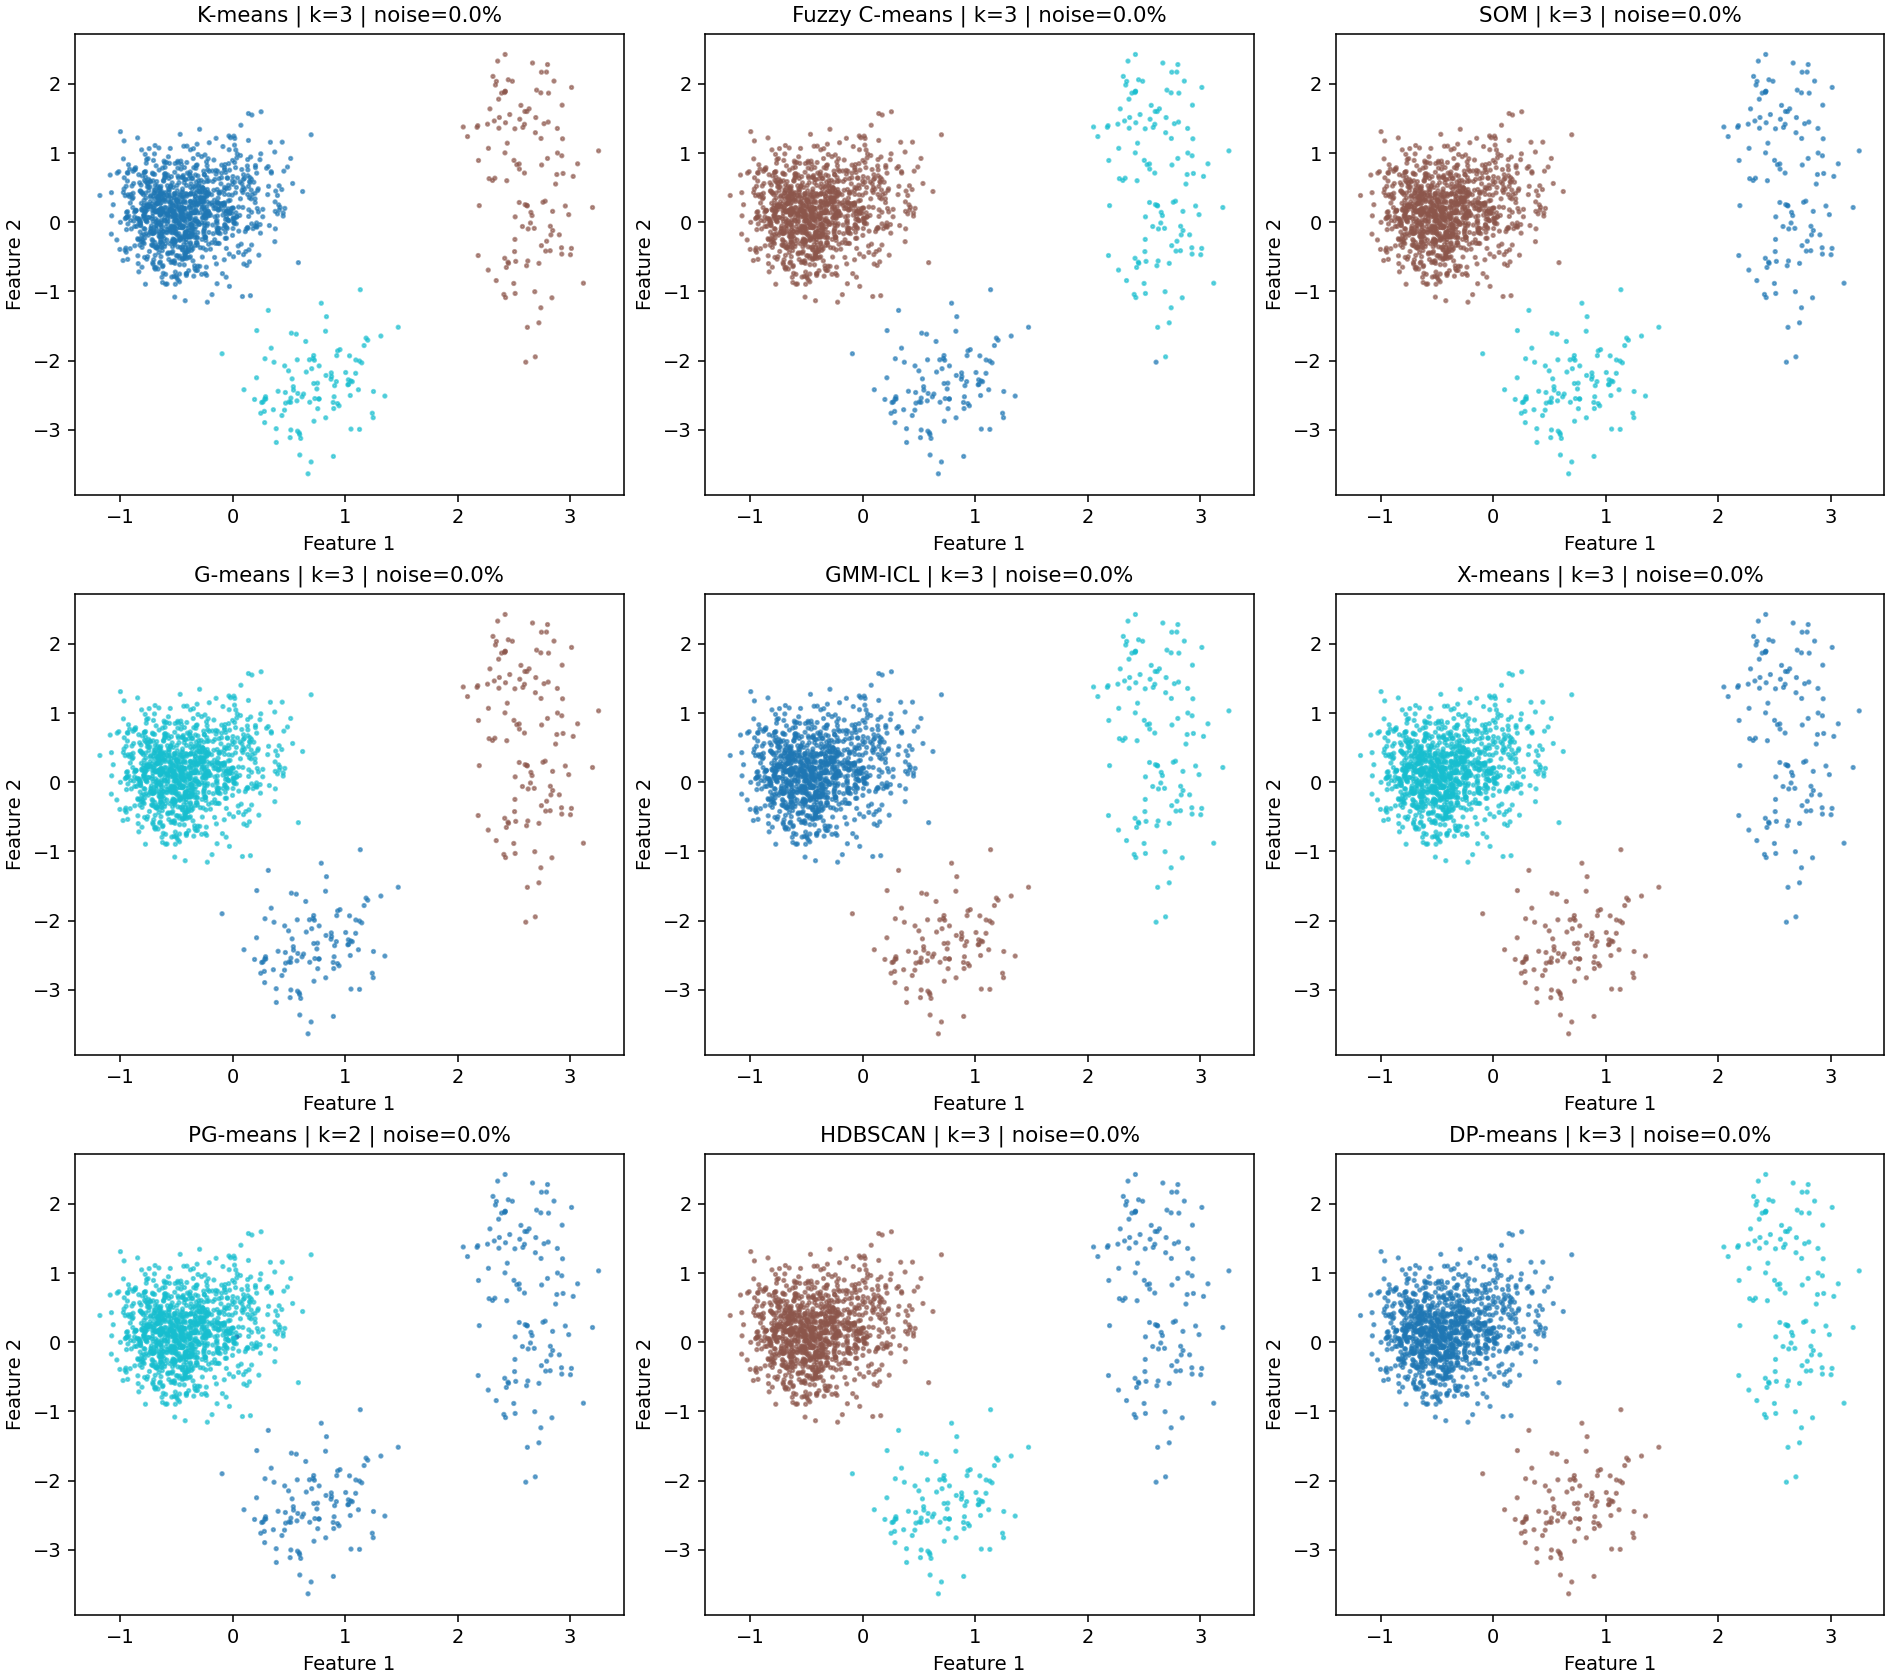

simulation_2_nine_methods.png


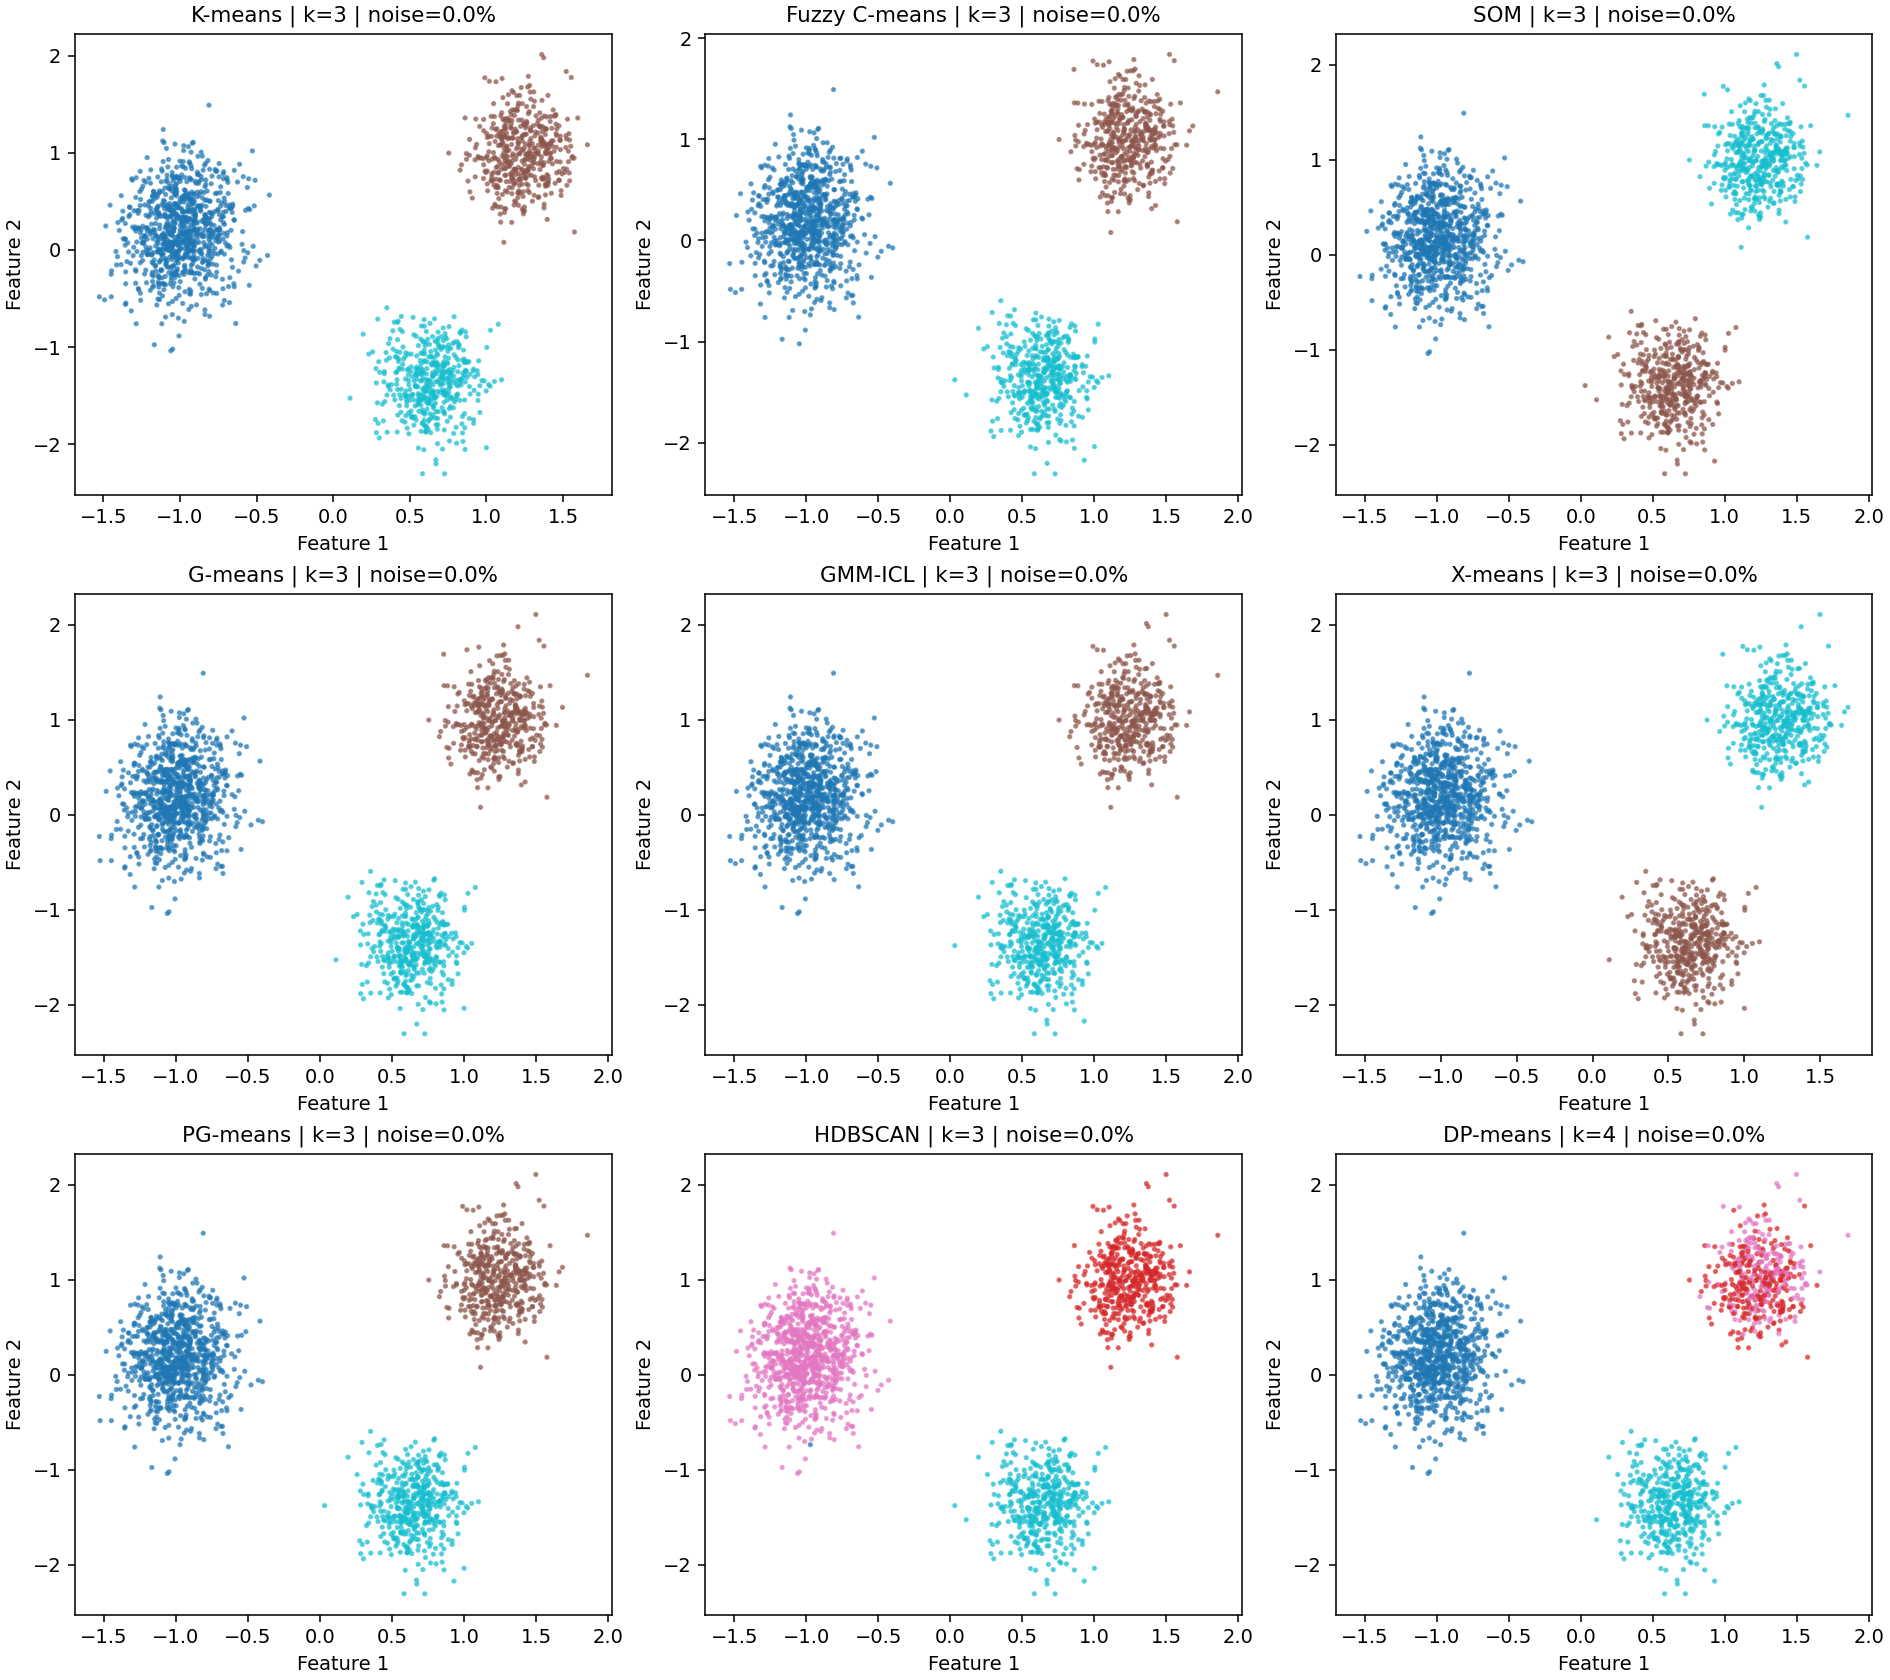

simulation_3_nine_methods.png


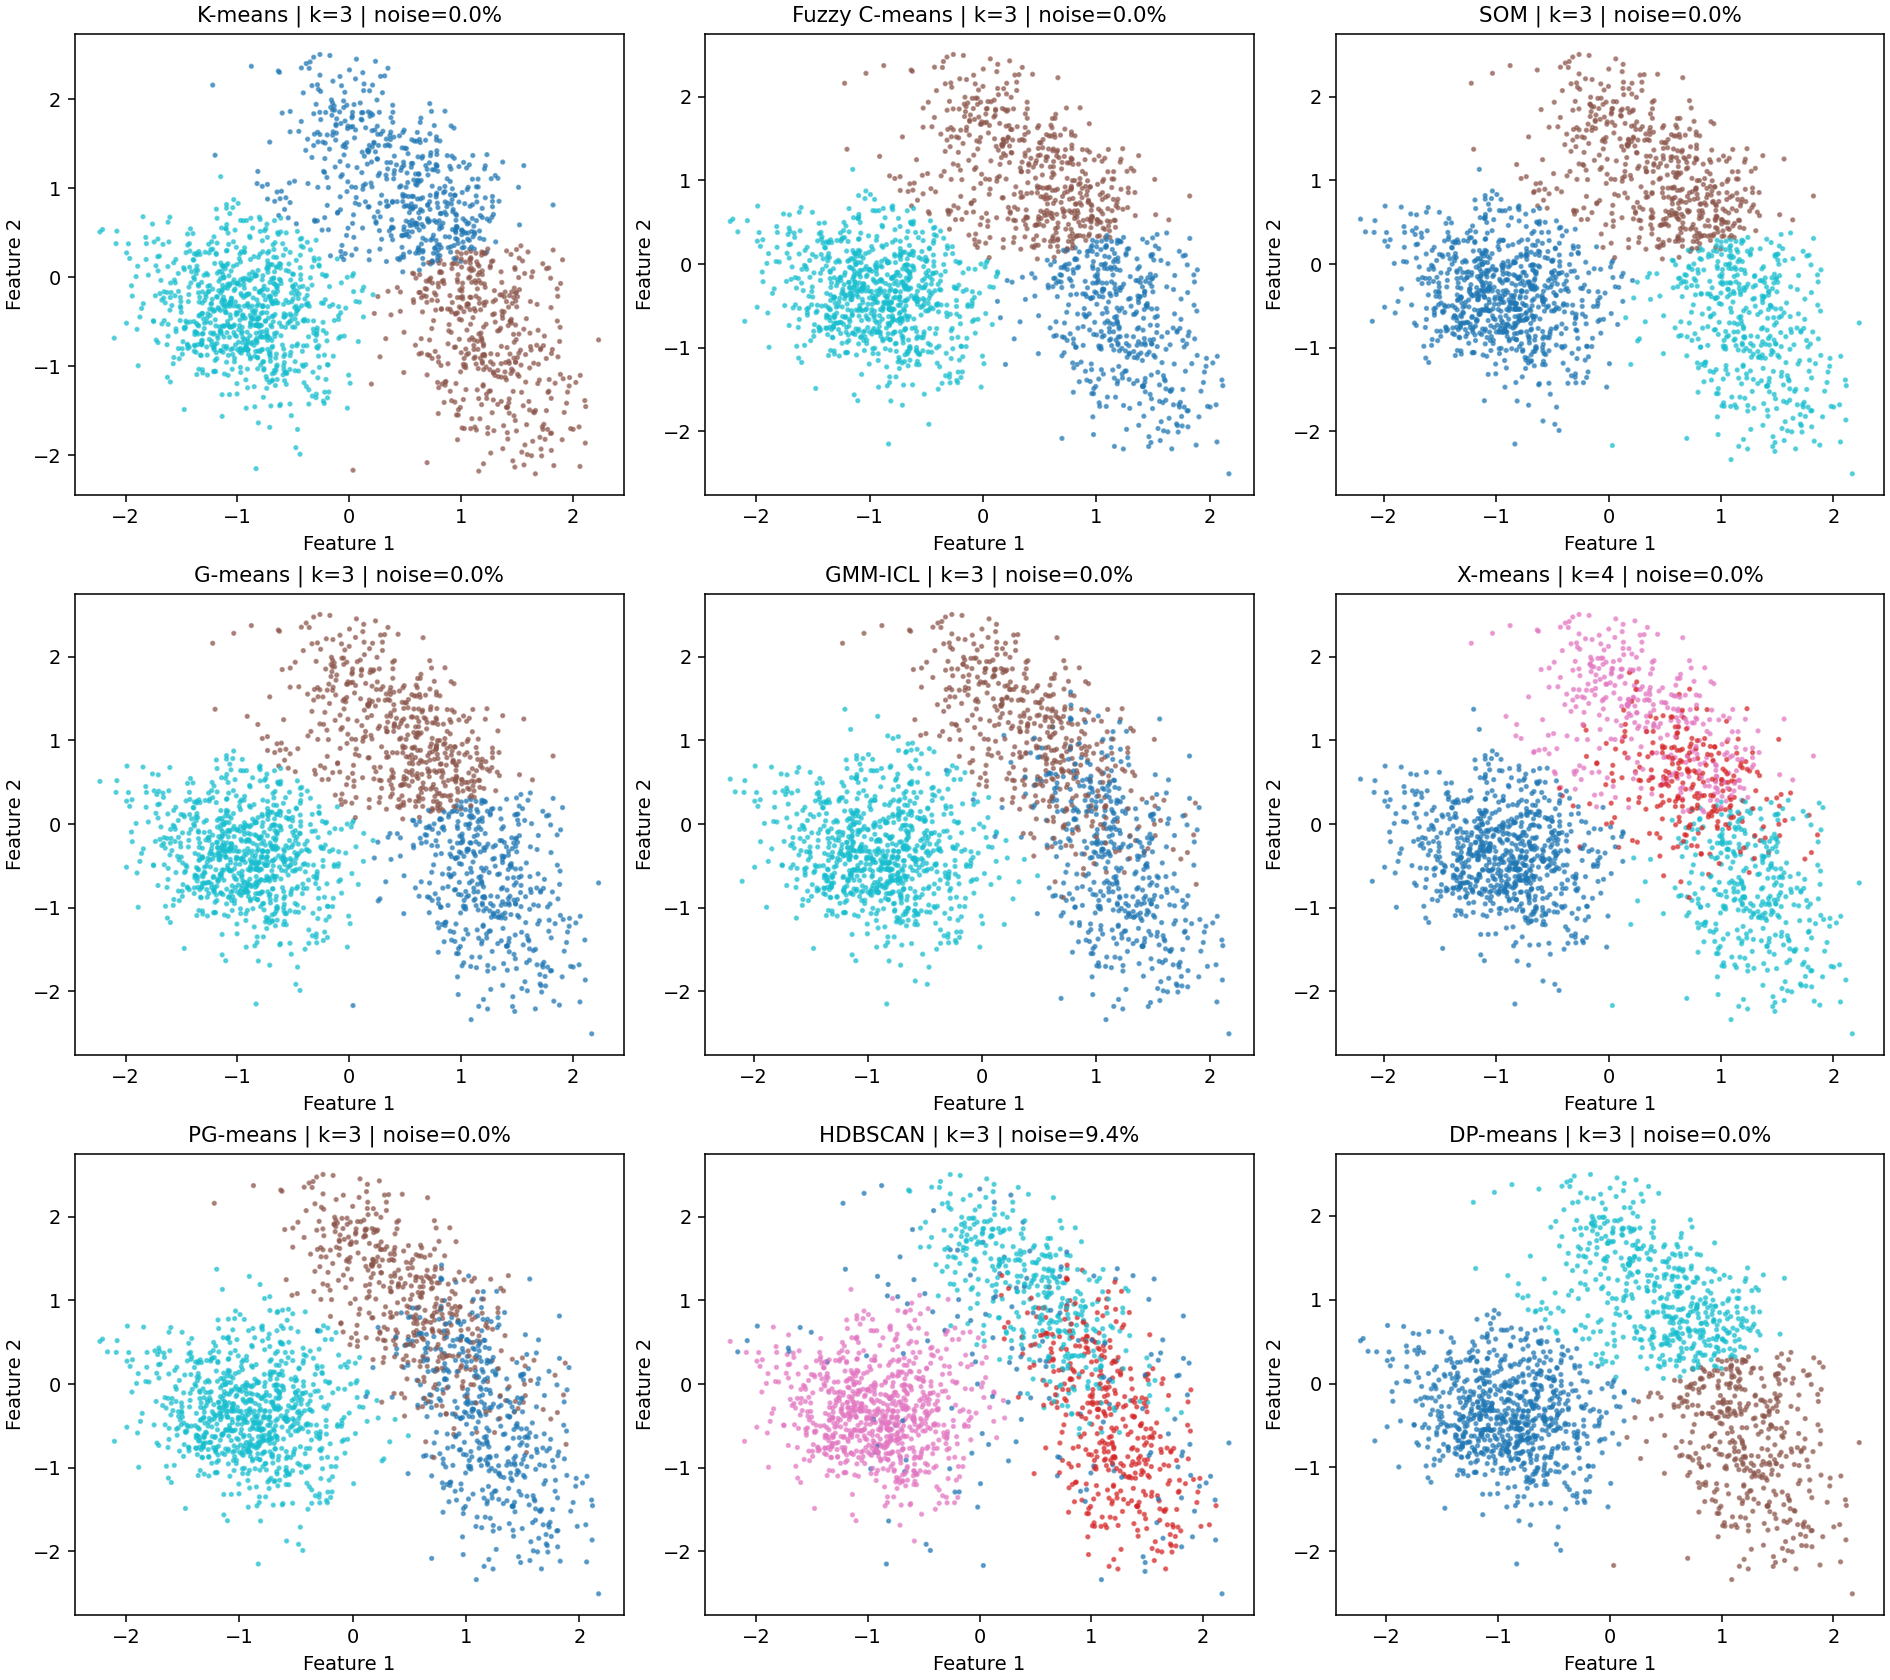

simulation_4_nine_methods.png


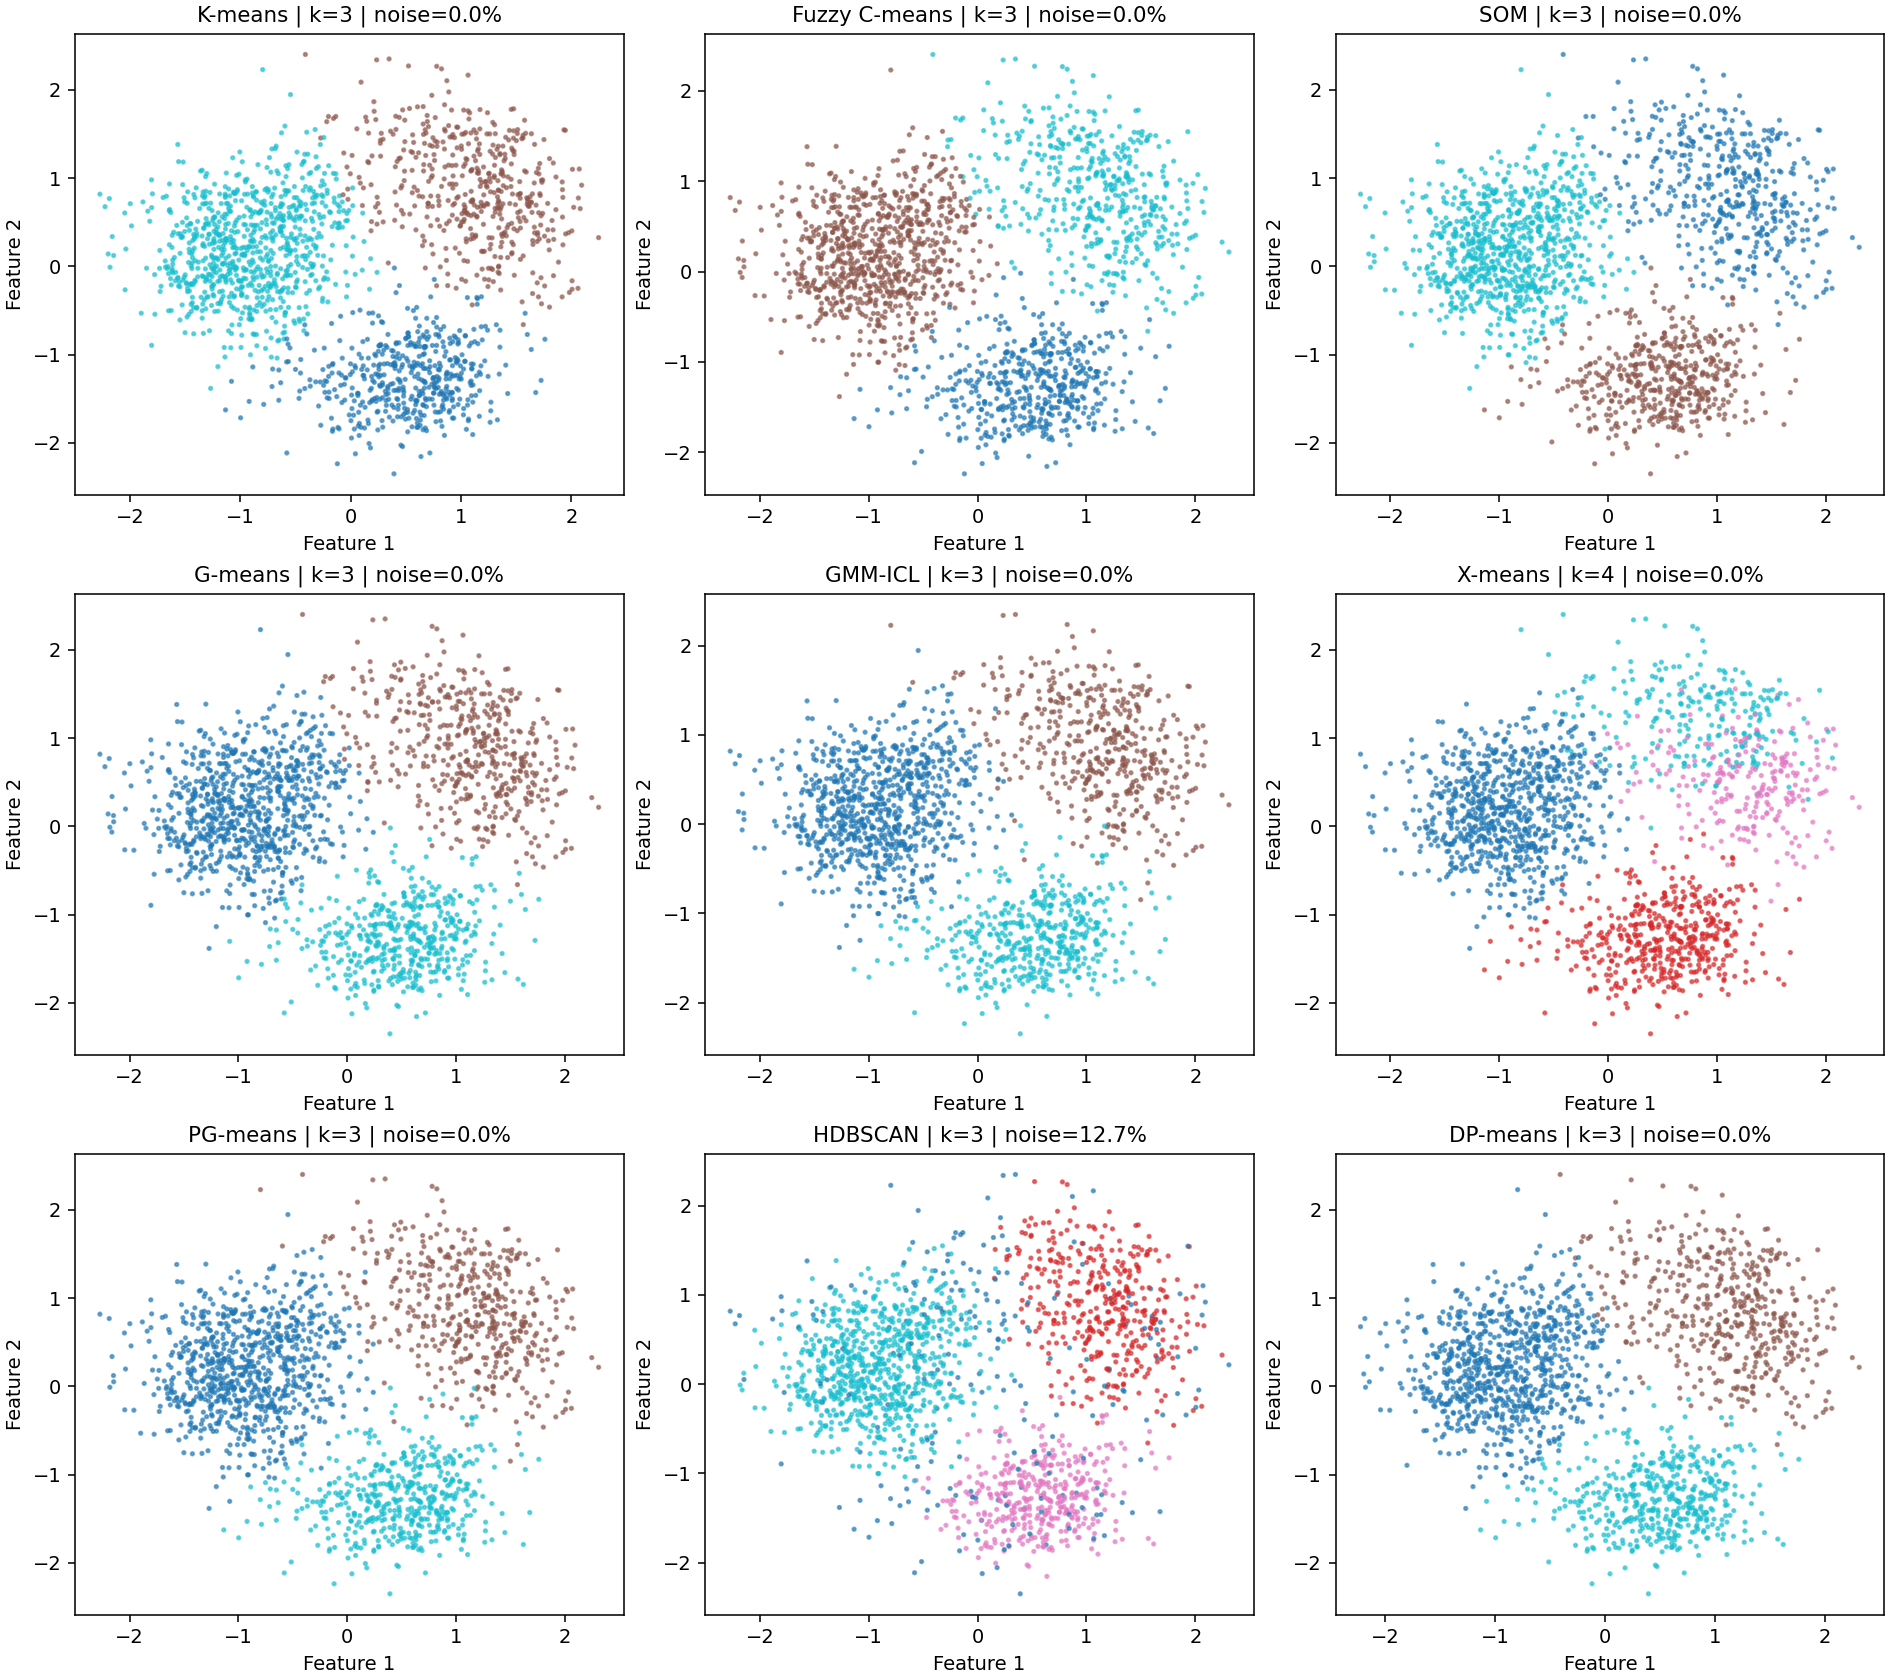

simulation_5_nine_methods.png


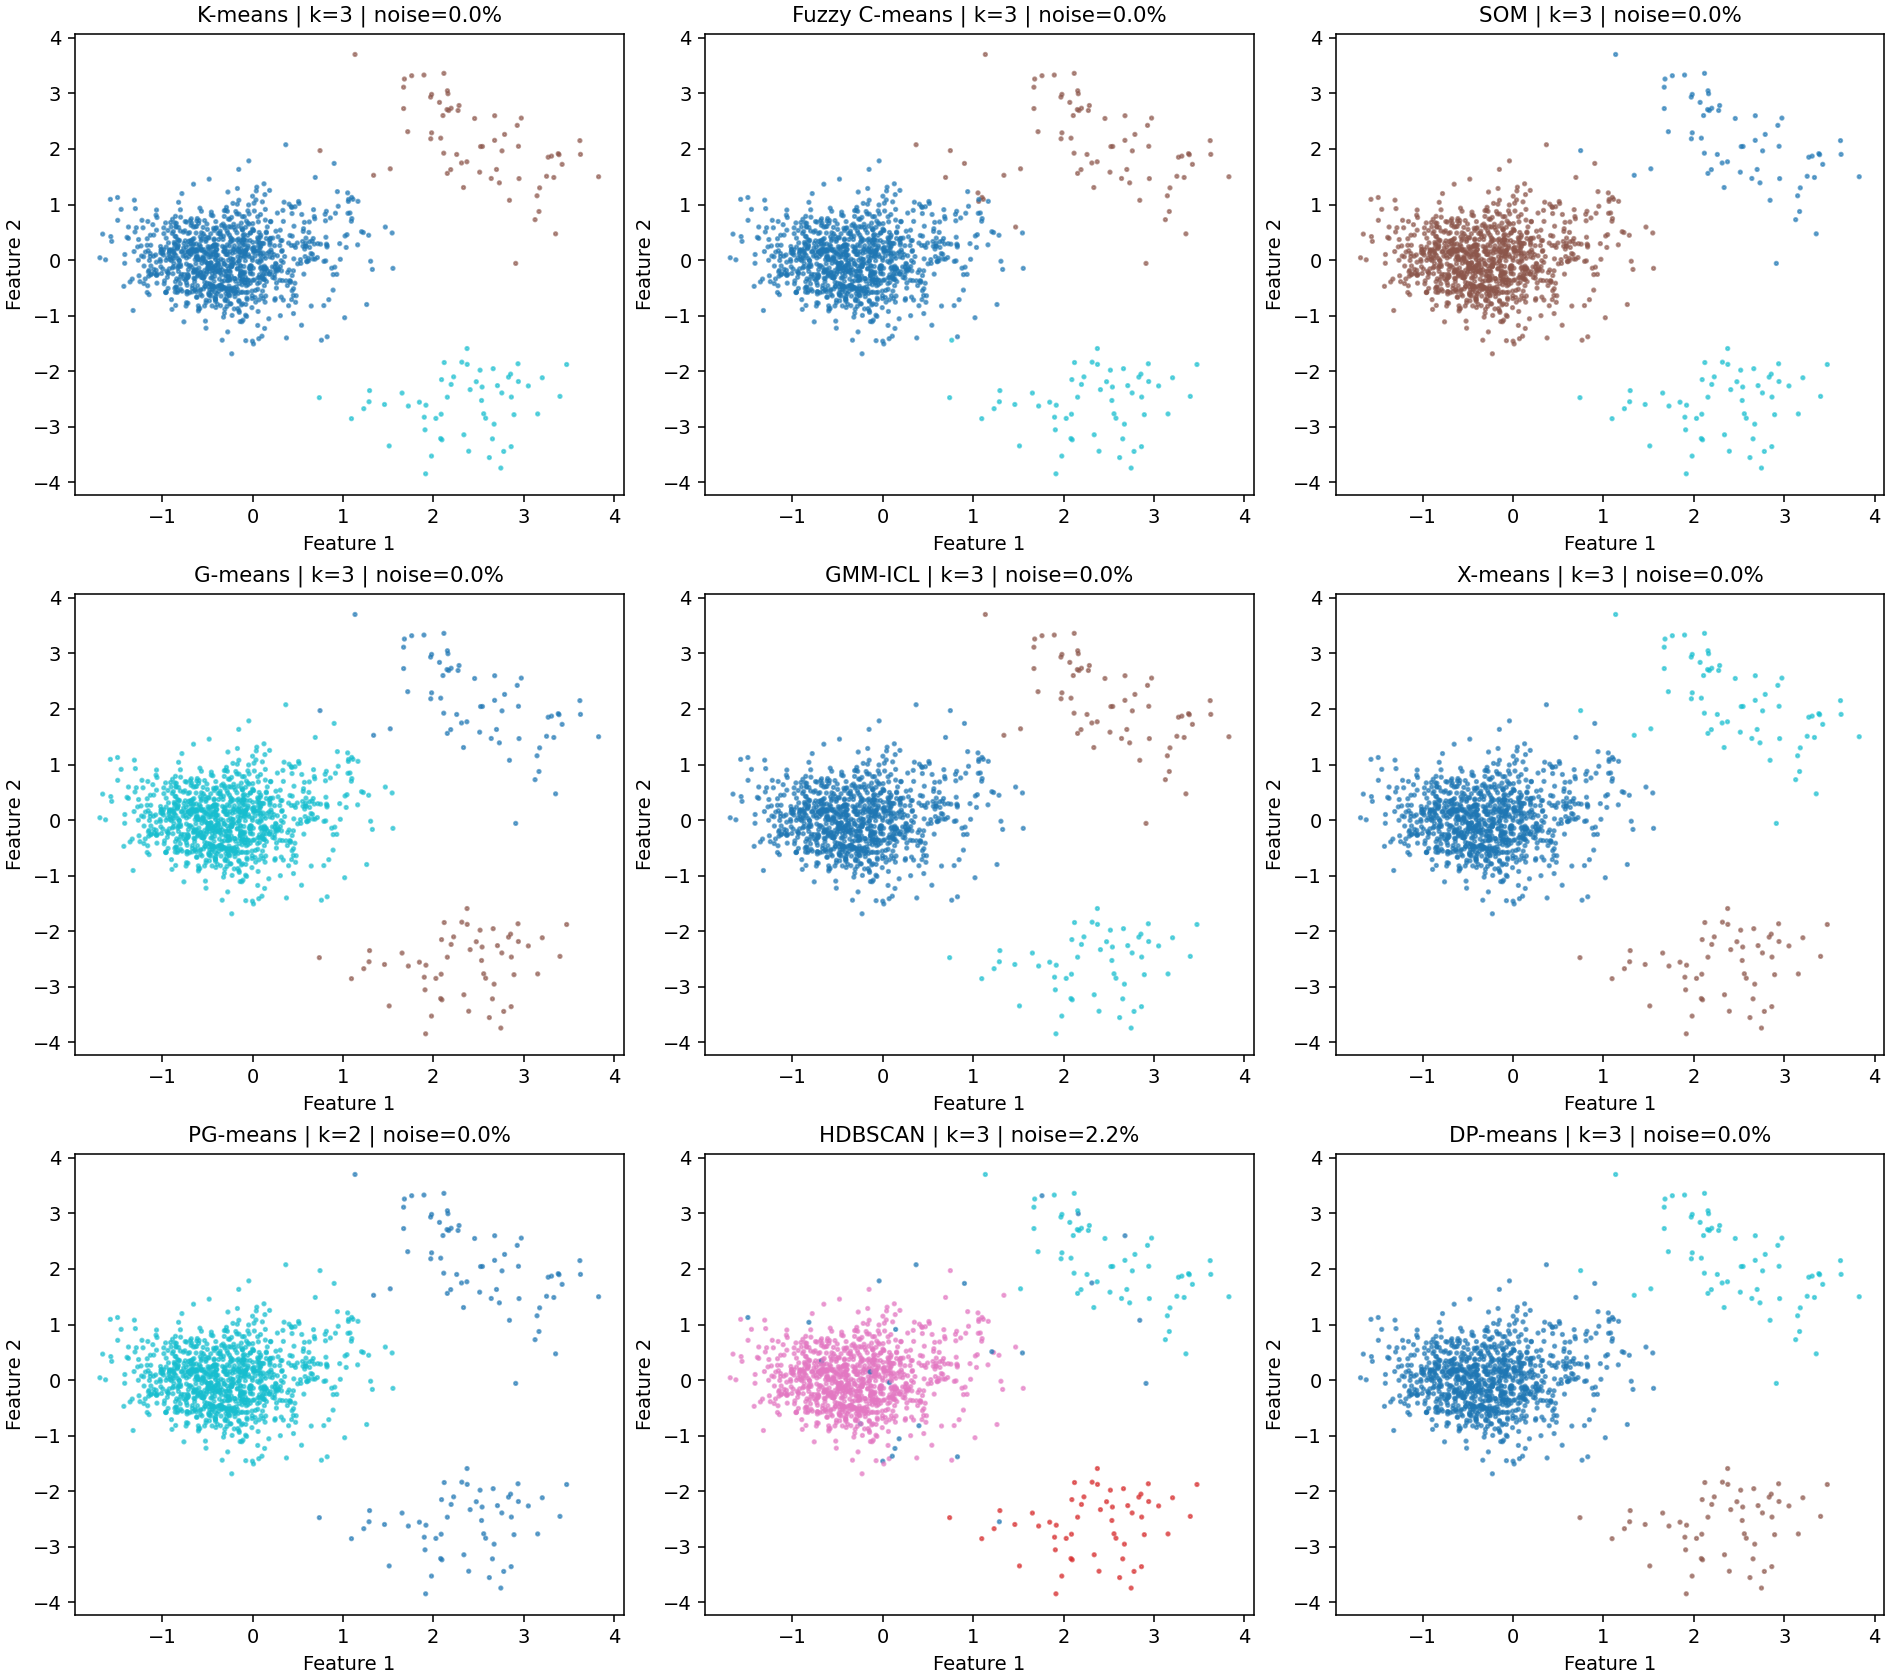

In [10]:
display(flags)
print('Cluster count by method')
display(comparison.pivot(index='dataset',columns='method',values='k'))
display(comparison.pivot(index='dataset',columns='method',values='ari_nonzero_matched').round(3))
from IPython.display import Image
for img in sorted(OUTPUT_DIR.glob('simulation_*_nine_methods.png')):
    print(img.name)
    display(Image(filename=str(img),width=1000))

## 7. Sensitivity analyses and null checks

With `FULL_VALIDATION=True`, stochastic methods are evaluated over ten initializations. I vary detection threshold, PCA dimension, spike polarity, and onset alignment, along with selected method-specific parameters: FCM fuzzification, G-means significance level, PG-means projections, HDBSCAN density settings, and the DP-means penalty. Permuting reference labels provides an ARI null comparison.

The full set of tested settings is exported, including runs with low agreement or unstable solutions.


## 7.0. Full validation and per-recording checkpoints

The full validation includes ten-seed stability estimates, threshold and PCA sweeps, method-specific parameter sweeps, polarity and onset-alignment checks, and permutation controls. Longer stages save per-recording checkpoints, with seed-level results written as individual methods finish.

To resume an interrupted run, set `RESUME_RUN_STAMP` in Section 1 to the run identifier. Its checkpoints are stored in `_full_validation_checkpoints/simulation_i/`. The controller checks the expected summary-table row counts before recording completion in `FULL_VALIDATION_STATUS.json`.


In [11]:
# Full validation controller. Reuses the original mathematical implementations without modification.
from pathlib import Path
from dataclasses import replace
import os, json, time, hashlib
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

CHECKPOINT_ROOT = OUTPUT_DIR/'_full_validation_checkpoints'
CHECKPOINT_ROOT.mkdir(parents=True,exist_ok=True)
VALIDATION_TABLE_SPEC = {
    'seed_stability.csv': len(METHODS),
    'parameter_sensitivity.csv': len(METHODS)*(len(CFG.sensitivity_thresholds)+len(CFG.sensitivity_pcs)),
    'method_parameter_sensitivity.csv': 14,
    'onset_alignment_sensitivity.csv': 3,
    'polarity_sensitivity.csv': 3,
    'reference_label_permutation_control.csv': 2,
}

def _atomic_dataframe_write(df, path):
    path = Path(path)
    temp = path.with_name(path.name+'.tmp')
    pd.DataFrame(df).to_csv(temp,index=False)
    os.replace(temp,path)

def _complete_stage_csv(folder,filename,expected,dataset):
    dest=folder/filename
    if not dest.is_file():return False
    try:
        x=pd.read_csv(dest)
        return len(x)==expected and set(x.dataset)=={dataset} and x.notna().all(axis=1).any()
    except (ValueError,KeyError,FileNotFoundError):
        return False

def _run_full_validation_one(index):
    if index not in DATASETS:
        print(f'Simulation {index}: not requested; skip.',flush=True)
        return
    name=f'simulation_{index}'
    if not FULL_VALIDATION:
        print(f'{name}: validation deliberately SKIPPED (FULL_VALIDATION=False).',flush=True)
        return
    p=DATA_DIR/f'{name}.mat'; folder=CHECKPOINT_ROOT/name;folder.mkdir(exist_ok=True)
    current_sha=_file_sha256(p)
    if current_sha!=EXPECTED_MAT_SHA256[index]:raise ValueError(f'{name}: MAT checksum mismatch')
    stamp=dict(dataset=name,source_sha256=current_sha,sklearn_version=sklearn.__version__,
        config=asdict(CFG),methods=list(METHODS),seeds=list(range(CFG.seed,CFG.seed+CFG.stability_seeds)))
    stamp_hash=hashlib.sha256(json.dumps(stamp,sort_keys=True).encode()).hexdigest()
    fingerprint=folder/'validation_input_fingerprint.json'
    if fingerprint.exists():
        old=json.loads(fingerprint.read_text())
        if old.get('sha256')!=stamp_hash:
            raise RuntimeError(f'{name}: checkpoint provenance mismatch; use a fresh RUN_STAMP, never mix configurations')
    else:
        fingerprint.write_text(json.dumps({'sha256':stamp_hash,'input':stamp},indent=2))
    start=time.monotonic()
    print(f'=== {name}: full validation, original parameters, 10 seeds ===',flush=True)
    # Ten-seed results are saved *per method*: a disconnected cell does not lose completed methods.
    seed_path=folder/'seed_stability.csv'
    prev=pd.read_csv(seed_path).to_dict('records') if seed_path.exists() else []
    if len(prev)!=len({r['method'] for r in prev}):raise RuntimeError('Duplicate method in stability checkpoint')
    completed={r['method'] for r in prev if int(r.get('n_seeds',-1))==CFG.stability_seeds}
    if len(completed)!=len(METHODS):
        rec=read_mat(p,CFG);det=detect(rec,CFG)
        X,_=features(det['waves'],CFG.n_pcs,mode=CFG.feature_method,wavelet_coeffs=CFG.wavelet_coeffs)
        for method in METHODS:
            if method in completed:
                print(f' {method}: using validated 10-seed checkpoint',flush=True)
                continue
            labs=[];counts=[];runtimes=[]
            for si,seed in enumerate(range(CFG.seed,CFG.seed+CFG.stability_seeds),1):
                lab,meta=fit_method(method,X,CFG,seed)
                labs.append(lab);counts.append(len(set(lab)-{-1}));runtimes.append(meta['wall_seconds'])
            agreement=[adjusted_rand_score(labs[0],lab) for lab in labs[1:]]
            row=dict(dataset=name,method=method,n_seeds=len(labs),k_min=min(counts),k_max=max(counts),
                k_values=','.join(map(str,counts)),mean_pairwise_to_first_ARI=float(np.mean(agreement)) if agreement else 1.,
                min_pairwise_to_first_ARI=float(np.min(agreement)) if agreement else 1.,
                mean_fit_s=float(np.mean(runtimes)))
            prev=[r for r in prev if r['method']!=method]+[row]
            _atomic_dataframe_write(pd.DataFrame(prev).set_index('method').reindex(METHODS).dropna(how='all').reset_index(), seed_path)
            print(f' 10-seed stability: {len(prev)}/{len(METHODS)} methods complete — {method}',flush=True)
        del rec,det,X
    # Original routines, identical grids/parameters. Each stage gets its own atomic checkpoint.
    remaining=[
        ('parameter_sensitivity.csv',lambda:sensitivity_session(p,CFG,methods=METHODS)),
        ('method_parameter_sensitivity.csv',lambda:method_specific_sensitivity_session(p,CFG)),
        ('onset_alignment_sensitivity.csv',lambda:alignment_sensitivity_session(p,CFG)),
        ('polarity_sensitivity.csv',lambda:polarity_sensitivity_session(p,CFG)),
        ('reference_label_permutation_control.csv',lambda:null_shuffle_session(p,CFG)),
    ]
    for filename,fn in remaining:
        if _complete_stage_csv(folder,filename,VALIDATION_TABLE_SPEC[filename],name):
            print(f' {filename}: checkpoint verified, skipped recomputation',flush=True)
        else:
            records=fn()
            assert len(records)==VALIDATION_TABLE_SPEC[filename],f'{name}: unexpected {filename} rows {len(records)}'
            _atomic_dataframe_write(records,folder/filename)
            print(f' {filename}: {len(records)} records saved',flush=True)
    assert all(_complete_stage_csv(folder,f,n,name) for f,n in VALIDATION_TABLE_SPEC.items()),f'{name}: incomplete validation'
    # This plot expects aggregated parameter_sensitivity.csv; defer until final aggregation.
    (folder/'COMPLETE.json').write_text(json.dumps({'status':'COMPLETE','dataset':name,
            'fingerprint':stamp_hash,'stages':VALIDATION_TABLE_SPEC,
            'elapsed_s_this_call':round(time.monotonic()-start,2)},indent=2))
    print(f'{name}: 10 seeds × 9 methods + all five sensitivity/null stages VERIFIED '
          f'({time.monotonic()-start:.1f} seconds).',flush=True)

def finalize_full_validation():
    if not FULL_VALIDATION:
        print('FULL VALIDATION SKIPPED: no ten-seed or extended controls are claimed.',flush=True)
        return None
    all_frames={}
    for filename,n_per in VALIDATION_TABLE_SPEC.items():
        parts=[]
        for index in DATASETS:
            name=f'simulation_{index}'; folder=CHECKPOINT_ROOT/name
            if not (folder/'COMPLETE.json').exists() or not _complete_stage_csv(folder,filename,n_per,name):
                raise RuntimeError(f'Missing or incomplete validation: {name}/{filename}')
            parts.append(pd.read_csv(folder/filename))
        combined=pd.concat(parts,ignore_index=True)
        assert len(combined)==n_per*len(DATASETS)
        _atomic_dataframe_write(combined,OUTPUT_DIR/filename)
        all_frames[filename]=combined
        print(f' VERIFIED {filename}: {len(combined)} rows',flush=True)
    for i in DATASETS: plot_sensitivity_summary(OUTPUT_DIR,f'simulation_{i}')
    global flags
    flags=cross_method_audit(comparison,all_frames['seed_stability.csv'])
    _atomic_dataframe_write(flags,OUTPUT_DIR/'failure_flags.csv')
    status=dict(status='COMPLETE',number_recordings=len(DATASETS),recordings=list(DATASETS),
                seeds_per_method=CFG.stability_seeds,methods=len(METHODS),
                tables={k:len(v) for k,v in all_frames.items()},
                python=sys.version.split()[0],sklearn=sklearn.__version__,
                original_zip_preserved=True)
    (OUTPUT_DIR/'FULL_VALIDATION_STATUS.json').write_text(json.dumps(status,indent=2))
    print('Full validation finished for every selected recording; results aggregated and failure flags recomputed.',flush=True)
    return status


In [12]:
# Complete validation for simulation 1; checkpoints survive re-execution of this cell.
_run_full_validation_one(1)


=== simulation_1: full validation, original parameters, 10 seeds ===
 10-seed stability: 1/9 methods complete — K-means
 10-seed stability: 2/9 methods complete — Fuzzy C-means
 10-seed stability: 3/9 methods complete — SOM
 10-seed stability: 4/9 methods complete — G-means
 10-seed stability: 5/9 methods complete — GMM-ICL
 10-seed stability: 6/9 methods complete — X-means
 10-seed stability: 7/9 methods complete — PG-means
 10-seed stability: 8/9 methods complete — HDBSCAN
 10-seed stability: 9/9 methods complete — DP-means
 parameter_sensitivity.csv: 54 records saved
 method_parameter_sensitivity.csv: 14 records saved
 onset_alignment_sensitivity.csv: 3 records saved
 polarity_sensitivity.csv: 3 records saved
 reference_label_permutation_control.csv: 2 records saved
simulation_1: 10 seeds × 9 methods + all five sensitivity/null stages VERIFIED (140.7 seconds).


In [13]:
# Complete validation for simulation 2; checkpoints survive re-execution of this cell.
_run_full_validation_one(2)


=== simulation_2: full validation, original parameters, 10 seeds ===
 10-seed stability: 1/9 methods complete — K-means
 10-seed stability: 2/9 methods complete — Fuzzy C-means
 10-seed stability: 3/9 methods complete — SOM
 10-seed stability: 4/9 methods complete — G-means
 10-seed stability: 5/9 methods complete — GMM-ICL
 10-seed stability: 6/9 methods complete — X-means
 10-seed stability: 7/9 methods complete — PG-means
 10-seed stability: 8/9 methods complete — HDBSCAN
 10-seed stability: 9/9 methods complete — DP-means
 parameter_sensitivity.csv: 54 records saved
 method_parameter_sensitivity.csv: 14 records saved
 onset_alignment_sensitivity.csv: 3 records saved
 polarity_sensitivity.csv: 3 records saved
 reference_label_permutation_control.csv: 2 records saved
simulation_2: 10 seeds × 9 methods + all five sensitivity/null stages VERIFIED (169.1 seconds).


In [ ]:
# Complete validation for simulation 3; checkpoints survive re-execution of this cell.
_run_full_validation_one(3)


=== simulation_3: full validation, original parameters, 10 seeds ===
 10-seed stability: 1/9 methods complete — K-means
 10-seed stability: 2/9 methods complete — Fuzzy C-means
 10-seed stability: 3/9 methods complete — SOM
 10-seed stability: 4/9 methods complete — G-means
 10-seed stability: 5/9 methods complete — GMM-ICL
 10-seed stability: 6/9 methods complete — X-means
 10-seed stability: 7/9 methods complete — PG-means
 10-seed stability: 8/9 methods complete — HDBSCAN


In [ ]:
# Complete validation for simulation 4; checkpoints survive re-execution of this cell.
_run_full_validation_one(4)


=== simulation_4: full validation, original parameters, 10 seeds ===
 10-seed stability: 1/9 methods complete — K-means
 10-seed stability: 2/9 methods complete — Fuzzy C-means
 10-seed stability: 3/9 methods complete — SOM
 10-seed stability: 4/9 methods complete — G-means
 10-seed stability: 5/9 methods complete — GMM-ICL
 10-seed stability: 6/9 methods complete — X-means
 10-seed stability: 7/9 methods complete — PG-means
 10-seed stability: 8/9 methods complete — HDBSCAN
 10-seed stability: 9/9 methods complete — DP-means
 parameter_sensitivity.csv: 54 records saved
 method_parameter_sensitivity.csv: 14 records saved
 onset_alignment_sensitivity.csv: 3 records saved
 polarity_sensitivity.csv: 3 records saved
 reference_label_permutation_control.csv: 2 records saved
simulation_4: 10 seeds × 9 methods + all five sensitivity/null stages VERIFIED (201.2 seconds).


In [ ]:
# Complete validation for simulation 5; checkpoints survive re-execution of this cell.
_run_full_validation_one(5)


In [ ]:
FULL_VALIDATION_SUMMARY = finalize_full_validation()
if FULL_VALIDATION:
    from IPython.display import display
    display(pd.DataFrame([{'table':k,'verified_rows':v,'expected_rows':len(DATASETS)*VALIDATION_TABLE_SPEC[k]}
                          for k,v in FULL_VALIDATION_SUMMARY['tables'].items()]))
    assert FULL_VALIDATION_SUMMARY['seeds_per_method']==10
    assert FULL_VALIDATION_SUMMARY['tables']['seed_stability.csv']==len(DATASETS)*len(METHODS)


In [ ]:
if FULL_VALIDATION:
    assert (OUTPUT_DIR/'FULL_VALIDATION_STATUS.json').exists(), 'Full-validation status not produced.'
    status=json.loads((OUTPUT_DIR/'FULL_VALIDATION_STATUS.json').read_text())
    assert status['status']=='COMPLETE'
    print('Full validation:',status['recordings'],' | seeds/method:',status['seeds_per_method'])
    for fname in ('seed_stability.csv','parameter_sensitivity.csv','method_parameter_sensitivity.csv',
                  'onset_alignment_sensitivity.csv','polarity_sensitivity.csv','reference_label_permutation_control.csv'):
        frame=pd.read_csv(OUTPUT_DIR/fname)
        assert len(frame)==len(DATASETS)*VALIDATION_TABLE_SPEC[fname],fname
        print(f'{fname}: {len(frame)} validated rows')
        display(frame.head(5).round(4))
else:
    print('Quick mode: FULL_VALIDATION=False; supplementary 10-seed stability and extended controls were intentionally skipped.')


## 7.1. Figure previews

These previews show selected results from the completed benchmark. The results archive contains the waveform, clustering, and model-fit figures for all five recordings.


In [ ]:
from IPython.display import display, Image
for index in DATASETS:
    base=OUTPUT_DIR/f'simulation_{index}'
    print(f'\n===== Simulation {index}: preprocessing + 9-method feature overview =====')
    for image_path in [base/'01_preprocessing_detection.png',base/'03_nine_method_comparison.png']:
        if image_path.exists(): display(Image(filename=str(image_path),width=1050))
print('Preview one MATLAB-style waveform sheet (K-means; all nine sheets available per recording):')
for index in DATASETS:
    p=OUTPUT_DIR/f'simulation_{index}'/'per_method'/'k_means_waveforms.png'
    if p.exists():
        print(p.parent.parent.name)
        display(Image(filename=str(p),width=1000))

## 7.2. PCA and wavelet-feature ablation

I compare three-component waveform PCA with ten Haar-wavelet coefficients selected by KS-\(D\) ranking. Detection and the chronological 70/30 split remain fixed. K-means is fitted at `K ∈ {2, 3, 4}`, and held-out agreement is calculated for all reference codes and for codes `1` and `2` separately.

The wavelet selection follows the non-Gaussianity-based approach of Quian Quiroga et al. (2004). I also test eight and sixteen selected coefficients to examine sensitivity to feature count.


In [ ]:
# Compare PCA and Haar features with a chronological holdout.
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.signal import resample_poly
from scipy.stats import kstest
from sklearn.metrics import adjusted_rand_score
from pathlib import Path
import matplotlib.pyplot as plt

def _fit_transform_early_late(waves, cutoff, feature_name, n_wavelets=10):
    early,late=np.asarray(waves[:cutoff],float),np.asarray(waves[cutoff:],float)
    if feature_name=='PCA-3':
        basis=PCA(n_components=3,svd_solver='full').fit(early)
        scaler=StandardScaler().fit(basis.transform(early))
        return scaler.transform(basis.transform(early)),scaler.transform(basis.transform(late)),{'mode':'PCA','n_features':3}
    if feature_name=='Haar-KS-10':
        z1=_haar_coefficients(early); z2=_haar_coefficients(late)
        mu=z1.mean(0); sd=z1.std(0)
        z=(z1-mu)/np.maximum(sd,1e-10)
        ks=np.array([kstest(z[:,j],'norm').statistic for j in range(z.shape[1])])
        ks[sd<max(1e-12,1e-5*np.median(sd))]=-np.inf;ks[-1]=-np.inf
        idx=np.argsort(-ks,kind='stable')[:n_wavelets]
        scaling=StandardScaler().fit(z1[:,idx])
        return scaling.transform(z1[:,idx]),scaling.transform(z2[:,idx]),{'mode':'Wavelet-KS','n_features':n_wavelets,'selected_coefficients':idx.tolist()}
    raise ValueError(feature_name)

def run_feature_heldout(data_dir,output_dir,cfg=CFG,ks=(2,3,4)):
    rows=[];root=Path(output_dir)
    for i in DATASETS:
        rec=read_mat(Path(data_dir)/f'simulation_{i}.mat',cfg)
        det=detect(rec,cfg)
        matched_ix, ref_ix=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
        split=int(.70*len(det['peaks']))
        later=matched_ix>=split
        test_idx=matched_ix[later]-split
        labels=rec['cls'][ref_ix[later]]
        for extractor in ('PCA-3','Haar-KS-10'):
            xx_train,xx_test,details=_fit_transform_early_late(det['waves'],split,extractor)
            for k in ks:
                model=KMeans(n_clusters=k,random_state=cfg.seed,n_init=20)
                model.fit(xx_train)
                predictions=model.predict(xx_test)
                pred=predictions[test_idx]
                nonzero=labels>0
                ari_all=float(adjusted_rand_score(labels,pred)) if len(np.unique(labels))>1 else np.nan
                ari_pos=float(adjusted_rand_score(labels[nonzero],pred[nonzero])) if nonzero.sum()>=20 and len(np.unique(labels[nonzero]))>1 else np.nan
                rows.append(dict(dataset=rec['name'],feature_extractor=extractor,K=int(k),
                     n_train=int(split),n_test=int(len(det['peaks'])-split),
                     n_test_annotated=int(len(labels)),n_test_nonzero=int(nonzero.sum()),
                     ari_nonzero_heldout=ari_pos,ari_all_codes_heldout=ari_all,
                     selection='strict chronological, wavelet coefficients and scaler trained only on early events',
                     reference_use='posthoc scoring only'))
    frame=pd.DataFrame(rows)
    frame.to_csv(root/'feature_extraction_heldout_ablation.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(13,5),layout='constrained')
    for col,ax in zip(['ari_nonzero_heldout','ari_all_codes_heldout'],axs):
        for extractor,sub in frame[frame.K==3].groupby('feature_extractor'):
            ax.plot(sub.dataset,sub[col],marker='o',label=extractor)
        ax.set_title(col.replace('_',' '));ax.set_ylabel('Matched-event ARI');ax.tick_params(axis='x',rotation=25);ax.grid(alpha=.2)
    axs[0].legend()
    fig.suptitle('PCA and wavelet features — chronological holdout',weight='bold')
    fig.savefig(root/'feature_extraction_heldout_ablation.png',dpi=160);plt.close(fig)
    return frame

feature_ablation_v33=run_feature_heldout(DATA_DIR,OUTPUT_DIR,CFG)
assert len(feature_ablation_v33)==len(DATASETS)*2*3
print('Feature comparison at K=3:')
display(feature_ablation_v33[feature_ablation_v33.K==3][['dataset','feature_extractor','n_test_nonzero','ari_nonzero_heldout','ari_all_codes_heldout']].round(3))


Feature comparison at K=3:


,dataset,feature_extractor,n_test_nonzero,ari_nonzero_heldout,ari_all_codes_heldout
1,simulation_1,PCA-3,68,1.000,1.000
4,simulation_1,Haar-KS-10,68,1.000,1.000
7,simulation_2,PCA-3,311,1.000,1.000
10,simulation_2,Haar-KS-10,311,0.987,0.996
13,simulation_3,PCA-3,312,0.360,0.365
16,simulation_3,Haar-KS-10,312,0.582,0.700
19,simulation_4,PCA-3,317,0.981,0.697
22,simulation_4,Haar-KS-10,317,0.956,0.816
25,simulation_5,PCA-3,38,0.000,0.292
28,simulation_5,Haar-KS-10,38,1.000,0.983


## 7.3. Detection-threshold sensitivity

Detection is repeated at `4σ`, `5σ`, `5.5σ`, `6σ`, and `6.5σ`. K-means and GMM are compared at fixed `K = 2, 3, 4` across the threshold grid; the `5.5σ` condition also includes all nine clustering methods. I report both matched-event ARI and the fraction of reference events recovered, so changes in clustering agreement can be read alongside changes in detection yield.

The primary analysis uses `4σ`; `5.5σ` is an additional sensitivity condition. The relevant exports are `threshold_tradeoff_fixed_K.csv`, `secondary_5p5_sigma_nine_methods.csv`, `reference_amplitude_posthoc_audit.csv`, `reference_class_amplitude_audit.png`, and `16_threshold_tradeoff.png` in each recording's output directory.


In [ ]:
# Detection-threshold sensitivity across five recordings.
# Load reference events after clustering for the agreement tables.
from pathlib import Path
from dataclasses import replace
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

GATE_GRID = (4.0, 5.0, 5.5, 6.0, 6.5)
SECONDARY_GATE = 5.5  # Supplementary threshold chosen after inspection of the recordings.
FIXED_K_GRID = (2, 3, 4)

def _reference_posthoc_metrics(rec, det, cfg, labels):
    pi, ti = match_onsets_to_peaks(det['peaks'], rec['ref'], cfg)
    classes = rec['cls'][ti] if len(ti) else np.array([], dtype=np.int32)
    valid = classes > 0
    ari = (float(adjusted_rand_score(classes[valid], labels[pi][valid]))
           if valid.sum() >= 15 and len(np.unique(classes[valid])) >= 2 else np.nan)
    matched_by_class = {int(c):int(np.sum(classes==c)) for c in np.unique(rec['cls'])}
    total_by_class = {int(c):int(np.sum(rec['cls']==c)) for c in np.unique(rec['cls'])}
    positive_recall = sum(n for c,n in matched_by_class.items() if c>0)/max(1, sum(n for c,n in total_by_class.items() if c>0))
    return dict(ari_nonzero_matched=ari, annotated_nonzero_recovery=positive_recall,
                matched_annotation_class0=matched_by_class.get(0,0),
                matched_annotation_nonzero=sum(n for c,n in matched_by_class.items() if c>0),
                n_annotated_matched=len(pi), class0_semantics='UNVERIFIED')

def run_detection_gate_audit(data_dir, output_dir, cfg, recordings=(1,2,3,4,5),
                             gate_grid=GATE_GRID, secondary_gate=SECONDARY_GATE,
                             k_grid=FIXED_K_GRID, run_secondary_all_nine=True):
    """Measure cluster agreement and reference recovery across detection thresholds.

    The 5.5-sigma setting is a supplementary sensitivity comparison."""
    out=Path(output_dir);out.mkdir(exist_ok=True,parents=True)
    rows=[];amplitudes=[];secondary_rows=[]
    for sid in recordings:
        rec=read_mat(Path(data_dir)/f'simulation_{sid}.mat',cfg)
        orig=detect(rec,replace(cfg,threshold_sigma=4.0))
        op,ot=match_onsets_to_peaks(orig['peaks'],rec['ref'],cfg)
        if len(op):
            h=orig['waves'].max(axis=1)/max(orig['sigma'],1e-12)
            for c in np.unique(rec['cls']):
                hh=h[op[rec['cls'][ot]==c]]
                if len(hh):
                    amplitudes.append(dict(dataset=rec['name'],reference_code=int(c),n=int(len(hh)),
                                           median_peak_z=float(np.median(hh)),
                                           p10_peak_z=float(np.percentile(hh,10)),
                                           p90_peak_z=float(np.percentile(hh,90))))
        for sigma in gate_grid:
            local_cfg=replace(cfg,threshold_sigma=float(sigma))
            det=orig if sigma==4.0 else detect(rec,local_cfg)
            X,_=features(det['waves'],local_cfg.n_pcs,mode=local_cfg.feature_method,wavelet_coeffs=local_cfg.wavelet_coeffs)
            pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],local_cfg)
            rr=rec['cls'][ti]
            pos=rr>0
            recovered=float(np.sum(pos)/max(1,np.sum(rec['cls']>0)))
            class0_matches=int(np.sum(rr==0))
            matched_n=len(rr)
            for k in k_grid:
                # Fit the detector and clustering model without annotation labels.
                km=KMeans(n_clusters=k,n_init=15,max_iter=300,random_state=cfg.seed).fit(X)
                gmm=GaussianMixture(n_components=k,covariance_type='full',reg_covar=1e-3,
                                    n_init=3,max_iter=200,random_state=cfg.seed).fit(X)
                for method,labels in [('K-means fixed K',km.labels_),('GMM fixed K',gmm.predict(X))]:
                    ari=(float(adjusted_rand_score(rr[pos],labels[pi][pos]))
                         if pos.sum()>=15 and len(np.unique(rr[pos]))>=2 else np.nan)
                    rows.append(dict(dataset=rec['name'],threshold_sigma=float(sigma),
                                     method=method,k=int(k),n_detected=len(det['peaks']),
                                     annotated_nonzero_recall=recovered,
                                     class0_reference_matched=class0_matches,
                                     matched_annotated_total=matched_n,
                                     ari_nonzero_matched=ari,
                                     epistemic_note='Exploratory post hoc sweep; not prospective validation'))
            if run_secondary_all_nine and np.isclose(sigma, secondary_gate):
                for method in METHODS:
                    labs, meta=fit_method(method,X,local_cfg,cfg.seed)
                    scored=_reference_posthoc_metrics(rec,det,local_cfg,labs)
                    secondary_rows.append(dict(dataset=rec['name'],threshold_sigma=float(sigma),
                        method=method,n_detected=len(det['peaks']),
                        selected_clusters=len(set(labs)-{-1}),noise_fraction=float(np.mean(labs==-1)),
                        k_cap_hit=bool(meta.get('k_cap_hit',False)),**scored))
        print(f'{rec["name"]}: amplitude gate audit finished',flush=True)

    df=pd.DataFrame(rows);amp=pd.DataFrame(amplitudes)
    df.to_csv(out/'threshold_tradeoff_fixed_K.csv',index=False)
    amp.to_csv(out/'reference_amplitude_posthoc_audit.csv',index=False)
    if secondary_rows:
        pd.DataFrame(secondary_rows).to_csv(out/'secondary_5p5_sigma_nine_methods.csv',index=False)
    import matplotlib.pyplot as plt
    for sid in recordings:
        name=f'simulation_{sid}';q=df[(df.dataset==name)&(df.k==3)]
        fig, axes=plt.subplots(1,2,figsize=(12,4.3),layout='constrained')
        for method in ['K-means fixed K','GMM fixed K']:
            z=q[q.method==method].sort_values('threshold_sigma')
            axes[0].plot(z.threshold_sigma,z.ari_nonzero_matched,'o-',label=method)
        z=q[q.method=='K-means fixed K'].sort_values('threshold_sigma')
        axes[1].plot(z.threshold_sigma,z.annotated_nonzero_recall,'o-',label='Nonzero annotation recovery')
        ax2=axes[1].twinx();ax2.plot(z.threshold_sigma,z.n_detected,'s--',color='0.45',label='Detected events')
        axes[0].set_ylabel('Matched-event ARI, codes 1 and 2')
        axes[1].set_ylabel('Event recovery, codes 1 and 2')
        ax2.set_ylabel('Total detected peaks')
        for a in axes:a.set_xlabel('Detection threshold (robust σ)');a.grid(alpha=.2);a.axvline(4.0,color='0.6',ls=':');a.axvline(5.5,color='0.6',ls='--')
        axes[0].set_title('Clustering agreement by threshold');axes[1].set_title('Detection trade-off')
        axes[0].legend(fontsize=8,loc='best')
        fig.suptitle(name+' | detection-threshold sensitivity',fontsize=11)
        dest=out/name;dest.mkdir(parents=True,exist_ok=True)
        fig.savefig(dest/'16_threshold_tradeoff.png',dpi=160);plt.close(fig)
    fig, ax=plt.subplots(figsize=(11,5),layout='constrained')
    colors=['#657d95','#d17b44','#467b69'];x=np.arange(len(recordings))
    for j,c in enumerate([0,1,2]):
        z=amp[amp.reference_code==c].set_index('dataset')
        y=[z.loc[f'simulation_{i}','median_peak_z'] if f'simulation_{i}' in z.index else np.nan for i in recordings]
        ax.plot(x,y,marker='o',label=f'Code {c}',color=colors[j])
    ax.set_xticks(x,[f'Sim {i}' for i in recordings]);ax.set_ylabel('Median matched peak / noise MAD σ')
    ax.set_title('Matched-event amplitude by reference code')
    ax.legend();ax.grid(alpha=.2)
    fig.savefig(out/'reference_class_amplitude_audit.png',dpi=160);plt.close(fig)
    (out/'ROBUSTNESS_INTERPRETATION.md').write_text(
        '# Detection threshold and event recovery\n\n'
        '- Main detector threshold: 4.0 sigma.\n'
        '- The 5.5-sigma threshold is a supplementary, exploratory comparison.\n'
        '- Reference codes are used after fitting to calculate agreement and recovery.\n'
        '- Code 0 is retained as a separate annotation category.\n'
        '- The threshold sweep is reported in full rather than selecting the maximum-ARI setting.\n'
        '- The tables show the trade-off between matched-event ARI and event recovery.\n'
        '- Single-cluster solutions and cluster-count limits are retained for inspection.\n',encoding='utf-8')
    return df,amp,pd.DataFrame(secondary_rows)


In [ ]:
# Detection and clustering use recorded waveforms.
threshold_df, reference_amp_df, secondary_5p5_df = run_detection_gate_audit(
    DATA_DIR, OUTPUT_DIR, CFG, recordings=DATASETS,
    gate_grid=GATE_GRID, secondary_gate=SECONDARY_GATE,
    k_grid=FIXED_K_GRID, run_secondary_all_nine=True)

assert len(threshold_df)==len(DATASETS)*len(GATE_GRID)*len(FIXED_K_GRID)*2
assert len(secondary_5p5_df)==len(DATASETS)*len(METHODS)
assert len(reference_amp_df)==len(DATASETS)*3
print('Threshold audit:',len(threshold_df),'fixed-K evaluations; nine-method secondary:',len(secondary_5p5_df))
print('Primary threshold: 4 sigma; supplementary comparison: 5.5 sigma.')
display(threshold_df[(threshold_df.k==3)&threshold_df.method.isin(['K-means fixed K','GMM fixed K'])]
        [['dataset','threshold_sigma','method','annotated_nonzero_recall','ari_nonzero_matched']].round(3))
display(secondary_5p5_df[['dataset','method','selected_clusters','ari_nonzero_matched',
                            'annotated_nonzero_recovery','k_cap_hit']].round(3))

## 7.4. Linear separability of the reference categories

A ridge-regularized multinomial logistic regression model serves as a supervised positive control. It is fitted on the first 70% of correctly matched events and tested on the final 30%, using the same waveform-derived features. I report balanced accuracy, ARI, and the proportion of events matched to the reference.

This analysis tests how readily the annotated categories can be separated when training labels are available. Its results are interpreted alongside the unsupervised clustering comparisons.


In [ ]:
# Linear separability of the reference annotation categories.
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, adjusted_rand_score, confusion_matrix, f1_score
import numpy as np
import pandas as pd
from pathlib import Path

def run_identifiability_audit(data_dir,output_dir,cfg=Config(),method_comparison=None,same_k_frame=None,recordings=DATASETS):
    output_dir=Path(output_dir); output_dir.mkdir(parents=True,exist_ok=True)
    rows=[]; confusion_data={}
    for i in recordings:
        rec=read_mat(Path(data_dir)/f'simulation_{i}.mat',cfg)
        det=detect(rec,cfg)
        pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
        stats=detection_summary(det['peaks'],rec['ref'],rec['cls'],pi,ti)
        if len(pi)<100:
            raise RuntimeError(f'{rec["name"]}: fewer than 100 annotated event matches; check timing.')
        reference=rec['cls'][ti]; features_in=det['waves'][pi].astype(np.float64)
        # Retain event order in the chronological split.
        order=np.argsort(det['peaks'][pi]); reference=reference[order];features_in=features_in[order]
        cut=int(0.7*len(reference)); y_train=reference[:cut];y_test=reference[cut:]
        if len(np.unique(y_train))!=3 or len(np.unique(y_test))!=3:
            raise RuntimeError(f'{rec["name"]}: missing reference class in time split')
        # Ridge-regularized multinomial logistic regression.
        clf=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,class_weight='balanced',max_iter=1000))
        clf.fit(features_in[:cut],y_train)
        predicted=clf.predict(features_in[cut:]); distinct=np.sort(np.unique(reference))
        cm=confusion_matrix(y_test,predicted,labels=distinct)
        confusion_data[rec['name']]=cm.tolist()
        rows.append(dict(dataset=rec['name'],train_matched=cut,test_matched=len(y_test),
             class_codes=','.join(map(str,distinct)),
             conditional_reference_balanced_accuracy=float(balanced_accuracy_score(y_test,predicted)),
             conditional_reference_ari=float(adjusted_rand_score(y_test,predicted)),
             conditional_reference_macro_f1=float(f1_score(y_test,predicted,average='macro',zero_division=0)),
             detected_total=int(len(det['peaks'])),annotated_total=int(len(rec['ref'])),
             annotated_recovered=int(stats['tp_annotated']),
             annotated_event_recovery_fraction=float(stats['recall_annotated']),
             code_nonzero_recovery_fraction=float(stats['recall_nonzero_annotated']),
             biological_label0_identity='UNVERIFIED',
             positive_control_type='SUPERVISED linear, chronological 70/30; diagnosis only'))
    table=pd.DataFrame(rows)
    if method_comparison is not None:
        base=method_comparison[['dataset','method','k','ari_annotated_all','ari_nonzero_matched','noise_frac','k_cap_hit']].copy()
        base=base.merge(table[['dataset','conditional_reference_balanced_accuracy','conditional_reference_ari','annotated_event_recovery_fraction']],on='dataset',how='left')
        base['conditional_score_warning']='Positive-control and unsupervised scores use different test sets and targets.'
        base.to_csv(output_dir/'diagnostic_model_vs_reference.csv',index=False)
    table.to_csv(output_dir/'identifiability_positive_control.csv',index=False)
    with (output_dir/'identifiability_confusion.json').open('w') as fh:
        json.dump(confusion_data,fh,indent=2)
    # Display the positive control and reference matching fractions.
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(9,4.5))
    t=np.arange(len(table))
    ax.bar(t-.18,table.conditional_reference_balanced_accuracy,width=.36,label='Linear positive control: held-out balanced accuracy')
    ax.bar(t+.18,table.annotated_event_recovery_fraction,width=.36,label='Annotation match fraction (all codes)')
    ax.set_xticks(t,table.dataset,rotation=25,ha='right')
    ax.set_ylim(0,1.08);ax.set_ylabel('Fraction / score');ax.set_title('Linear separability and event recovery')
    ax.legend(fontsize=8,loc='lower left');ax.grid(axis='y',alpha=.2)
    fig.tight_layout();fig.savefig(output_dir/'identifiability_audit.png',dpi=150);plt.close(fig)
    return table

identifiability_v32=run_identifiability_audit(DATA_DIR,OUTPUT_DIR,CFG,comparison,same_k,recordings=DATASETS)
print('Linear positive-control results:')
display(identifiability_v32.round(4))
print('Nine-method clustering results are reported separately.')


## 7.5. PCA dimension sensitivity

For K-means at `K = 3`, I repeat the analysis with `2`, `3`, `5`, `8`, and `10` principal components. The resulting ARI values show how strongly the selected waveform dimensionality affects cluster recovery. Reference annotations enter at evaluation, after PCA and clustering have been fitted.


In [ ]:
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

def run_pca_dimension_audit(data_dir,out_dir,cfg=Config(),dims=(2,3,5,8,10),K=3,recordings=DATASETS):
    out_dir=Path(out_dir);out_dir.mkdir(parents=True,exist_ok=True)
    rows=[]
    for i in recordings:
        rec=read_mat(Path(data_dir)/f'simulation_{i}.mat',cfg)
        det=detect(rec,cfg)
        pi,ti=match_onsets_to_peaks(det['peaks'],rec['ref'],cfg)
        truth=rec['cls'][ti]
        for dim in dims:
            embedding=PCA(n_components=dim,svd_solver='full').fit_transform(det['waves'])
            embedding=StandardScaler().fit_transform(embedding)
            labels=KMeans(n_clusters=K,n_init=15,random_state=cfg.seed).fit_predict(embedding)
            keep=truth>0
            rows.append(dict(dataset=rec['name'],n_pcs=dim,K_diagnostic=K,
                 reference_ARI_all_matched=float(adjusted_rand_score(truth,labels[pi])),
                 reference_ARI_nonzero_matched=float(adjusted_rand_score(truth[keep],labels[pi][keep])),
                 n_matched=int(len(pi)),n_nonzero_matched=int(keep.sum()),
                 use='EXPLORATORY ONLY; not chosen by label scores'))
    df=pd.DataFrame(rows)
    df.to_csv(out_dir/'pca_dimension_ablation.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    for ds,group in df.groupby('dataset'):
        axes[0].plot(group.n_pcs,group.reference_ARI_all_matched,marker='o',label=ds)
        axes[1].plot(group.n_pcs,group.reference_ARI_nonzero_matched,marker='o',label=ds)
    for ax,title in zip(axes,['All reference codes','Codes 1 and 2 only']):
        ax.axvline(cfg.n_pcs,color='grey',ls='--',lw=1,label='Default embedding dimension')
        ax.set_title(title+' — post hoc agreement');ax.set_xlabel('Number of PCs (fixed K=3)')
        ax.set_ylabel('Adjusted Rand Index');ax.set_xticks(dims);ax.set_ylim(-.1,1.05);ax.grid(alpha=.2)
    axes[0].legend(fontsize=7)
    fig.savefig(out_dir/'pca_dimension_ablation.png',dpi=150);plt.close(fig)
    return df

pca_dimension_v32=run_pca_dimension_audit(DATA_DIR,OUTPUT_DIR,CFG,recordings=DATASETS)
display(pca_dimension_v32.pivot(index='dataset',columns='n_pcs',values='reference_ARI_all_matched').round(3))
print('PCA dimension sensitivity calculated.')


n_pcs,2,3,5,8,10
dataset,,,,,
simulation_1,0.993,0.997,0.997,0.369,0.997
simulation_2,1.000,1.000,1.000,1.000,1.000
simulation_3,0.263,0.388,0.387,0.560,0.569
simulation_4,0.662,0.697,0.703,0.755,0.781
simulation_5,0.321,0.268,0.275,0.272,0.270


PCA dimension sensitivity calculated.


## 8. Exporting results

Before export, the notebook checks that the required tables and figures exist and pass the configured integrity checks. A unique `RUN_STAMP` identifies each execution. With `SAVE_RESULTS_ZIP_TO_DRIVE=True`, the run-stamped ZIP is also copied to Google Drive, without replacing earlier results.

The archive includes method comparisons, event-level evaluation, diagnostic figures, and the figure gallery. Full-validation runs add ten-seed stability results and the supplementary sensitivity analyses.


## 8.1. Figure gallery

Extract the results ZIP, then open `FIGURE_GALLERY.html` from the extracted folder. The gallery uses relative paths to its figures.


In [ ]:
from pathlib import Path
from html import escape
methods=[('k_means','K-means'),('fuzzy_c_means','FCM'),('som','SOM+Lloyd'),('g_means','G-means'),('gmm_icl','GMM-ICL'),('x_means','X-means'),('pg_means','PG-means'),('hdbscan','HDBSCAN'),('dp_means','DP-means')]
links=[]
for index in DATASETS:
    folder=f'simulation_{index}'
    images=[f'{folder}/{name}' for name in ('01_preprocessing_detection.png','02_pca_reference_audit.png','03_nine_method_comparison.png','04_reference_contingency.png','05_method_quality_summary.png','06_sensitivity.png') if (OUTPUT_DIR/folder/name).exists()]
    images.extend(f'{folder}/per_method/{name}_waveforms.png' for name,_ in methods)
    cards=''.join(f'<a href="{escape(path)}"><img loading="lazy" src="{escape(path)}"><span>{escape(Path(path).stem.replace("_"," "))}</span></a>' for path in images)
    links.append(f'<section><h2>Simulation {index}</h2><div class="gallery">{cards}</div></section>')
feature_figures=[f'FEATURE_CONFIG_COMPARISON/{s}' for s in ('THREE_FEATURE_CONFIG_COMPARISON.png', 'TRAIN_ONLY_DELTA_ICL_CURVES.png') if (OUTPUT_DIR/'FEATURE_CONFIG_COMPARISON'/s).exists()]
if (OUTPUT_DIR/'END_TO_END_TWO_TIER_COMPARISON.png').exists():
    links.insert(0, '<section><h2>End-to-end spike detection plus correct assignment</h2><a href="END_TO_END_TWO_TIER_COMPARISON.png"><img src="END_TO_END_TWO_TIER_COMPARISON.png"></a></section>')
if feature_figures:
    feature_cards=''.join(f'<a href="{escape(q)}"><img loading="lazy" src="{escape(q)}"><span>{escape(Path(q).stem.replace("_"," "))}</span></a>' for q in feature_figures)
    links.insert(0, '<section><h2>Wavelet feature comparison (70/30 split)</h2><div class="gallery">'+feature_cards+'</div></section>')
css='body{font:15px system-ui;margin:0 auto;max-width:1300px;padding:24px;background:#f6f8fb;color:#223;}section{padding:20px;background:white;border-radius:12px;margin:18px 0}.gallery{display:grid;grid-template-columns:repeat(auto-fill,minmax(230px,1fr));gap:12px}a{display:block;border:1px solid #dfe5ed;border-radius:9px;overflow:hidden;text-decoration:none;color:#345}a:hover{outline:2px solid #64a4c4}img{display:block;width:100%;height:165px;object-fit:contain}span{display:block;text-align:center;padding:8px;font-weight:600}'
header='<!doctype html><html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Spike Sorting: Figure Gallery</title><style>'+css+'</style><h1>Spike Sorting — 2019 project</h1><p>Sam Ghanbarzadeh | Five recordings, nine clustering methods, and event-level evaluation.</p>'
(OUTPUT_DIR/'FIGURE_GALLERY.html').write_text(header+''.join(links)+'</html>',encoding='utf-8')
print('Figure gallery created:',OUTPUT_DIR/'FIGURE_GALLERY.html')


Figure gallery created: /content/SpikeSorting_2019_v3_20261122T060055_422939Z/FIGURE_GALLERY.html


In [ ]:
import shutil, json, hashlib
# Mandatory output contract. Never distribute a partially executed archive as a complete run.
MANDATORY_FILES = ['comparison.csv','same_K_control.csv','failure_flags.csv',
    'FEATURE_CONFIG_COMPARISON/GMM_ICL_FEATURE_CONFIG_HOLDOUT.csv',
    'END_TO_END_HELDOUT_BY_RECORDING.csv','END_TO_END_HELDOUT_MICRO_SUMMARY.csv',
    'END_TO_END_PROTOCOL.json','FIGURE_GALLERY.html',
    'pca_dimension_ablation.csv','identifiability_positive_control.csv',
    'threshold_tradeoff_fixed_K.csv','secondary_5p5_sigma_nine_methods.csv',
    'feature_extraction_heldout_ablation.csv']
for rel in MANDATORY_FILES:
    if not (OUTPUT_DIR/rel).is_file():
        raise RuntimeError(f'Incomplete run — mandatory output missing: {rel}')
assert len(pd.read_csv(OUTPUT_DIR/'comparison.csv'))==9*len(DATASETS)
assert len(pd.read_csv(OUTPUT_DIR/'same_K_control.csv'))==16*len(DATASETS)
assert len(pd.read_csv(OUTPUT_DIR/'END_TO_END_HELDOUT_BY_RECORDING.csv'))==8*len(DATASETS)
assert len(pd.read_csv(OUTPUT_DIR/'FEATURE_CONFIG_COMPARISON/GMM_ICL_FEATURE_CONFIG_HOLDOUT.csv'))==3*len(DATASETS)
if FULL_VALIDATION:
    status=json.loads((OUTPUT_DIR/'FULL_VALIDATION_STATUS.json').read_text())
    assert status['status']=='COMPLETE' and status['recordings']==list(DATASETS), 'Full validation not complete'
    for filename,nper in VALIDATION_TABLE_SPEC.items():
        assert len(pd.read_csv(OUTPUT_DIR/filename))==nper*len(DATASETS),filename
figure_count=len(list(OUTPUT_DIR.rglob('*.png')))
assert figure_count >= len(DATASETS)*15, f'Insufficient figure outputs: {figure_count}'
manifest=dict(status='COMPLETE',recordings=list(DATASETS),methods=list(METHODS),
    full_validation_completed=bool(FULL_VALIDATION),
    seed_count=CFG.stability_seeds if FULL_VALIDATION else None,
    software={'python':sys.version.split()[0], 'sklearn':sklearn.__version__},
    verified_figures=figure_count, source_checksums={str(i):EXPECTED_MAT_SHA256[i] for i in DATASETS},
    mandatory_files=MANDATORY_FILES)
(OUTPUT_DIR/'RUN_COMPLETENESS_MANIFEST.json').write_text(json.dumps(manifest,indent=2))
# Make the resulting ZIP outside the directory being archived.
archive_path=shutil.make_archive(str(OUTPUT_DIR),'zip',root_dir=OUTPUT_DIR)
with __import__('zipfile').ZipFile(archive_path) as z:
    assert z.testzip() is None, 'Archive CRC verification failed'
    for rel in MANDATORY_FILES: assert rel in z.namelist(),rel
    if FULL_VALIDATION:
        for filename in VALIDATION_TABLE_SPEC: assert filename in z.namelist(),filename
zip_digest=hashlib.sha256(Path(archive_path).read_bytes()).hexdigest()
print('COMPLETE: Generated',figure_count,'figures; validated ZIP:',archive_path)
print('Output ZIP SHA256:',zip_digest)
if SAVE_RESULTS_ZIP_TO_DRIVE and DRIVE_DATA_DIR is not None:
    persistent_zip=DRIVE_DATA_DIR/f'SpikeSorting_2019_v3_{RUN_STAMP}_Results.zip'
    if persistent_zip.exists():
        raise FileExistsError(f'PROTECTED: Run-stamped output already exists: {persistent_zip}')
    shutil.copy2(archive_path,persistent_zip)
    print('Saved distinct run-stamped results to Google Drive:',persistent_zip)
else:
    print('Original v3 results ZIP in Google Drive was NOT overwritten.')


COMPLETE: Generated 92 figures; validated ZIP: /content/SpikeSorting_2019_v3_20261122T060055_422939Z.zip
Output ZIP SHA256: 57166309bf7c8c3a16032361cebb4a3af0ba3d1ac98da98ba89c6e31edd6822a
Saved distinct run-stamped results to Google Drive: /content/drive/MyDrive/Computational Neuroscience/SpikeSorting_2019_v3_20261122T060055_422939Z_Results.zip


## Scope and limitations

All five extracellular recordings are **simulations with reference annotations**. Codes `0`, `1`, and `2` denote annotation categories, not independently established biological single units. The files do not resolve whether code `0` represents multi-unit activity, background events, or another class. Recovery scores here characterize the supplied simulations and annotations.

The evaluation metrics have different populations. Matched-event ARI includes only detections paired with reference events; end-to-end F1 includes missed detections and category-assignment errors. The code-`1`/`2` micro-F1 excludes code `0`, which is included in the three-code score. The 70/30 chronological split separates events *within* each recording. Because these five simulations informed earlier feature and threshold comparisons, the holdout cannot establish generalization to previously unseen recordings.

Several methods use adaptations of their standard definitions, including G-means, X-means, and DP-means. The reported ICL is an entropy-adjusted approximation, and absolute BIC or ICL values across feature representations with different scales and dimensions are not directly comparable. The supervised logistic-regression control also uses training labels, so its scores address separability rather than unsupervised cluster recovery.

The reference execution was completed on 22 November 2026 with scikit-learn `1.6.1`. A separate check using `1.8.0` agreed on 43 of the 45 primary ARI entries, with small HDBSCAN differences on simulations 3 and 5. `requirements.txt` records the main package versions but does not pin every auxiliary dependency. For the completed run, consult `FULL_VALIDATION_STATUS.json` and the run manifest in the results archive; runs with `FULL_VALIDATION=False` omit the ten-seed benchmark and supplementary controls.
